# Hurdle Model Framework
Emma Blackford PhD Chapter 2 (2025-2026)

# 1. Imports

In [118]:
import numpy as np
import pandas as pd
import warnings
import itertools
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import seaborn as sns
import cmocean

from scipy import stats
import scipy.stats as scipy_stats
from scipy.stats import pearsonr
from scipy.stats import linregress
from scipy.special import expit

import patsy
from patsy import dmatrix

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.genmod.generalized_estimating_equations import GEE
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.cov_struct import Exchangeable
from statsmodels.genmod.cov_struct import Autoregressive
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests


warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi':        150,
    'font.family':       'sans-serif',
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.labelsize':    11,
    'xtick.labelsize':   9,
    'ytick.labelsize':   9,
})

SEED = 42
print('Libraries loaded.')

Libraries loaded.


# 2. Load and Process Data

In [62]:
#CSV with all VHT measurements and corresponding predictors (processed in R)
modeldata = pd.read_csv("ConcurrentPreseason_Model_insert.csv")

#issue with 5 observations across 3 lakes that were calculated with slightly wrong max depths = normalized value over 1
modeldata.loc[modeldata['Norm_VHT'] > 1, 'Norm_VHT'] = 1.0

#these are category assignments for each lake, and a dataset of all lakes with their associated info (processed in R)
lake_categories = pd.read_csv("lake_categories.csv")
unique_lakeIDs = pd.read_csv("unique_lakeIDs.csv")

#drop latitude and longitude from lake_categories before merging
lake_categories = lake_categories.drop(columns=['latitude', 'longitude'])

#select only the needed columns from unique_lakeIDs
lake_extra = unique_lakeIDs[['lagoslakeid', 'lake_maxdepth_m', 'lake_area_ha', 'TSI']]

#merge datasets on lagoslakeid
model_with_categories = modeldata.merge(lake_categories, on='lagoslakeid', how='left')
model_with_categories = model_with_categories.merge(lake_extra, on='lagoslakeid', how='left')

#verify the merge worked:
print(f"Original df rows: {len(modeldata)}")
print(f"Merged df rows: {len(model_with_categories)}")
print(f"Rows should match: {len(modeldata) == len(model_with_categories)}")

#check for any lakes that didn't match (will have NaN in lake_categories columns)
unmatched = model_with_categories[model_with_categories[lake_categories.columns.difference(['latitude', 'longitude'])].isnull().any(axis=1)]
print(f"\nNumber of unmatched rows: {len(unmatched)}")

#check for unmatched rows from unique_lakeIDs merge
unmatched_extra = model_with_categories[model_with_categories[['lake_maxdepth_m', 'lake_area_ha', 'TSI']].isnull().any(axis=1)]
print(f"Number of rows missing lake_maxdepth_m / lake_area_ha / TSI: {len(unmatched_extra)}")

#preview the merged data
print("\nFirst few rows of merged data:")
print(model_with_categories.head())
print("Lakes in modeldata:", modeldata['lagoslakeid'].nunique())
print("Lakes in model_with_categories:", model_with_categories['lagoslakeid'].nunique())

Original df rows: 2810
Merged df rows: 2810
Rows should match: True

Number of unmatched rows: 0
Number of rows missing lake_maxdepth_m / lake_area_ha / TSI: 0

First few rows of merged data:
   lagoslakeid    VHT  Norm_VHT  latitude  longitude  year  chla_may  \
0          128 3.9605    1.0000   45.6963   -95.8630  1985   35.2000   
1          128 3.9605    1.0000   45.6963   -95.8630  1987       NaN   
2          128 2.4605    0.6213   45.6963   -95.8630  1992    1.8700   
3          128 3.4803    0.8787   45.6963   -95.8630  2018   23.1000   
4          131 0.0000    0.0000   45.3510   -94.7214  2001       NaN   

   chla_june   tp_may  tp_june  ...         ttr_ja    tsr_ja  windspeed_ja  \
0        NaN 104.0000      NaN  ... -21839472.0000  26589184        4.0366   
1    11.1000      NaN 170.0000  ... -21649728.0000  26705920        3.6987   
2     3.4000 107.0000  93.0000  ... -21348728.0000  24767488        3.6426   
3    38.3000  79.0000  78.0000  ... -22019648.0000  26862592   

In [63]:
#print summary stats on lake characteristics

summary_stats = pd.DataFrame({
    'Variable': ['TSI', 'Lake Area (ha)', 'Maximum Depth (m)'],
    'Min': [
        model_with_categories['TSI'].min(),
        model_with_categories['lake_area_ha'].min(),
        model_with_categories['lake_maxdepth_m'].min()
    ],
    'Max': [
        model_with_categories['TSI'].max(),
        model_with_categories['lake_area_ha'].max(),
        model_with_categories['lake_maxdepth_m'].max()
    ]
})

summary_stats['Range'] = summary_stats['Max'] - summary_stats['Min']

print(summary_stats.round(3))

            Variable     Min         Max       Range
0                TSI 26.2080     81.1000     54.8920
1     Lake Area (ha)  1.0310 123779.8170 123778.7860
2  Maximum Depth (m)  3.0000     56.0380     53.0380


In [65]:
#load in merged dataset
df = model_with_categories

#load climate data from the HUC12 analysis (processed in "03-MN_ClimateData.ipynb")
climate_data = pd.read_csv("lakes_with_climate_data_long.csv")

#prepare climate data for merging
climate_pivot = climate_data.pivot_table(
    index=['lagoslakeid', 'year'],
    columns='month',
    values=['temp_c', 'precip_m']
).reset_index()

new_cols = []
for col in climate_pivot.columns:
    if isinstance(col, tuple):
        root = str(col[0]).strip()
        vals = [str(x).strip() for x in col if x not in ("", None)]

        if root in ("lagoslakeid", "year"):
            new_cols.append(root)
        else:
            name = "_".join(vals)
            name = name.replace("__", "_").strip("_")
            new_cols.append(name)
    else:
        new_cols.append(str(col).strip())

climate_pivot.columns = new_cols

print("Climate data preview:")
print(climate_pivot.head())
print("\nClimate columns added:")
climate_cols = [c for c in climate_pivot.columns if c not in ['lagoslakeid', 'year']]
print(climate_cols)
print("Lakes in Climate_pivot:", climate_pivot['lagoslakeid'].nunique())

Climate data preview:
   lagoslakeid  year  precip_m_April  precip_m_JA  precip_m_June  \
0          128  1980          0.0162       0.1245         0.0934   
1          128  1981          0.0686       0.1127         0.1439   
2          128  1982          0.0556       0.0720         0.0529   
3          128  1983          0.0272       0.0810         0.1365   
4          128  1984          0.0719       0.0947         0.1972   

   precip_m_May  temp_c_April  temp_c_JA  temp_c_June  temp_c_May  
0        0.0181        8.3044    21.4627      19.7367     16.5878  
1        0.0502        8.2155    21.4450      18.0783     13.3817  
2        0.0994        5.2272    22.2992      16.4369     14.9420  
3        0.0384        4.7748    24.2111      18.7069     11.9157  
4        0.0606        7.0158    21.6626      19.0075     12.4062  

Climate columns added:
['precip_m_April', 'precip_m_JA', 'precip_m_June', 'precip_m_May', 'temp_c_April', 'temp_c_JA', 'temp_c_June', 'temp_c_May']
Lakes in Cli

In [66]:
# Merge climate onto df ────────────────────────────────────────────────────────────
df['lagoslakeid']            = df['lagoslakeid'].astype(str)
climate_pivot['lagoslakeid'] = climate_pivot['lagoslakeid'].astype(str)

df = df.merge(climate_pivot, on=['lagoslakeid', 'year'], how='left')

#dropped thermal radiation and kept solar radiation
ttr_cols = [c for c in df.columns if 'ttr' in c.lower()]
df = df.drop(columns=ttr_cols)
print(f'\nDropped ttr columns: {ttr_cols}')

# Drop AO variables, keep NAM only -- these are highly correlated/same thing so chose to drop AO
ao_cols = [c for c in df.columns if 'AO' in c]
df = df.drop(columns=ao_cols)
print(f'Dropped AO columns: {ao_cols}')

# add in PC 1, 2, 3  from EOF analysis (processed in "3.5-EOFAnalysis.ipynb)

eof_df = pd.read_csv("EOF_scores.csv")

df = df.merge(eof_df, on="year", how="left")  # left keeps all lake-years, EOF = NaN where missing

print(f"EOF columns null counts:\n{df[eof_df.columns.drop('year')].isna().sum()}")

# Final summary ─────────────────────────────────────────────────────────────
df_raw = df.copy()
print(f"\nFinal shape  : {df_raw.shape}")
print(f"Years        : {df_raw['year'].min()} - {df_raw['year'].max()}")
print(f"Lakes        : {df_raw['lagoslakeid'].nunique()}")
print(f"Columns      : {df_raw.columns.tolist()}")


Dropped ttr columns: ['ttr_may', 'ttr_june', 'ttr_ja']
Dropped AO columns: ['AO_June', 'AO_May', 'AO_JA']
EOF columns null counts:
PC1    0
PC2    0
PC3    0
dtype: int64

Final shape  : (2810, 54)
Years        : 1980 - 2019
Lakes        : 452
Columns      : ['lagoslakeid', 'VHT', 'Norm_VHT', 'latitude', 'longitude', 'year', 'chla_may', 'chla_june', 'tp_may', 'tp_june', 'secchi_may', 'secchi_june', 'wtemp_may', 'wtemp_june', 'PDO_June', 'PDO_May', 'ENSO_June', 'ENSO_May', 'PNA_June', 'PNA_May', 'NAM_June', 'NAM_May', 'tsr_may', 'tsr_june', 'windspeed_may', 'windspeed_june', 'chla_JA', 'tp_JA', 'secchi_JA', 'wtemp_JA', 'PDO_JA', 'ENSO_JA', 'PNA_JA', 'NAM_JA', 'tsr_ja', 'windspeed_ja', 'trophic_state', 'depth_category', 'hydro_category', 'geo_position', 'lake_maxdepth_m', 'lake_area_ha', 'TSI', 'precip_m_April', 'precip_m_JA', 'precip_m_June', 'precip_m_May', 'temp_c_April', 'temp_c_JA', 'temp_c_June', 'temp_c_May', 'PC1', 'PC2', 'PC3']


In [67]:
#summary of VHT data
print(modeldata['Norm_VHT'].describe())
print(f"Values > 1: {(modeldata['Norm_VHT'] > 1).sum()}")
print(modeldata[modeldata['Norm_VHT'] > 1][['lagoslakeid', 'VHT', 'Norm_VHT']])

count   2810.0000
mean       0.2121
std        0.2942
min        0.0000
25%        0.0000
50%        0.0815
75%        0.2834
max        1.0000
Name: Norm_VHT, dtype: float64
Values > 1: 0
Empty DataFrame
Columns: [lagoslakeid, VHT, Norm_VHT]
Index: []


#### Testing PC correlations with other global indices to make sure there isnt overlap

In [7]:
indices_yearly = df_raw.groupby("year")[[
    "ENSO_June",
    "PDO_June",
    "PNA_June",
    "NAM_June"
]].mean().reset_index()

In [8]:
eof_df = pd.read_csv("EOF_scores.csv")

In [9]:
df = eof_df.merge(indices_yearly, on="year", how="inner")

In [10]:
def corr(x, y, name):
    mask = x.notna() & y.notna()
    r, p = pearsonr(x[mask], y[mask])
    print(f"{name}: r={r:.3f}, p={p:.4f}")

corr(df["PC1"], df["ENSO_June"], "PC1 vs ENSO")
corr(df["PC1"], df["PDO_June"], "PC1 vs PDO")
corr(df["PC1"], df["PNA_June"], "PC1 vs PNA")
corr(df["PC1"], df["NAM_June"], "PC1 vs NAM")

print("\n--- PC2 ---")
corr(df["PC2"], df["ENSO_June"], "PC2 vs ENSO")
corr(df["PC2"], df["PDO_June"], "PC2 vs PDO")
corr(df["PC2"], df["PNA_June"], "PC2 vs PNA")
corr(df["PC2"], df["NAM_June"], "PC2 vs NAM")

print("\n--- PC3 ---")
corr(df["PC3"], df["ENSO_June"], "PC3 vs ENSO")
corr(df["PC3"], df["PDO_June"], "PC3 vs PDO")
corr(df["PC3"], df["PNA_June"], "PC3 vs PNA")
corr(df["PC3"], df["NAM_June"], "PC3 vs NAM")

PC1 vs ENSO: r=-0.118, p=0.4680
PC1 vs PDO: r=-0.059, p=0.7158
PC1 vs PNA: r=0.050, p=0.7608
PC1 vs NAM: r=0.136, p=0.4032

--- PC2 ---
PC2 vs ENSO: r=-0.027, p=0.8686
PC2 vs PDO: r=-0.149, p=0.3586
PC2 vs PNA: r=0.175, p=0.2806
PC2 vs NAM: r=-0.570, p=0.0001

--- PC3 ---
PC3 vs ENSO: r=0.098, p=0.5459
PC3 vs PDO: r=0.057, p=0.7265
PC3 vs PNA: r=0.250, p=0.1201
PC3 vs NAM: r=0.076, p=0.6399


# 3. Model Configuration

In [68]:
#Model mode toggle ────────────────────────────────────────────────────────

#I moved away from this style of analysis for this paper, but keeping the framework in case I want to use it in the future
#In final analysis I run concurrent and preseason all together and don't do any splits, because results were all in same range

# 'concurrent+preseason'   JA as base, add preseason in model comparison
# 'preseason+concurrent'   Preseason as base, add concurrent in model comparison

MODEL_MODE = 'concurrent+preseason'

LAKE_COL = 'lagoslakeid'
TARGET_COL = 'Norm_VHT'
YEAR_COL = 'year'

# Concurrent predictors ────────────────────────────────────────────────────
CONCURRENT_COLS = [
    'chla_JA', 'tp_JA', 'secchi_JA', 'wtemp_JA',
    'PDO_JA', 'AO_JA', 'ENSO_JA', 'PNA_JA', 'NAM_JA', 'ttr_august',
    'temp_c_JA', 'precip_m_JA',
    'ttr_ja', 'tsr_august', 'tsr_ja', 'windspeed_august', 'windspeed_ja'
]

# Preseason predictors ─────────────────────────────────────────────────────
PRESEASON_COLS = [
    'NAM_May', 'NAM_June', 'PNA_May', 'PNA_June', 'ENSO_May', 'PDO_May',
    'PDO_June', 'AO_June', 'AO_May', 'ENSO_June',
    'tsr_may', 'tsr_june', 'ttr_may', 'ttr_june',
    'temp_c_April', 'temp_c_May', 'temp_c_June',
     'June_hgt', 'May_hgt', 'PC1', 'PC2', 'PC3',
    'precip_m_April', 'precip_m_May', 'precip_m_June',
    'windspeed_may', 'windspeed_june',
    'wtemp_may', 'wtemp_june',
    'chla_may', 'chla_june', 'tp_may', 'secchi_may', 'secchi_june', 'ice_out_doy'
]

# Lake characteristics ─────────────────────────────────────────────────────
LAKE_CHAR_COLS = [
    'trophic_state', 'depth_category', 'hydro_category', 'geo_position',
    'latitude', 'longitude', 'lake_maxdepth_m', 'lake_area_ha', 'TSI'
]

# Split predictor groups by levels───────────────────────────────
PRESEASON_GROUPS = {
    'Large-scale climate': [
        'NAM_May', 'NAM_June', 'PNA_May', 'PNA_June',
        'ENSO_May', 'PDO_May', 'PDO_June', 'June_hgt', 'May_hgt',
        'AO_June', 'AO_May', 'ENSO_June', 'tsr_may', 'tsr_june',
        'ttr_may', 'ttr_june', 'PC1', 'PC2', 'PC3',
    ],
    'Local climate': [
        'temp_c_April', 'temp_c_May', 'temp_c_June',
        'precip_m_April', 'precip_m_May', 'precip_m_June',
        'windspeed_may', 'windspeed_june',
    ],
    'In-lake conditions': [
        'wtemp_may', 'wtemp_june',
        'chla_may', 'chla_june', 'tp_may', 'secchi_may', 'secchi_june', 'ice_out_doy'
    ],
}

CONCURRENT_GROUP = {
    'Concurrent (JA)': CONCURRENT_COLS
}

if MODEL_MODE == 'concurrent':
    PREDICTOR_GROUPS = CONCURRENT_GROUP
else:
    PREDICTOR_GROUPS = {**CONCURRENT_GROUP, **PRESEASON_GROUPS}

PREDICTOR_COLS = CONCURRENT_COLS
print(f'Model mode     : {MODEL_MODE}')
print(f'PREDICTOR_COLS : {len(PREDICTOR_COLS)} concurrent predictors')

# Minimum years per lake filter ────────────────────────────────────────────
MIN_YEARS = 3
print('Configuration set.')

Model mode     : concurrent+preseason
PREDICTOR_COLS : 17 concurrent predictors
Configuration set.


In [69]:
#identify any missing data
missing = (df_raw.isnull().sum()
             .reset_index()
             .rename(columns={"index": "column", 0: "missing_count"}))

missing["missing_pct"] = (missing["missing_count"] / len(df_raw) * 100).round(2)
missing = missing[missing["missing_count"] > 0].sort_values("missing_pct", ascending=False)

print(missing.to_string(index=False))

     column  missing_count  missing_pct
     tp_may           1991      70.8500
    tp_june           1907      67.8600
      tp_JA           1758      62.5600
   chla_may            843      30.0000
  wtemp_may            707      25.1600
  chla_june            602      21.4200
 secchi_may            485      17.2600
    chla_JA            412      14.6600
 wtemp_june            286      10.1800
secchi_june            116       4.1300
  secchi_JA             22       0.7800


In [70]:
#impute data if appropriate

int64_cols = [c for c in df_raw.columns 
              if str(df_raw[c].dtype) == 'Int64']
print(f'Columns with Int64 dtype (converting to float64): {int64_cols}')

for col in int64_cols:
    df_raw[col] = df_raw[col].astype(float)

print('Conversion done — now running imputation...')

#DROP THESE FOR HAVING TOO MUCH MISSING DATA!!
df_raw = df_raw.drop(columns=['tp_may', 'tp_june', 'tp_JA'], errors='ignore')

ALL_TO_IMPUTE = [c for c in [
    # In-lake
    'chla_may', 'chla_june', 'chla_JA',
    'wtemp_may', 'wtemp_june',
    'secchi_may', 'secchi_june', 'secchi_JA', 
] if c in df_raw.columns]

print('Imputation summary:')
print(f'{"Variable":<25s}  {"Missing before":>15s}  {"Missing after":>13s}  {"Impute rate":>12s}  {"Method"}')
print('-' * 90)

impute_rates = {}

for col in ALL_TO_IMPUTE:
    n_total  = len(df_raw)
    n_before = df_raw[col].isna().sum()
    if n_before == 0:
        print(f'{col:<25s}  {n_before:>15d}  {"0":>13s}  {"0.00%":>12s}  no imputation needed')
        impute_rates[col] = 0.0
        continue
    # Step 1: within-lake mean
    lake_means      = df_raw.groupby(LAKE_COL)[col].transform('mean')
    n_still_missing = df_raw[col].fillna(lake_means).isna().sum()
    df_raw[col]     = df_raw[col].fillna(lake_means)
    # Step 2: global mean fallback
    df_raw[col]     = df_raw[col].fillna(df_raw[col].mean())
    n_after         = df_raw[col].isna().sum()
    rate            = n_before / n_total * 100
    impute_rates[col] = rate
    method          = ('within-lake + global mean' if n_still_missing > 0
                       else 'within-lake mean only')
    print(f'{col:<25s}  {n_before:>15d}  {n_after:>13d}  {rate:>11.2f}%  {method}')

print(f'\nTotal remaining NAs across all variables: {df_raw[ALL_TO_IMPUTE].isna().sum().sum()}')

#Flag variables that exceeded 20% imputation: chla may, w temp may, chla june
print('\nVariables exceeding 20% imputation threshold:')
flagged = {k: v for k, v in impute_rates.items() if v > 20}
for col, rate in sorted(flagged.items(), key=lambda x: -x[1]):
    print(f'  {col:<25s}  {rate:.2f}%')

Columns with Int64 dtype (converting to float64): []
Conversion done — now running imputation...
Imputation summary:
Variable                    Missing before  Missing after   Impute rate  Method
------------------------------------------------------------------------------------------
chla_may                               843              0        30.00%  within-lake + global mean
chla_june                              602              0        21.42%  within-lake + global mean
chla_JA                                412              0        14.66%  within-lake + global mean
wtemp_may                              707              0        25.16%  within-lake + global mean
wtemp_june                             286              0        10.18%  within-lake + global mean
secchi_may                             485              0        17.26%  within-lake + global mean
secchi_june                            116              0         4.13%  within-lake + global mean
secchi_JA          

## Final predictor screening: Univariate screening then multicollinearity test

In [71]:
# Univariate screening ──────────────────────────────────────

# Build full candidate list based on mode
if MODEL_MODE == 'concurrent':
    PREDICTOR_COLS_FULL = [c for c in CONCURRENT_COLS if c in df_raw.columns]
elif MODEL_MODE == 'concurrent+preseason':
    PREDICTOR_COLS_FULL = [c for c in CONCURRENT_COLS + PRESEASON_COLS if c in df_raw.columns]
elif MODEL_MODE == 'preseason+concurrent':
    PREDICTOR_COLS_FULL = [c for c in PRESEASON_COLS + CONCURRENT_COLS if c in df_raw.columns]
print(f'Full candidate predictor list: {len(PREDICTOR_COLS_FULL)}')
print(PREDICTOR_COLS_FULL)

# Within-lake screening parameters ──────────────────────────────────────
MIN_OBS_PER_LAKE = 5    # minimum years of data within a lake to include that lake's r
MIN_LAKES        = 10   # minimum number of lakes needed to test a predictor
MEAN_R_FLOOR     = 0.05 # minimum absolute mean within-lake r to keep
ALPHA            = 0.05 # p-value threshold for one-sample t-test

print(f'\nWithin-lake univariate screening against {TARGET_COL}:')
print(f'  (min {MIN_OBS_PER_LAKE} obs/lake, min {MIN_LAKES} lakes, '
      f'|mean r| > {MEAN_R_FLOOR}, p < {ALPHA})')
print(f'\n{"Predictor":<35s}  {"mean_r":>7s}  {"p":>8s}  {"n_lakes":>8s}  {"keep?"}')
print('-' * 75)

keep_corr       = []
drop_corr       = []
within_r_lookup = {}   #used later in collinearity tie-breaking

for col in PREDICTOR_COLS_FULL:
    lake_rs = []
    for lake, grp in df_raw.groupby('lagoslakeid'):
        mask = grp[col].notna() & grp[TARGET_COL].notna()
        x    = pd.to_numeric(grp.loc[mask, col], errors='coerce').dropna()
        y    = grp.loc[x.index, TARGET_COL].astype(float)
        if len(x) < MIN_OBS_PER_LAKE:
            continue
        r, _ = scipy_stats.spearmanr(x, y)
        if not np.isnan(r):
            lake_rs.append(r)

    n_lakes = len(lake_rs)

    if n_lakes < MIN_LAKES:
        drop_corr.append(col)
        within_r_lookup[col] = np.nan
        print(f'{col:<35s}  {"--":>7s}  {"--":>8s}  {n_lakes:>8d}  '
              f'DROP (fewer than {MIN_LAKES} lakes)')
        continue

    mean_r = np.mean(lake_rs)
    t, p   = scipy_stats.ttest_1samp(lake_rs, 0)
    keep   = (p < ALPHA) and (abs(mean_r) > MEAN_R_FLOOR)
    within_r_lookup[col] = abs(mean_r)

    if keep:
        keep_corr.append(col)
        label = 'keep'
    else:
        drop_corr.append(col)
        if p >= ALPHA:
            label = f'DROP (p={p:.3f})'
        else:
            label = f'DROP (|mean_r|={abs(mean_r):.3f} < {MEAN_R_FLOOR})'

    print(f'{col:<35s}  {mean_r:>7.3f}  {p:>8.4f}  {n_lakes:>8d}  {label}')

print(f'\nPassed screening: {len(keep_corr)} of {len(PREDICTOR_COLS_FULL)}')
print(f'Dropped         : {drop_corr}')

Full candidate predictor list: 38
['chla_JA', 'secchi_JA', 'wtemp_JA', 'PDO_JA', 'ENSO_JA', 'PNA_JA', 'NAM_JA', 'temp_c_JA', 'precip_m_JA', 'tsr_ja', 'windspeed_ja', 'NAM_May', 'NAM_June', 'PNA_May', 'PNA_June', 'ENSO_May', 'PDO_May', 'PDO_June', 'ENSO_June', 'tsr_may', 'tsr_june', 'temp_c_April', 'temp_c_May', 'temp_c_June', 'PC1', 'PC2', 'PC3', 'precip_m_April', 'precip_m_May', 'precip_m_June', 'windspeed_may', 'windspeed_june', 'wtemp_may', 'wtemp_june', 'chla_may', 'chla_june', 'secchi_may', 'secchi_june']

Within-lake univariate screening against Norm_VHT:
  (min 5 obs/lake, min 10 lakes, |mean r| > 0.05, p < 0.05)

Predictor                             mean_r         p   n_lakes  keep?
---------------------------------------------------------------------------
chla_JA                               -0.036    0.2152       185  DROP (p=0.215)
secchi_JA                              0.121    0.0000       188  keep
wtemp_JA                              -0.441    0.0000       188  keep



Pairwise correlation screening (|r| > 0.70 = redundant)

Highly correlated pairs (|r| > 0.70):
  ENSO_May                       — ENSO_June                       r=0.868
  ENSO_JA                        — ENSO_June                       r=0.837
  PDO_JA                         — PDO_June                        r=0.772
  temp_c_JA                      — tsr_ja                          r=0.748
  Dropping ENSO_May (|mean_r|=0.125) in favour of ENSO_June (|mean_r|=0.220)
  Dropping ENSO_JA (|mean_r|=0.204) in favour of ENSO_June (|mean_r|=0.220)
  Dropping PDO_June (|mean_r|=0.065) in favour of PDO_JA (|mean_r|=0.145)
  Dropping tsr_ja (|mean_r|=0.302) in favour of temp_c_JA (|mean_r|=0.363)

Dropped for redundancy : 4 — ['tsr_ja', 'ENSO_JA', 'ENSO_May', 'PDO_June']
Final predictor set    : 21
['secchi_JA', 'wtemp_JA', 'PDO_JA', 'PNA_JA', 'NAM_JA', 'temp_c_JA', 'windspeed_ja', 'NAM_May', 'PNA_June', 'ENSO_June', 'tsr_june', 'temp_c_April', 'temp_c_May', 'temp_c_June', 'PC1', 'PC2', 'PC3',

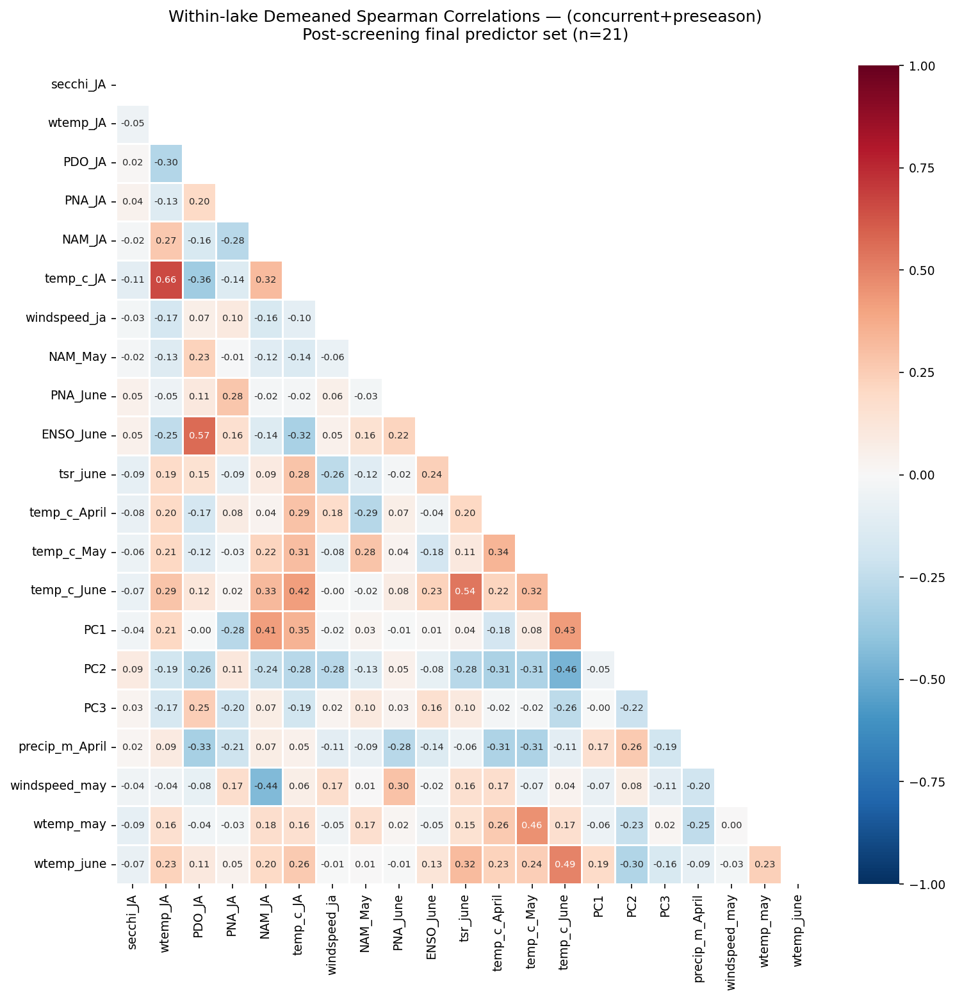


PREDICTOR_COLS (main model base): 21 predictors
['secchi_JA', 'wtemp_JA', 'PDO_JA', 'PNA_JA', 'NAM_JA', 'temp_c_JA', 'windspeed_ja', 'NAM_May', 'PNA_June', 'ENSO_June', 'tsr_june', 'temp_c_April', 'temp_c_May', 'temp_c_June', 'PC1', 'PC2', 'PC3', 'precip_m_April', 'windspeed_may', 'wtemp_may', 'wtemp_june']
sig_concurrent : 7 — ['secchi_JA', 'wtemp_JA', 'PDO_JA', 'PNA_JA', 'NAM_JA', 'temp_c_JA', 'windspeed_ja']
sig_preds      : 14 — ['NAM_May', 'PNA_June', 'ENSO_June', 'tsr_june', 'temp_c_April', 'temp_c_May', 'temp_c_June', 'PC1', 'PC2', 'PC3', 'precip_m_April', 'windspeed_may', 'wtemp_may', 'wtemp_june']
Unaccounted    : 0 — []


In [72]:
# Collinearity screening  ──────────────────────
print('\nPairwise correlation screening (|r| > 0.70 = redundant)')

# Use within-lake demeaned values
df_screen          = df_raw[['lagoslakeid'] + keep_corr].copy()
df_screen[keep_corr] = df_screen[keep_corr].apply(pd.to_numeric, errors='coerce')

df_demeaned          = df_screen.copy()
df_demeaned[keep_corr] = (
    df_screen[keep_corr]
    - df_screen.groupby('lagoslakeid')[keep_corr].transform('mean')
)
corr_matrix = df_demeaned[keep_corr].corr(method='spearman').abs()


high_corr_pairs = []
cols = corr_matrix.columns.tolist()
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        r = corr_matrix.iloc[i, j]
        if r > 0.70:
            high_corr_pairs.append((cols[i], cols[j], r))
high_corr_pairs.sort(key=lambda x: -x[2])

print(f'\nHighly correlated pairs (|r| > 0.70):')
for a, b, r in high_corr_pairs:
    print(f'  {a:<30s} — {b:<30s}  r={r:.3f}')

PRESEASON = {'may', 'june', 'april'}

def is_preseason(col):
    return any(s in col.lower() for s in PRESEASON)

dropped_corr = set()
for a, b, r in high_corr_pairs:
    if a in dropped_corr or b in dropped_corr:
        continue

    # Use within-lake r 
    r_a = within_r_lookup.get(a, 0)
    r_b = within_r_lookup.get(b, 0)

    if abs(r_a - r_b) < 0.001:   # if tied prefer preseason
        if is_preseason(a) and not is_preseason(b):
            drop, keep_col = b, a
        elif is_preseason(b) and not is_preseason(a):
            drop, keep_col = a, b
        else:
            drop, keep_col = a, b
    else:
        drop     = a if r_a < r_b else b
        keep_col = b if drop == a else a

    dropped_corr.add(drop)
    print(f'  Dropping {drop} (|mean_r|={min(r_a,r_b):.3f}) '
          f'in favour of {keep_col} (|mean_r|={max(r_a,r_b):.3f})')

final_preds = [c for c in keep_corr if c not in dropped_corr]
print(f'\nDropped for redundancy : {len(dropped_corr)} — {list(dropped_corr)}')
print(f'Final predictor set    : {len(final_preds)}')
print(final_preds)

# Pairwise correlation heatmap on final predictor set ───────────────────────
# Use demeaned values to match what the collinearity screen actually used

df_heatmap = df_raw[['lagoslakeid'] + final_preds].copy()
df_heatmap[final_preds] = df_heatmap[final_preds].apply(pd.to_numeric, errors='coerce')
df_heatmap[final_preds] = (
    df_heatmap[final_preds]
    - df_heatmap.groupby('lagoslakeid')[final_preds].transform('mean')
)
corr_matrix_final = df_heatmap[final_preds].corr(method='spearman')

fig, ax = plt.subplots(figsize=(max(8, len(final_preds) * 0.5),
                                max(6, len(final_preds) * 0.5)))
heatmap_mask = np.triu(np.ones_like(corr_matrix_final, dtype=bool))
sns.heatmap(corr_matrix_final, mask=heatmap_mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=ax, annot_kws={'size': 7})
ax.set_title(f'Within-lake Demeaned Spearman Correlations — ({MODEL_MODE})\n'
             f'Post-screening final predictor set (n={len(final_preds)})\n')
plt.tight_layout()

plt.savefig(
    "FinalPredictorsCorrelationMap.png",
    dpi=900,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

# Split screened predictors back into concurrent / preseason ────────────────

sig_concurrent = [c for c in final_preds if c in CONCURRENT_COLS]
sig_preds      = [c for c in final_preds if c in PRESEASON_COLS]

accounted_for = set(sig_concurrent) | set(sig_preds)
lost = [c for c in final_preds if c not in accounted_for]
if lost:
    print(f'WARNING: {len(lost)} predictor(s) in final_preds not in either '
          f'CONCURRENT_COLS or PRESEASON_COLS — they will be DROPPED:\n  {lost}')

if MODEL_MODE == 'concurrent':
    PREDICTOR_COLS = sig_concurrent
elif MODEL_MODE == 'concurrent+preseason':
    PREDICTOR_COLS = sig_concurrent + sig_preds
elif MODEL_MODE == 'preseason+concurrent':
    PREDICTOR_COLS = sig_preds + sig_concurrent

print(f'\nPREDICTOR_COLS (main model base): {len(PREDICTOR_COLS)} predictors')
print(PREDICTOR_COLS)
print(f'sig_concurrent : {len(sig_concurrent)} — {sig_concurrent}')
print(f'sig_preds      : {len(sig_preds)} — {sig_preds}')
print(f'Unaccounted    : {len(lost)} — {lost}')

In [73]:
#Double check PCs vs climate index correlations within demeaned matrix to make sure no strong collinearity 

#manually enter here
check_pairs = [('PC1', 'PNA_JA'), ('PC1', 'PDO_JA'), ('PC1', 'NAM_JA'), ('PC1', 'PNA_June'), ('PC1', 'ENSO_June'), ('PC1', 'NAM_May'),
               ('PC2', 'PNA_JA'), ('PC2', 'PDO_JA'), ('PC2', 'NAM_JA'), ('PC2', 'PNA_June'),  ('PC2', 'ENSO_June'), ('PC2', 'NAM_May'),
              ('PC3', 'PNA_JA'), ('PC3', 'PDO_JA'), ('PC3', 'NAM_JA'), ('PC3', 'PNA_June'), ('PC3', 'ENSO_June'), ('PC3', 'NAM_May'),]

for a, b in check_pairs:
    if a in final_preds and b in final_preds:
        r = df_demeaned[[a, b]].corr(method='spearman').iloc[0, 1]
        print(f'{a} — {b}: r = {r:.3f}')

PC1 — PNA_JA: r = -0.276
PC1 — PDO_JA: r = -0.004
PC1 — NAM_JA: r = 0.414
PC1 — PNA_June: r = -0.006
PC1 — ENSO_June: r = 0.012
PC1 — NAM_May: r = 0.031
PC2 — PNA_JA: r = 0.111
PC2 — PDO_JA: r = -0.258
PC2 — NAM_JA: r = -0.239
PC2 — PNA_June: r = 0.051
PC2 — ENSO_June: r = -0.080
PC2 — NAM_May: r = -0.134
PC3 — PNA_JA: r = -0.196
PC3 — PDO_JA: r = 0.246
PC3 — NAM_JA: r = 0.072
PC3 — PNA_June: r = 0.033
PC3 — ENSO_June: r = 0.159
PC3 — NAM_May: r = 0.095


In [74]:
#double check there are no duplicated columns

dupes = [c for c, n in Counter(keep_corr).items() if n > 1]
print("Duplicate columns in keep_corr:", dupes)

# Also check df_raw itself
dupes_raw = [c for c, n in Counter(df_raw.columns.tolist()).items() if n > 1]
print("Duplicate columns in df_raw    :", dupes_raw)

Duplicate columns in keep_corr: []
Duplicate columns in df_raw    : []


# 4. Data Filtering & Validation


In [75]:
# Filter to columns we need ────────────────────────────────────────────────
keep_cols = ([LAKE_COL, YEAR_COL, TARGET_COL] 
             + sig_concurrent   # screened concurrent
             + sig_preds        # screened preseason
             + LAKE_CHAR_COLS)

keep_cols = [c for c in dict.fromkeys(keep_cols) if c in df_raw.columns]
df = df_raw[keep_cols].copy().reset_index(drop=True)

# Drop rows with missing target FIRST ──────────────────────────────────────
df = df.dropna(subset=[TARGET_COL]).reset_index(drop=True)

# THEN filter lakes with MIN_YEARS or more ─────────────────────────────────
years_per_lake = df.groupby(LAKE_COL)[YEAR_COL].count()
lakes_keep     = years_per_lake[years_per_lake >= MIN_YEARS].index
n_before       = df[LAKE_COL].nunique()
df = df[df[LAKE_COL].isin(lakes_keep)].reset_index(drop=True)

# Report ───────────────────────────────────────────────────────────────────
years_per_lake_filt = df.groupby(LAKE_COL)[YEAR_COL].count()
print('=' * 55)
print('  DATA SUMMARY')
print('=' * 55)
print(f'Lakes (before filter) : {n_before}')
print(f'Lakes (≥{MIN_YEARS} years)    : {df[LAKE_COL].nunique()}')
print(f'Observations          : {len(df):,}')
print(f'Years                 : {df[YEAR_COL].min()}–{df[YEAR_COL].max()}')
print(f'Median yrs/lake       : {years_per_lake_filt.median():.0f}')
print(f'Min yrs/lake          : {years_per_lake_filt.min()}')
print(f'Max yrs/lake          : {years_per_lake_filt.max()}')

# Zero-inflation report ────────────────────────────────────────────────────
n_zeros     = (df[TARGET_COL] == 0).sum()
pct_zeros   = n_zeros / len(df) * 100
n_nonzero   = (df[TARGET_COL] > 0).sum()

print(f'\nTarget: {TARGET_COL}')
print(f'  Mean  : {df[TARGET_COL].mean():.3f}')
print(f'  SD    : {df[TARGET_COL].std():.3f}')
print(f'  Range : [{df[TARGET_COL].min():.3f}, {df[TARGET_COL].max():.3f}]')
print(f'  Zeros : {n_zeros} ({pct_zeros:.1f}%)')
print(f'  >0    : {n_nonzero} ({100-pct_zeros:.1f}%)')

# Zero rate by year
zero_by_year = df.groupby(YEAR_COL)[TARGET_COL].apply(
    lambda x: (x == 0).mean()).sort_values(ascending=False)
print(f'\nHigh-zero years (>50% lakes with no habitat):')
print(zero_by_year[zero_by_year > 0.5].round(2).to_string())

# Lakes where >50% of years are zero
lake_zero_pct = df.groupby(LAKE_COL)[TARGET_COL].apply(
    lambda x: (x==0).mean())
print(f'\nLakes where >50% of years are zero: '
      f'{(lake_zero_pct > 0.5).sum()}')
print(f'Lakes where 0% of years are zero : '
      f'{(lake_zero_pct == 0).sum()}')

  DATA SUMMARY
Lakes (before filter) : 452
Lakes (≥3 years)    : 342
Observations          : 2,627
Years                 : 1980–2019
Median yrs/lake       : 5
Min yrs/lake          : 3
Max yrs/lake          : 33

Target: Norm_VHT
  Mean  : 0.208
  SD    : 0.295
  Range : [0.000, 1.000]
  Zeros : 834 (31.7%)
  >0    : 1793 (68.3%)

High-zero years (>50% lakes with no habitat):
year
1988   0.6200
1987   0.6100
1983   0.5800
2016   0.5000

Lakes where >50% of years are zero: 84
Lakes where 0% of years are zero : 138


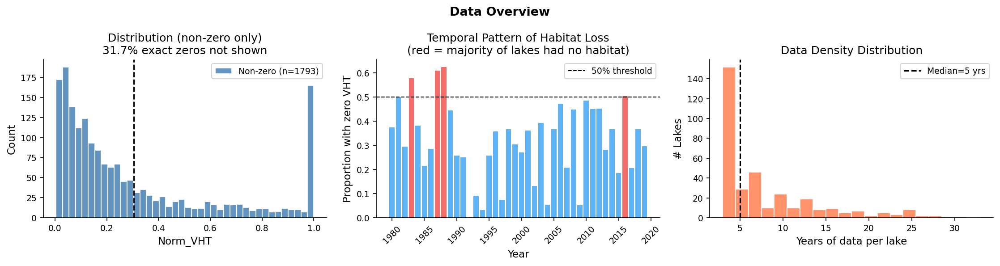

Saved: 00_data_overview.png


In [76]:
# Visualise target distribution & zero pattern ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Target histogram
axes[0].hist(df[TARGET_COL][df[TARGET_COL] > 0], bins=40,
             color='steelblue', edgecolor='white', alpha=0.85,
             label=f'Non-zero (n={n_nonzero})')
axes[0].axvline(df[TARGET_COL][df[TARGET_COL]>0].mean(),
                color='k', lw=1.5, ls='--')
axes[0].set(xlabel=TARGET_COL, ylabel='Count',
            title=f'Distribution (non-zero only)\n'
                  f'{pct_zeros:.1f}% exact zeros not shown')
axes[0].legend(fontsize=9)

# Zero rate by year
zero_by_year_sorted = zero_by_year.sort_index()
bar_colors = ['#EF5350' if z > 0.5 else '#42A5F5'
              for z in zero_by_year_sorted]
axes[1].bar(zero_by_year_sorted.index, zero_by_year_sorted.values,
            color=bar_colors, edgecolor='none', alpha=0.85)
axes[1].axhline(0.5, color='k', lw=1, ls='--',
                label='50% threshold')
axes[1].set(xlabel='Year', ylabel='Proportion with zero VHT',
            title='Temporal Pattern of Habitat Loss\n'
                  '(red = majority of lakes had no habitat)')
axes[1].legend(fontsize=9)
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=45)

# Years per lake
axes[2].hist(years_per_lake_filt.values, bins=20,
             color='coral', edgecolor='white', alpha=0.85)
axes[2].axvline(years_per_lake_filt.median(), color='k',
                lw=1.5, ls='--',
                label=f'Median={years_per_lake_filt.median():.0f} yrs')
axes[2].set(xlabel='Years of data per lake', ylabel='# Lakes',
            title='Data Density Distribution')
axes[2].legend(fontsize=9)

plt.suptitle('Data Overview',
             fontsize=13, fontweight='bold')
plt.tight_layout()
#fig.savefig('data_overview.png', bbox_inches='tight', dpi=180)
plt.show()
print('Saved: data_overview.png')

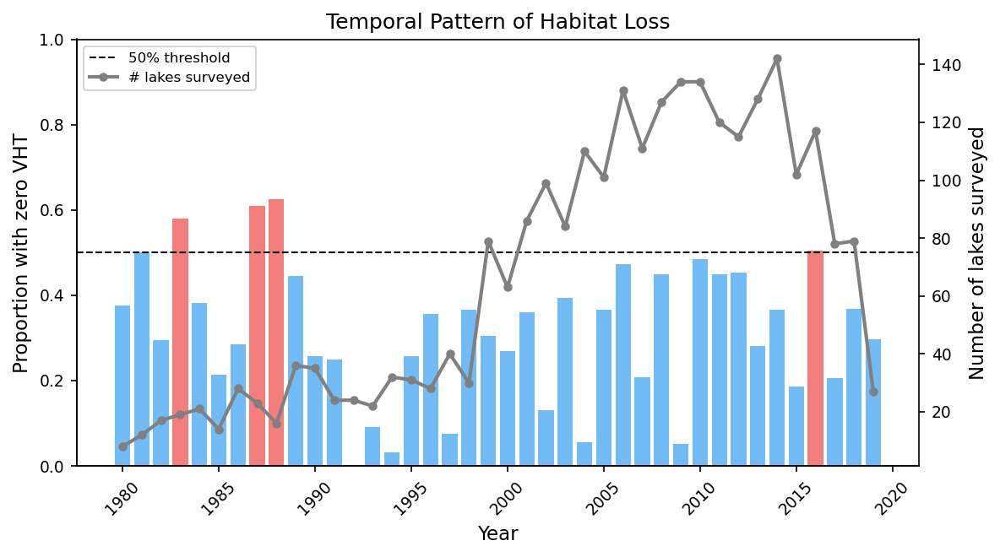

Saved: TemporalPatternOfHabitatLoss.png


In [77]:
#Prepare another plot

# Prepare data
zero_by_year_sorted = zero_by_year.sort_index()
lakes_per_year = df.groupby('year')[LAKE_COL].nunique().sort_index()

# Colors for bars
bar_colors = ['#EF5350' if z > 0.5 else '#42A5F5'
              for z in zero_by_year_sorted]
# Create standalone figure
fig, ax = plt.subplots(figsize=(8, 4.5))
ax_twin = ax.twinx()

# Bar plot (zero proportion)
ax.bar(zero_by_year_sorted.index, zero_by_year_sorted.values,
       color=bar_colors, edgecolor='none', alpha=0.75)
ax.axhline(0.5, color='k', lw=1, ls='--', label='50% threshold')
ax.set(
    xlabel='Year',
    ylabel='Proportion with zero VHT',
    title='Temporal Pattern of Habitat Loss'
)
ax.set_ylim(0, 1)
ax.spines['top'].set_visible(True)
ax_twin.spines['right'].set_visible(True)

# Rotate x labels
plt.setp(ax.get_xticklabels(), rotation=45)

# Line plot (number of lakes)
ax_twin.plot(lakes_per_year.index, lakes_per_year.values,
             color='grey', lw=2, marker='o', markersize=4,
             label='# lakes surveyed')
ax_twin.set_ylabel('Number of lakes surveyed')

# Legends (combine both axes)
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax_twin.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2,
          fontsize=8, loc='upper left')
plt.tight_layout()
fig.savefig('TemporalPatternOfHabitatLoss.png', bbox_inches='tight', dpi=180)
plt.show()

print('Saved: TemporalPatternOfHabitatLoss.png')

### Variance Partitioning (ICC)

Quantifies how much variance in Norm_VHT is between lakes (fixed lake identity) vs within lakes

The random intercept in the LMM absorbs the between-lake component

In [78]:
between_var = df[TARGET_COL].groupby(df[LAKE_COL]).mean().var()
within_var  = df[TARGET_COL].groupby(df[LAKE_COL]).var().mean()
icc         = between_var / (between_var + within_var)

print('=' * 55)
print('  VARIANCE PARTITIONING')
print('=' * 55)
print(f'Between-lake variance : {between_var:.4f}  ({icc*100:.1f}%)')
print(f'Within-lake variance  : {within_var:.4f}  ({(1-icc)*100:.1f}%)')
print(f'ICC                   : {icc:.3f}')
print(f'\n→ {icc*100:.1f}% of variance is fixed lake identity')
print(f'  (absorbed by random intercept in LMM)')
print(f'→ {(1-icc)*100:.1f}% is interannual variation')
print(f'  (what climate predictors can explain)')

# Null model LMM to confirm ICC matches
m_null    = smf.mixedlm(f"{TARGET_COL} ~ 1", data=df,
                         groups=df[LAKE_COL])
r_null_ml = m_null.fit(reml=False)
r_null_re = m_null.fit(reml=True)

var_lake  = r_null_re.cov_re.iloc[0, 0]
var_resid = r_null_re.scale
icc_lmm   = var_lake / (var_lake + var_resid)

print(f'\nLMM null model confirmation:')
print(f'  Random intercept variance: {var_lake:.4f}')
print(f'  Residual variance        : {var_resid:.4f}')
print(f'  ICC from LMM             : {icc_lmm:.3f}')

  VARIANCE PARTITIONING
Between-lake variance : 0.0694  (66.2%)
Within-lake variance  : 0.0354  (33.8%)
ICC                   : 0.662

→ 66.2% of variance is fixed lake identity
  (absorbed by random intercept in LMM)
→ 33.8% is interannual variation
  (what climate predictors can explain)

LMM null model confirmation:
  Random intercept variance: 0.0626
  Residual variance        : 0.0317
  ICC from LMM             : 0.664


### Standardize Predictors

Standardize all predictors to mean=0, SD=1.  

In [79]:
# All predictors present in data — screened concurrent + screened preseason
all_pred_cols = ([c for c in sig_concurrent if c in df.columns]
                 + [c for c in sig_preds if c in df.columns])

df_scaled = df.copy()
scaler_means, scaler_sds = {}, {}
dropped_cols = []

for col in all_pred_cols:
    sd = df[col].std()
    if sd == 0 or df[col].isna().all():
        print(f'Dropping {col} — zero variance or all NaN')
        dropped_cols.append(col)
        continue
    scaler_means[col] = df[col].mean()
    scaler_sds[col]   = sd
    df_scaled[col]    = (df[col] - scaler_means[col]) / sd

all_pred_cols = [c for c in all_pred_cols if c not in dropped_cols]

# Add binary presence/absence variable for GEE model
df_scaled['VHT_present'] = (df_scaled[TARGET_COL] > 0).astype(int)

# Standardize year for trend covariate
df_scaled['year_std'] = ((df_scaled[YEAR_COL] - df_scaled[YEAR_COL].mean())
                          / df_scaled[YEAR_COL].std())

print(f'Predictors available : {len(all_pred_cols)}')
if dropped_cols:
    print(f'Dropped              : {dropped_cols}')
print(f'Presence/absence col : VHT_present')
print(f'Year (standardized)  : year_std')
print(f'\ndf_scaled shape: {df_scaled.shape}')

# Filter groups to only available columns
PREDICTOR_GROUPS = {k: [c for c in v if c in df_scaled.columns]
                    for k, v in PREDICTOR_GROUPS.items()}
PREDICTOR_GROUPS = {k: v for k, v in PREDICTOR_GROUPS.items() if v}
print(f'\nPredictor groups:')
for grp, cols in PREDICTOR_GROUPS.items():
    print(f'  {grp:<25s}: {len(cols)} predictors')

Predictors available : 21
Presence/absence col : VHT_present
Year (standardized)  : year_std

df_scaled shape: (2627, 35)

Predictor groups:
  Concurrent (JA)          : 7 predictors
  Large-scale climate      : 7 predictors
  Local climate            : 5 predictors
  In-lake conditions       : 2 predictors


# 5. Hurdle Model Part 1 — Presence/Absence (GEE Logistic)

GEE (Generalized Estimating Equations) with exchangeable correlation structure

In [80]:
# Convert any nullable Float64 columns to standard float64
df_scaled = df_scaled.copy()
for col in df_scaled.select_dtypes(include='Float64').columns:
    df_scaled[col] = df_scaled[col].astype('float64')

df_scaled = df_scaled.sort_values([LAKE_COL, 'year']).reset_index(drop=True)

# Predictors for presence/absence
pa_preds = [c for c in final_preds if c in df_scaled.columns]
formula_pa = "VHT_present ~ " + " + ".join(pa_preds)

print(f'Part 1 predictors: {len(pa_preds)}')
print(f'Response: VHT_present (0/1)')
print(f'N obs: {len(df_scaled)}')
print(f'N zeros: {(df_scaled.VHT_present==0).sum()}')
print(f'N ones : {(df_scaled.VHT_present==1).sum()}')

Part 1 predictors: 21
Response: VHT_present (0/1)
N obs: 2627
N zeros: 834
N ones : 1793


In [81]:
# first, VIF check/cleanup directly on the full predictor set now that we have removed years with 0

def calculate_vif(df, predictors):
    X = df[predictors].copy()
    X = sm.add_constant(X)
    vif_data = pd.DataFrame()
    vif_data['predictor'] = X.columns
    vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif_data[vif_data['predictor'] != 'const'].sort_values('VIF', ascending=False)

def drop_high_vif(df, predictors, threshold=5.0, verbose=True):
    predictors = list(predictors)
    dropped = []
    while True:
        vif_df = calculate_vif(df, predictors)
        max_vif = vif_df['VIF'].max()
        if max_vif < threshold:
            break
        worst = vif_df.loc[vif_df['VIF'].idxmax(), 'predictor']
        dropped.append((worst, max_vif))
        predictors.remove(worst)
        if verbose:
            print(f'Dropping {worst} (VIF={max_vif:.2f}) — {len(predictors)} predictors remain')
    if verbose:
        print(f'\nFinal predictor count: {len(predictors)}')
        print(f'Dropped: {[d[0] for d in dropped]}')
    return predictors, dropped

# Run VIF cleanup on the FULL original predictor list
pa_preds_vif_only, dropped_preds_vif_only = drop_high_vif(df_scaled, pa_preds, threshold=5.0)


#fit GEE on the VIF-only reduced set ----------------------------------------------

formula_pa_vif_only = "VHT_present ~ " + " + ".join(pa_preds_vif_only)

model_pa_vif_only = GEE.from_formula(
    formula_pa_vif_only,
    groups=LAKE_COL,
    time=df_scaled['year'].values,
    data=df_scaled,
    family=Binomial(),
    cov_struct=Autoregressive()
)
result_pa_vif_only = model_pa_vif_only.fit()
print('\n', result_pa_vif_only.summary())
print('QIC:', result_pa_vif_only.qic())


#FDR correction on model p-values ------------------------------------------------

pvals = result_pa_vif_only.pvalues.drop('Intercept')
reject, pvals_corrected, _, _ = multipletests(pvals, alpha=0.05, method='fdr_bh')

sig_table_vif_only = pd.DataFrame({
    'coef': result_pa_vif_only.params.drop('Intercept'),
    'std_err': result_pa_vif_only.bse.drop('Intercept'),
    'p_raw': pvals,
    'p_fdr': pvals_corrected,
    'sig_at_0.05_fdr': reject
}).sort_values('p_fdr')

pd.set_option('display.float_format', '{:.4f}'.format)
print('\n', sig_table_vif_only)

Dropping temp_c_June (VIF=8.39) — 20 predictors remain

Final predictor count: 20
Dropped: ['temp_c_June']

                                GEE Regression Results                              
Dep. Variable:                 VHT_present   No. Observations:                 2627
Model:                                 GEE   No. clusters:                      342
Method:                        Generalized   Min. cluster size:                   3
                      Estimating Equations   Max. cluster size:                  33
Family:                           Binomial   Mean cluster size:                 7.7
Dependence structure:       Autoregressive   Num. iterations:                    19
Date:                     Tue, 06 Oct 2026   Scale:                           1.000
Covariance type:                    robust   Time:                         12:08:15
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------

Plotting 8 FDR-significant term(s): ['secchi_JA', 'wtemp_JA', 'ENSO_June', 'windspeed_may', 'NAM_May', 'PNA_June', 'PC1', 'PDO_JA']
Saved: SupFig7_GEE_marginal_effects.png


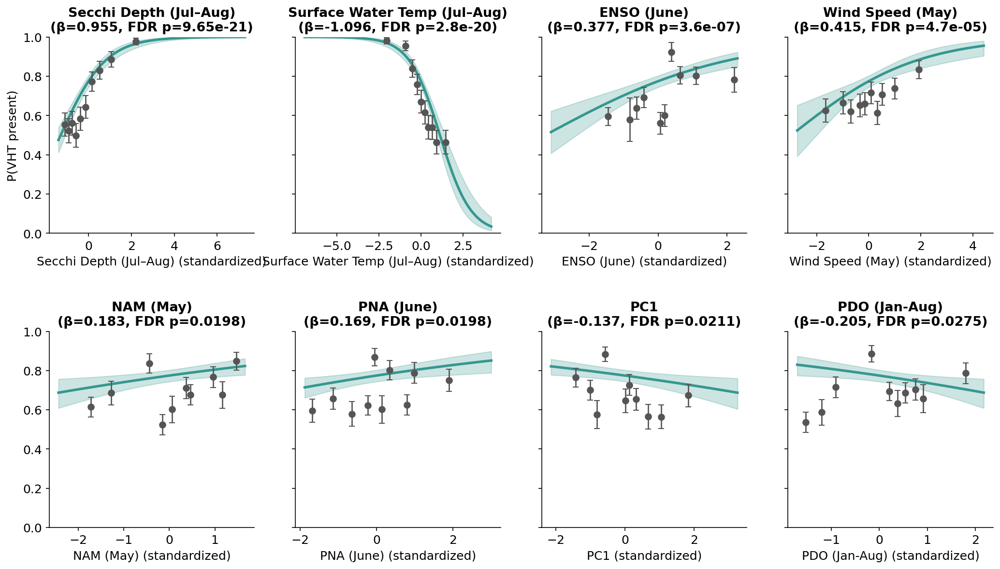

In [82]:
# Supplementral info figure — marginal effects, presence/absence GEE (VIF-reduced)

#plots the GEE's predicted probability with a 95% CI built via the delta method on the linear
#then overlays binned observed proportions 

#set plot sizes
FS_LABEL, FS_TICK, FS_TITLE = 12, 12, 15

PRETTY = {
    'precip_m_April_between': 'Total Precipitation (April)',
    'temp_c_June_within':     'Air Temperature (June)',
    'tsr_june_within':        'Total Solar Radiation (June)',
    'wtemp_JA_between':       'Surface Water Temperature (July-Aug)',
    'wtemp_JA_within':        'Surface Water Temperature (July-Aug)',
    'PDO_JA':                 'PDO (Jan-Aug)',
    'NAM_May':                'NAM (May)',
    'PNA_June':                'PNA (June)',
    'ENSO_June':               'ENSO (June)',
    'secchi_JA':              'Secchi Depth (Jul–Aug)',
    'wtemp_JA':               'Surface Water Temp (Jul–Aug)',
    'windspeed_may':          'Wind Speed (May)',
}

sig_terms = sig_table_vif_only.index[sig_table_vif_only['sig_at_0.05_fdr']].tolist()
print(f"Plotting {len(sig_terms)} FDR-significant term(s): {sig_terms}")

N_BINS = 10  #deciles; drop to 6-8 if a predictor has few unique values

var_pal = sns.color_palette('BrBG', n_colors=9)
line_color, point_color = var_pal[7], '#555555'

params = result_pa_vif_only.params
cov = result_pa_vif_only.cov_params()
rhs_formula = model_pa_vif_only.formula.split('~', 1)[1]
means = df_scaled[pa_preds_vif_only].mean()

ncols = 4
nrows = int(np.ceil(len(sig_terms) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(4.2 * ncols, 4.4 * nrows),
    sharey=True
)

fig.subplots_adjust(hspace=0.5)

axes = np.atleast_1d(axes).ravel()

if len(sig_terms) == 1:
    axes = [axes]

for i, col in enumerate(sig_terms):
    ax = axes[i]
    x_range = np.linspace(df_scaled[col].min(), df_scaled[col].max(), 100)

    #design matrix: every other predictor held at its mean, `col` swept
    X_pred_df = pd.DataFrame({p: np.full(100, means[p]) for p in pa_preds_vif_only})
    X_pred_df[col] = x_range
    X_pred = dmatrix(rhs_formula, data=X_pred_df, return_type='dataframe')
    X_pred = X_pred[params.index]  

    eta = X_pred.values @ params.values
    se_eta = np.sqrt(np.einsum('ij,jk,ik->i', X_pred.values, cov.values, X_pred.values))
    p_hat = expit(eta)
    p_lo  = expit(eta - 1.96 * se_eta)
    p_hi  = expit(eta + 1.96 * se_eta)

    ax.plot(x_range, p_hat, color=line_color, lw=2.5, zorder=3)
    ax.fill_between(x_range, p_lo, p_hi, color=line_color, alpha=0.25, zorder=2)

    #binned observed proportions, with binomial SE
    tmp = df_scaled[[col, 'VHT_present']].dropna().copy()
    tmp['bin'] = pd.qcut(tmp[col], q=N_BINS, duplicates='drop')
    binned = (
        tmp.groupby('bin', observed=True)
        .agg(x_mean=(col, 'mean'), prop=('VHT_present', 'mean'), n=('VHT_present', 'size'))
        .reset_index(drop=True)
    )
    binned['se'] = np.sqrt(binned['prop'] * (1 - binned['prop']) / binned['n'])
    ax.errorbar(binned['x_mean'], binned['prop'], yerr=1.96 * binned['se'],
                fmt='o', color=point_color, ecolor=point_color, elinewidth=1.3,
                capsize=3, markersize=6, zorder=4)

    b = sig_table_vif_only.loc[col, 'coef']
    p_fdr = sig_table_vif_only.loc[col, 'p_fdr']
    ax.set_title(f'{PRETTY.get(col, col)}\n(\u03b2={b:.3f}, FDR p={p_fdr:.3g})',
                 fontsize=FS_TITLE - 2, fontweight='bold')
    ax.set_xlabel(f'{PRETTY.get(col, col)} (standardized)', fontsize=FS_LABEL)
    if i == 0:
        ax.set_ylabel('P(VHT present)', fontsize=FS_LABEL)
    ax.set_ylim(0, 1)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right']].set_visible(False)

fig.savefig('SupFig7_GEE_marginal_effects.png', bbox_inches='tight', dpi=300)
print('Saved: SupFig7_GEE_marginal_effects.png')

Base rate of VHT presence across all lake-years: 0.683 (colormap centered here)
Saved: Figure12_climate_response_surfaces_PA.png


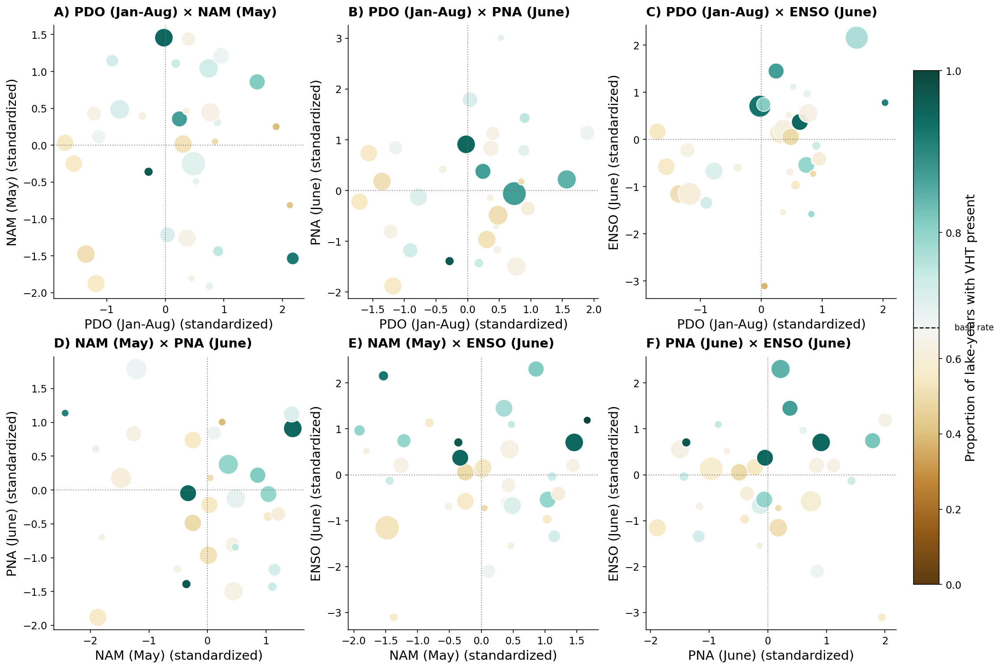

In [83]:
#exploratory figure ---------------------

#bins lake-years by pairs of climate indices and shows the observed proportion of VHT presence in each bin

FS_LABEL, FS_TICK, FS_TITLE = 14, 11, 15

CLIMATE_LABELS = {
    'PDO_JA':    'PDO (Jan-Aug)',
    'NAM_May':   'NAM (May)',
    'PNA_June':  'PNA (June)',
    'ENSO_June': 'ENSO (June)',
}
PAIRS = [
    ('PDO_JA', 'NAM_May'), ('PDO_JA', 'PNA_June'), ('PDO_JA', 'ENSO_June'),
    ('NAM_May', 'PNA_June'), ('NAM_May', 'ENSO_June'), ('PNA_June', 'ENSO_June'),
]

N_BINS = 8            
MIN_N_PER_BIN = 5      
TARGET_COL = 'VHT_present'

cmap = 'BrBG'

# Center the diverging palette on the actual base rate of VHT presence
base_rate = df_scaled[TARGET_COL].mean()
norm = mcolors.TwoSlopeNorm(vmin=0, vcenter=base_rate, vmax=1)
print(f"Base rate of VHT presence across all lake-years: {base_rate:.3f} "
      f"(colormap centered here)")

fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
axes = axes.flatten()

for panel, (x_col, y_col) in enumerate(PAIRS):
    ax = axes[panel]
    tmp = df_scaled[[x_col, y_col, TARGET_COL]].dropna().copy()

    tmp['x_bin'] = pd.qcut(tmp[x_col], q=N_BINS, labels=False, duplicates='drop')
    tmp['y_bin'] = pd.qcut(tmp[y_col], q=N_BINS, labels=False, duplicates='drop')

    summary = (
        tmp.groupby(['x_bin', 'y_bin'])
        .agg(prop_present=(TARGET_COL, 'mean'), n=(TARGET_COL, 'count'),
             x=(x_col, 'median'), y=(y_col, 'median'))
        .reset_index()
    )
    summary = summary[summary['n'] >= MIN_N_PER_BIN]

    sc = ax.scatter(
        summary['x'], summary['y'], c=summary['prop_present'],
        s=np.clip(summary['n'] * 3, 60, 700),
        cmap=cmap, norm=norm,
        edgecolors='white', linewidth=0.9, alpha=0.95,
    )

    ax.axvline(0, color='#777777', lw=1, ls=':', alpha=0.8)
    ax.axhline(0, color='#777777', lw=1, ls=':', alpha=0.8)
    ax.set_xlabel(f'{CLIMATE_LABELS[x_col]} (standardized)', fontsize=FS_LABEL)
    ax.set_ylabel(f'{CLIMATE_LABELS[y_col]} (standardized)', fontsize=FS_LABEL)
    ax.set_title(f'{chr(65+panel)}) {CLIMATE_LABELS[x_col]} \u00d7 {CLIMATE_LABELS[y_col]}',
                 loc='left', fontsize=FS_TITLE - 1, fontweight='bold', pad=10)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right']].set_visible(False)

cbar = fig.colorbar(sc, ax=axes, shrink=0.85, pad=0.02)
cbar.set_label('Proportion of lake-years with VHT present', fontsize=FS_LABEL)
cbar.ax.tick_params(labelsize=FS_TICK)
cbar.ax.axhline(base_rate, color='black', lw=1.2, ls='--')
cbar.ax.text(1.6, base_rate, 'base rate', fontsize=9, va='center', transform=cbar.ax.get_yaxis_transform())

fig.savefig('climate_response_surfaces_PA.png', bbox_inches='tight', dpi=300)
print('Saved: climate_response_surfaces_PA.png')

In [84]:
#Extract and format Part 1 results ───────────────────────────────────────
pa_table = pd.DataFrame({
    'log_odds':   result_pa_vif_only.params,
    'se':         result_pa_vif_only.bse,
    'p':          result_pa_vif_only.pvalues,
    'OR':         np.exp(result_pa_vif_only.params),
    'OR_ci_low':  np.exp(result_pa_vif_only.conf_int().iloc[:, 0]),
    'OR_ci_high': np.exp(result_pa_vif_only.conf_int().iloc[:, 1]),
}).drop(index='Intercept', errors='ignore')

pa_table['significant'] = pa_table['p'] < 0.05
pa_table['direction']   = pa_table['log_odds'].apply(
    lambda x: 'Increases habitat probability' if x > 0
              else 'Decreases habitat probability')
pa_table = pa_table.sort_values('p')

print('Part 1 — Presence/Absence Results')
print('(OR > 1 = increases probability of habitat, OR < 1 = decreases)')
print(pa_table[['OR','OR_ci_low','OR_ci_high','p','significant']]
      .round(3).to_string())

sig_pa = pa_table[pa_table['p'] < 0.05]
print(f'\nSignificant predictors (p<0.05): {len(sig_pa)}')
print(f'Top 3: {sig_pa.head(3).index.tolist()}')

pa_plot = pa_table.sort_values('OR')  # sort by OR so forest plot reads low→high
y = range(len(pa_plot))
colors = ['#EF5350' if s else '#90A4AE' for s in pa_plot['significant']]

Part 1 — Presence/Absence Results
(OR > 1 = increases probability of habitat, OR < 1 = decreases)
                   OR  OR_ci_low  OR_ci_high      p  significant
secchi_JA      2.5990     2.1410      3.1550 0.0000         True
wtemp_JA       0.3340     0.2660      0.4190 0.0000         True
ENSO_June      1.4580     1.2730      1.6710 0.0000         True
windspeed_may  1.5140     1.2600      1.8180 0.0000         True
PNA_June       1.1840     1.0510      1.3340 0.0060         True
NAM_May        1.2010     1.0540      1.3690 0.0060         True
PC1            0.8720     0.7890      0.9640 0.0070         True
PDO_JA         0.8150     0.6960      0.9540 0.0110         True
NAM_JA         1.1190     0.9890      1.2670 0.0750        False
wtemp_june     0.9270     0.8130      1.0580 0.2610        False
PC2            0.9280     0.8110      1.0620 0.2780        False
PC3            1.0490     0.9580      1.1480 0.2990        False
temp_c_April   0.9220     0.7840      1.0840 0.3250      

In [85]:
# Create table for supplemental materials────────────────────────────────────

print('\nGEE MODEL INFORMATION')
print(f'Response: VHT_present')
print(f'Observations: {len(df_scaled)}')
print(f'Groups (lakes): {df_scaled[LAKE_COL].nunique()}')
print(f'Zeros: {(df_scaled.VHT_present == 0).sum()}')
print(f'Ones: {(df_scaled.VHT_present == 1).sum()}')
print(f'Number of predictors: {len(pa_preds_vif_only)}')
print(f'Correlation structure: Autoregressive (AR-1)')
print(f'Family: Binomial')
print(f'Link: Logit')

word_table = pa_table[
    ['log_odds', 'se', 'p', 'OR', 'OR_ci_low', 'OR_ci_high',
     'significant', 'direction']
].copy()

# Rename columns for readability
word_table.columns = [
    'Log odds', 'SE', 'p-value', 'Odds ratio',
    'OR 95% CI low', 'OR 95% CI high',
    'Significant (p < 0.05)', 'Direction'
]

# Round numerical values
word_table[['Log odds', 'SE', 'p-value', 'Odds ratio',
            'OR 95% CI low', 'OR 95% CI high']] = \
    word_table[['Log odds', 'SE', 'p-value', 'Odds ratio',
                'OR 95% CI low', 'OR 95% CI high']].round(3)

# Put predictor names into the table
word_table.insert(0, 'Predictor', word_table.index)

# Print as tab-separated text
print('\n' + word_table.to_csv(sep='\t', index=False))


GEE MODEL INFORMATION
Response: VHT_present
Observations: 2627
Groups (lakes): 342
Zeros: 834
Ones: 1793
Number of predictors: 20
Correlation structure: Autoregressive (AR-1)
Family: Binomial
Link: Logit

Predictor	Log odds	SE	p-value	Odds ratio	OR 95% CI low	OR 95% CI high	Significant (p < 0.05)	Direction
secchi_JA	0.955	0.099	0.0	2.599	2.141	3.155	True	Increases habitat probability
wtemp_JA	-1.096	0.116	0.0	0.334	0.266	0.419	True	Decreases habitat probability
ENSO_June	0.377	0.069	0.0	1.458	1.273	1.671	True	Increases habitat probability
windspeed_may	0.415	0.094	0.0	1.514	1.26	1.818	True	Increases habitat probability
PNA_June	0.169	0.061	0.006	1.184	1.051	1.334	True	Increases habitat probability
NAM_May	0.183	0.067	0.006	1.201	1.054	1.369	True	Increases habitat probability
PC1	-0.137	0.051	0.007	0.872	0.789	0.964	True	Decreases habitat probability
PDO_JA	-0.205	0.08	0.011	0.815	0.696	0.954	True	Decreases habitat probability
NAM_JA	0.113	0.063	0.075	1.119	0.989	1.267	False	Increases 

In [86]:
# Plot settings ─────────────────────────────────────────────────────────────
SCATTER_ALPHA  = 0.18
SCATTER_SIZE   = 8
LOWESS_FRAC    = 0.35
COL1_COLOR     = '#4A90D9'
COL2_COLOR     = '#E8714A'
COL3_COLOR     = '#5BA85F'
LOWESS_COLOR   = '#1a1a2e'
N_BINS         = 10
CLIMATE_INDICES = {'PDO_JA', 'PNA_JA', 'NAM_JA', 'NAM_May', 'PNA_June', 'ENSO_June'}

# Correct variable names for plots ────────────────────────────────────────────────────
PRED_LABELS = {
    'wtemp_JA'       : 'Surface Water Temp (Jul–Aug)',
    'temp_c_JA'      : 'Air Temp (Jul–Aug)',
    'tsr_ja'         : 'Solar Radiation (Jul–Aug)',
    'windspeed_ja'   : 'Wind Speed (Jul–Aug)',
    'precip_m_JA'   : 'Precipitation (Jul–Aug)',
    'chla_JA'        : 'Chlorophyll-a (Jul–Aug)',
    'secchi_JA'      : 'Secchi Depth (Jul–Aug)',
    'PDO_JA'         : 'PDO Index (Jul–Aug)',
    'ENSO_JA'        : 'ENSO Index (Jul–Aug)',
    'PNA_JA'         : 'PNA Index (Jul–Aug)',
    'NAM_JA'         : 'NAM Index (Jul–Aug)',
    'wtemp_june'     : 'Surface Water Temp (June)',
    'temp_c_June'    : 'Air Temp (June)',
    'tsr_june'       : 'Solar Radiation (June)',
    'windspeed_june' : 'Wind Speed (June)',
    'precip_m_June' : 'Precipitation (June)',
    'chla_june'      : 'Chlorophyll-a (June)',
    'secchi_june'    : 'Secchi Depth (June)',
    'ENSO_June'      : 'ENSO Index (June)',
    'PNA_June'       : 'PNA Index (June)',
    'wtemp_may'      : 'Surface Water Temp (May)',
    'temp_c_May'     : 'Air Temp (May)',
    'windspeed_may'  : 'Wind Speed (May)',
    'precip_m_May'  : 'Precipitation (May)',
    'chla_may'       : 'Chlorophyll-a (May)',
    'secchi_may'     : 'Secchi Depth (May)',
    'NAM_May'        : 'NAM Index (May)',
    'PC1'          :  'PC1 (June)',
    'PC2'          : 'PC2 (June)',
    'PC3'          : 'PC3 (June)',
    'temp_c_April'   : 'Air Temp (April)',
    'precip_m_April': 'Precipitation (April)',
}

def pretty(pred):
    """Return display label for a predictor, falling back to raw name."""
    return PRED_LABELS.get(pred, pred)

def phase_label(val):
    if val < -0.5:   return 'Negative'
    elif val > 0.5:  return 'Positive'
    else:            return 'Neutral'

def fmt_p(p):
    if p < 0.001:
        return f'{p:.2e}'
    else:
        return f'{p:.4f}'

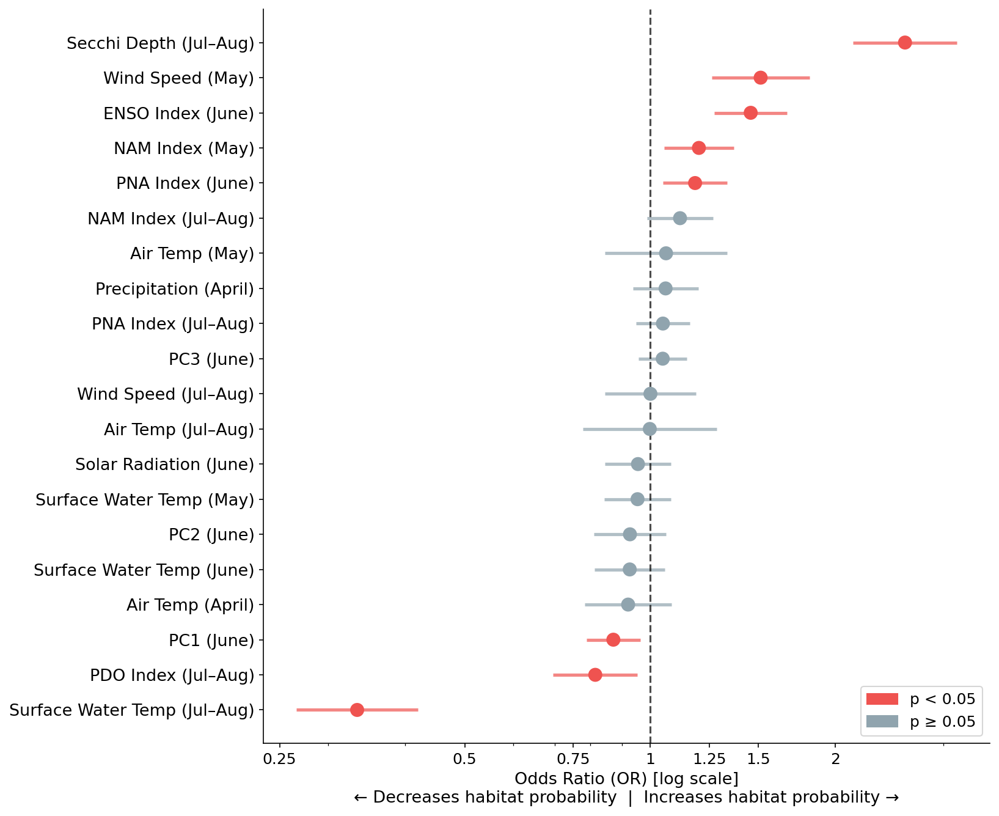

In [87]:
# Forest plot for Odds Ratios ────────────────────────────────────────────────
pa_plot_all = pa_table.sort_values('OR')
y_all = range(len(pa_plot_all))
colors_all = ['#EF5350' if s else '#90A4AE' for s in pa_plot_all['significant']]

fig, ax = plt.subplots(figsize=(11, len(pa_plot_all) * 0.4 + 1))
ax.scatter(pa_plot_all['OR'], y_all, color=colors_all, zorder=3, s=100)
ax.hlines(y_all, pa_plot_all['OR_ci_low'], pa_plot_all['OR_ci_high'], color=colors_all, linewidth=2.5, alpha=0.7)
ax.axvline(1, color='black', lw=1.5, linestyle='--', alpha=0.7)
ax.set_xscale('log')
ax.xaxis.set_major_locator(ticker.FixedLocator([0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:g}'))
ax.xaxis.set_minor_formatter(ticker.NullFormatter())
ax.set_yticks(y_all)
ax.set_yticklabels([pretty(p) for p in pa_plot_all.index], fontsize=13)
ax.set_xlabel('Odds Ratio (OR) [log scale]\n← Decreases habitat probability  |  Increases habitat probability →', fontsize=13)
ax.tick_params(axis='x', labelsize=12)
ax.legend(handles=[Patch(color='#EF5350', label='p < 0.05'), Patch(color='#90A4AE', label='p ≥ 0.05')], fontsize=12, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('GEE_Part1_forest.png', bbox_inches='tight', dpi=180)
plt.show()


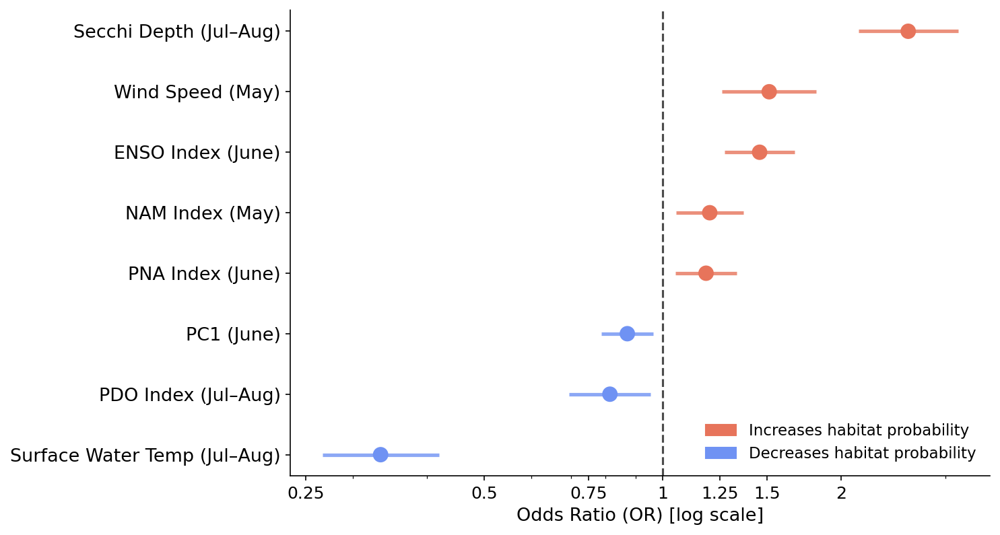

In [88]:
#Publication version

forest_pal = sns.color_palette("coolwarm", n_colors=5)
color_up, color_down = forest_pal[4], forest_pal[0]

pa_plot_sig = pa_table[pa_table['p'] < 0.05].sort_values('OR')
y = range(len(pa_plot_sig))
colors = [color_up if or_val > 1 else color_down for or_val in pa_plot_sig['OR']]
fig, ax = plt.subplots(figsize=(10, len(pa_plot_sig) * 0.55 + 1))
ax.scatter(pa_plot_sig['OR'], y, color=colors, zorder=3, s=100)
ax.hlines(y, pa_plot_sig['OR_ci_low'], pa_plot_sig['OR_ci_high'], color=colors, linewidth=2.5, alpha=0.8)
ax.axvline(1, color='black', lw=1.5, linestyle='--', alpha=0.7)
ax.set_xscale('log')
ax.xaxis.set_major_locator(ticker.FixedLocator([0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:g}'))
ax.set_yticks(y)
ax.set_yticklabels([pretty(p) for p in pa_plot_sig.index], fontsize=13)
ax.set_xlabel('Odds Ratio (OR) [log scale]', fontsize=13)
ax.tick_params(axis='x', labelsize=12)
ax.legend(handles=[
    Patch(color=color_up, label='Increases habitat probability'),
    Patch(color=color_down, label='Decreases habitat probability')
], fontsize=11, loc='lower right', frameon=False)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('GEE_Part1_forest_main.png', bbox_inches='tight', dpi=300)
plt.show()

# 6. Hurdle Model Part 2 — Abundance (Linear Mixed Effects model)


In [91]:
#predictor_between = lake-mean of predictor      (spatial signal)
#predictor_within   = predictor - lake-mean       (interannual signal)

#reset target column
TARGET_COL = 'Norm_VHT'

assert df_nz[TARGET_COL].nunique() > 1, f'{TARGET_COL} is constant in df_nz'
print(df_nz[TARGET_COL].describe())

# ── AICc (small-sample corrected AIC) ──────────────────────────────
# k = fixed effects + RE covariance params + residual variance

# n_mode controls what "n" means in the correction term 2k(k+1)/(n-k-1):
#   'obs'      -> n = total observations (default; standard practice, e.g.
#                 Treats AICc as an approximation under non-independence 
#   'clusters' -> n = number of lakes (groups). More conservative; reflects
#                 that correlated within-lake observations carry less
#                 information than the same count of independent obs would.

def aicc(result, n):
    # Fixed effects
    k_fe = result.k_fe

    # Random-effects covariance parameters: UNIQUE variances + covariances
    p = result.cov_re.shape[0]
    k_re = p * (p + 1) // 2

    # Residual variance
    k_resid = 1

    k = k_fe + k_re + k_resid

    aic_val = result.aic
    denom = n - k - 1

    if denom <= 0:
        return np.inf

    return aic_val + (2 * k * (k + 1)) / denom


def get_n(df, lake_col, n_mode='obs'):
    if n_mode == 'obs':
        return len(df)
    elif n_mode == 'clusters':
        return df[lake_col].nunique()
    else:
        raise ValueError("n_mode must be 'obs' or 'clusters'")


N_MODE = 'obs' 

# make non-zero subset ────────────────────────────────────────────────
df_nz = df_scaled[df_scaled['VHT_present'] == 1].copy().reset_index(drop=True)

nz_counts = df_nz.groupby(LAKE_COL).size()
lakes_1obs = nz_counts[nz_counts < 2].index
df_nz = df_nz[~df_nz[LAKE_COL].isin(lakes_1obs)].reset_index(drop=True)
print(f'Part 2 dataset: {len(df_nz)} obs | {df_nz[LAKE_COL].nunique()} lakes '
      f'(dropped {len(lakes_1obs)} lakes with <2 non-zero obs)')

# within/between decomposition of time-varying predictors ───────

candidate_preds = [c for c in PREDICTOR_COLS if c in df_nz.columns]
missing = [c for c in PREDICTOR_COLS if c not in df_nz.columns]
if missing:
    print(f'Warning: {len(missing)} predictors in PREDICTOR_COLS not found '
          f'in df_nz: {missing}')

within_sd = df_nz.groupby(LAKE_COL)[candidate_preds].transform('std').mean()
overall_sd = df_nz[candidate_preds].std()
time_invariant_flagged = [
    c for c in candidate_preds
    if overall_sd[c] > 0 and (within_sd[c] / overall_sd[c]) <= 0.05
]
if time_invariant_flagged:
    warnings.warn(
        f'{len(time_invariant_flagged)} predictor(s) flagged as effectively '
        f'time-invariant'
        f'{time_invariant_flagged}. Decomposition proceeds anyway, but their '
        f'_within terms will carry ~0 variance and may drop out at the VIF '
        f'or forward-selection step'

    )
else:
    print('\nAll candidate predictors are time-varying.')

decomposed_preds = []
for c in candidate_preds:
    lake_mean_col = f'{c}_between'
    within_col    = f'{c}_within'
    df_nz[lake_mean_col] = df_nz.groupby(LAKE_COL)[c].transform('mean')
    df_nz[within_col]    = df_nz[c] - df_nz[lake_mean_col]
    decomposed_preds += [lake_mean_col, within_col]

full_candidate_set = decomposed_preds

# Collinearity screen via VIF ────────────────────────────────────
#need now that we are looking at ONLY POSITIVE VALUES

def vif_screen(df, preds, thresh=5.0):
    preds = preds.copy()
    while True:
        X = sm.add_constant(df[preds].dropna())
        vifs = pd.Series(
            [variance_inflation_factor(X.values, i)
             for i in range(1, X.shape[1])], 
            index=preds)
        worst = vifs.idxmax()
        if vifs[worst] < thresh or len(preds) <= 1:
            return preds, vifs
        print(f'  Dropping {worst} (VIF={vifs[worst]:.1f})')
        preds.remove(worst)

print('\nVIF screen (threshold = 5):')
screened_preds, final_vifs = vif_screen(df_nz, full_candidate_set)
print(final_vifs.round(2).sort_values(ascending=False).to_string())
print(f'\nPredictors retained after VIF screen: {screened_preds}')

# AICc selection ──────────────────────────────────────────────────

# Adds whichever candidate most improves AICc at each step; stops once nothing passes threshold of 2

def forward_select_aicc(df, candidates, target, group_col, delta_thresh=2.0,
                         n_mode='obs'):
    n = get_n(df, group_col, n_mode)
    selected, remaining = [], list(candidates)
    null_fit = smf.mixedlm(f"{target} ~ 1", data=df, groups=df[group_col]).fit(
        reml=False, method='lbfgs')
    if not null_fit.converged:
        warnings.warn('Null model did not converge.')
    best_aicc = aicc(null_fit, n)
    improved = True
    while improved and remaining:
        improved = False
        scored = []
        for cand in remaining:
            formula = f"{target} ~ " + " + ".join(selected + [cand])
            try:
                fit = smf.mixedlm(formula, data=df, groups=df[group_col]).fit(
                    reml=False, method='lbfgs')
                if fit.converged:
                    scored.append((cand, aicc(fit, n)))
            except Exception:
                continue
        if not scored:
            break
        scored.sort(key=lambda x: x[1])
        cand, cand_aicc = scored[0]
        delta = best_aicc - cand_aicc
        if delta > delta_thresh:
            selected.append(cand)
            remaining.remove(cand)
            best_aicc = cand_aicc
            improved = True
            print(f'  + {cand:<25s} AICc={cand_aicc:.1f}  (ΔAICc={delta:+.1f} vs prior step)')
    return selected, best_aicc

print(f'\nForward AICc selection over {len(screened_preds)} candidates '
      f'(n_mode="{N_MODE}"):')
best_formula_terms, final_aicc = forward_select_aicc(
    df_nz, screened_preds, TARGET_COL, LAKE_COL, n_mode=N_MODE)
print(f'\nSelected model (forward AICc, stop when ΔAICc<=2): {best_formula_terms}')

# Fit final model (REML for inference, ML for AIC/LRT) ──────────

formula_final = f"{TARGET_COL} ~ " + " + ".join(best_formula_terms)
result_final    = smf.mixedlm(formula_final, data=df_nz,
                               groups=df_nz[LAKE_COL]).fit(reml=True)
result_final_ml = smf.mixedlm(formula_final, data=df_nz,
                               groups=df_nz[LAKE_COL]).fit(reml=False)
null_ml = smf.mixedlm(f"{TARGET_COL} ~ 1", data=df_nz,
                       groups=df_nz[LAKE_COL]).fit(reml=False)

for name, fit in [('result_final', result_final),
                   ('result_final_ml', result_final_ml),
                   ('null_ml', null_ml)]:
    if not fit.converged:
        warnings.warn(f'{name} did not converge -- inspect before reporting.')

lr_stat = 2 * (result_final_ml.llf - null_ml.llf)
lr_p    = stats.chi2.sf(lr_stat, df=len(best_formula_terms))

# Build fe_final by reindexing everything onto fe_params.index explicitly.

fe_index = result_final.fe_params.index
conf_int = result_final.conf_int()
fe_final = pd.DataFrame({
    'coef':    result_final.fe_params,
    'se':      result_final.bse_fe.reindex(fe_index),
    'p':       result_final.pvalues.reindex(fe_index),
    'ci_low':  conf_int.iloc[:, 0].reindex(fe_index),
    'ci_high': conf_int.iloc[:, 1].reindex(fe_index),
}).drop(index='Intercept', errors='ignore')

n_obs_used = get_n(df_nz, LAKE_COL, N_MODE)

print('\nFinal model summary:')
print(result_final.summary())
print('\nFixed effects (within-lake terms = interannual climate signal;')
print('between-lake terms = spatial/among-lake signal):')
print(fe_final.round(4).to_string())
print(f'\nLikelihood ratio test vs null:')
print(f'  χ²({len(best_formula_terms)}) = {lr_stat:.2f}, p = {lr_p:.4g}')
print(f'  ΔAICc vs null (n_mode="{N_MODE}"): '
      f'{aicc(null_ml, n_obs_used) - aicc(result_final_ml, n_obs_used):.1f}')


# calculate Nakagawa & Schielzeth (2017) marginal / conditional R² ─────────

# R²_marginal    = Var(fixed) / (Var(fixed) + Var(random) + Var(residual))
# R²_conditional = (Var(fixed) + Var(random)) / (Var(fixed) + Var(random) + Var(residual))

def nakagawa_schielzeth_r2(final_result, data, fixed_terms):
    """
    Parameters
    ----------
    final_result : MixedLMResults
        Fit with REML (for variance-component inference).
    data : DataFrame
        Data used to fit final_result.
    fixed_terms : list of str
        The fixed-effect term names to include when computing Var(fixed)
        (i.e. best_formula_terms; excludes the intercept, which
        contributes no variance).

    Returns
    -------
    dict with r2_marginal, r2_conditional, var_fixed, var_random,
    var_resid, var_total, re_terms.
    """
    fixed_terms = [t for t in fixed_terms if t in final_result.fe_params.index]
    beta = final_result.fe_params[fixed_terms].to_numpy(dtype=float)
    X = data[fixed_terms].to_numpy(dtype=float)

    # Var(fixed): population variance (ddof=0) of the fixed-effects linear predictor, per Nakagawa & Schielzeth (2013) convention.
    fitted_fixed = X @ beta
    var_fixed = float(np.var(fitted_fixed, ddof=0))

    # Random-effects design
    cov_re = final_result.cov_re
    re_terms = list(cov_re.index)

    z_cols = []
    for term in re_terms:
        if term in data.columns:
            z_cols.append(data[term].to_numpy(dtype=float))
        else:
            z_cols.append(np.ones(len(data)))  # random intercept column
    Z = np.column_stack(z_cols)

    Sigma = cov_re.to_numpy(dtype=float)

    quad = np.einsum('ij,jk,ik->i', Z, Sigma, Z)
    var_random = float(np.mean(quad))

    var_resid = float(final_result.scale)
    var_total = var_fixed + var_random + var_resid

    r2_marginal = var_fixed / var_total if var_total > 0 else 0.0
    r2_conditional = (var_fixed + var_random) / var_total if var_total > 0 else 0.0

    return {
        'r2_marginal': r2_marginal,
        'r2_conditional': r2_conditional,
        'var_fixed': var_fixed,
        'var_random': var_random,
        'var_resid': var_resid,
        'var_total': var_total,
        're_terms': re_terms,
    }


ns_r2 = nakagawa_schielzeth_r2(
    final_result=result_final,
    data=df_nz,
    fixed_terms=best_formula_terms,
)

print('\nNakagawa & Schielzeth (2017) R²:')
print(f"  Marginal R²:    {ns_r2['r2_marginal']:.4f} ({ns_r2['r2_marginal']*100:.1f}%)")
print(f"  Conditional R²: {ns_r2['r2_conditional']:.4f} ({ns_r2['r2_conditional']*100:.1f}%)")

print('\nVariance components used for R²:')
print(f"  Fixed-effect variance:  {ns_r2['var_fixed']:.6f}")
print(f"  Random-effect variance: {ns_r2['var_random']:.6f}")
print(f"  Residual variance:      {ns_r2['var_resid']:.6f}")
print(f"  Total variance:         {ns_r2['var_total']:.6f}")


count   1771.0000
mean       0.3053
std        0.3128
min        0.0040
25%        0.0688
50%        0.1760
75%        0.4355
max        1.0000
Name: Norm_VHT, dtype: float64
Part 2 dataset: 1771 obs | 308 lakes (dropped 22 lakes with <2 non-zero obs)

All candidate predictors are time-varying.

VIF screen (threshold = 5):
  Dropping temp_c_June_between (VIF=36.6)
  Dropping temp_c_JA_between (VIF=19.8)
  Dropping temp_c_May_between (VIF=12.6)
  Dropping windspeed_ja_between (VIF=5.6)
temp_c_June_within       4.9700
temp_c_JA_within         2.9000
PDO_JA_within            2.6500
tsr_june_within          2.6000
PC1_within               2.5900
ENSO_June_within         2.5500
PC2_within               2.5200
wtemp_JA_between         2.3800
temp_c_May_within        2.2100
NAM_JA_within            2.1800
PDO_JA_between           2.1700
wtemp_june_between       2.1300
PC3_within               2.0000
windspeed_may_within     1.9900
temp_c_April_within      1.9500
ENSO_June_between        1.930

In [93]:
print('n candidates after VIF:', len(screened_preds))
print('n obs:', len(df_nz), '| lakes:', df_nz[LAKE_COL].nunique())

n = get_n(df_nz, LAKE_COL, N_MODE)
null_fit = smf.mixedlm(f"{TARGET_COL} ~ 1", data=df_nz, groups=df_nz[LAKE_COL]).fit(reml=False, method='lbfgs')
print('null AICc:', aicc(null_fit, n), '| converged:', null_fit.converged)

for cand in screened_preds[:10]:
    try:
        fit = smf.mixedlm(f"{TARGET_COL} ~ {cand}", data=df_nz,
                          groups=df_nz[LAKE_COL]).fit(reml=False, method='lbfgs')
        print(f'{cand:<30s} converged={fit.converged}  AICc={aicc(fit, n):.1f}')
    except Exception as e:
        print(f'{cand:<30s} FAILED: {type(e).__name__}: {e}')

n candidates after VIF: 38
n obs: 1771 | lakes: 308
null AICc: -332.2918784419648 | converged: True
secchi_JA_between              converged=True  AICc=-330.5
secchi_JA_within               converged=True  AICc=-330.6
wtemp_JA_between               converged=True  AICc=-348.8
wtemp_JA_within                converged=True  AICc=-464.4
PDO_JA_between                 converged=True  AICc=-332.1
PDO_JA_within                  converged=True  AICc=-346.2
PNA_JA_between                 converged=True  AICc=-330.9
PNA_JA_within                  converged=True  AICc=-330.6
NAM_JA_between                 converged=True  AICc=-333.6
NAM_JA_within                  converged=True  AICc=-340.5


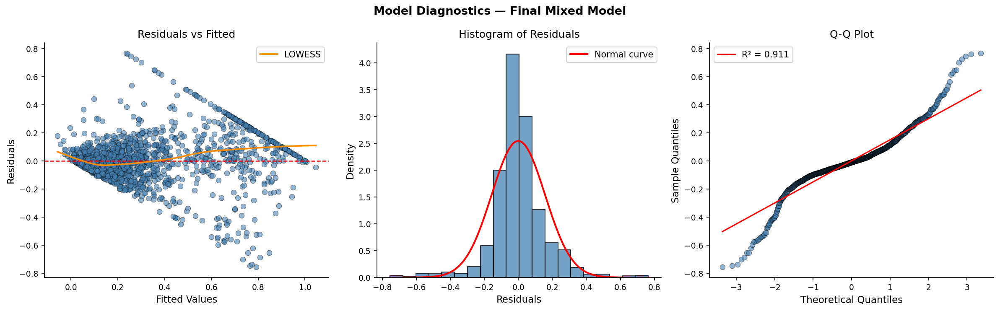

In [94]:
# Diagnostic plots ─────────────────────────────────────────────────────────
residuals   = result_final.resid
fitted_vals = result_final.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Model Diagnostics — Final Mixed Model', fontsize=13, fontweight='bold')

# Residuals vs Fitted ───────────────────────────────────────────────────
axes[0].scatter(fitted_vals, residuals, alpha=0.6, edgecolors='k', linewidths=0.4, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.2)
# Loess-style smoothed trend line
from statsmodels.nonparametric.smoothers_lowess import lowess
smooth = lowess(residuals, fitted_vals, frac=0.5)
axes[0].plot(smooth[:, 0], smooth[:, 1], color='darkorange', linewidth=1.8, label='LOWESS')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')
axes[0].legend()

# Histogram of Residuals ────────────────────────────────────────────────
axes[1].hist(residuals, bins=20, color='steelblue', edgecolor='k', alpha=0.75, density=True)
# Overlay normal curve
x = np.linspace(residuals.min(), residuals.max(), 200)
axes[1].plot(x, stats.norm.pdf(x, residuals.mean(), residuals.std()),
             color='red', linewidth=2, label='Normal curve')
axes[1].set_xlabel('Residuals')
axes[1].set_ylabel('Density')
axes[1].set_title('Histogram of Residuals')
axes[1].legend()

# Q-Q Plot ──────────────────────────────────────────────────────────────
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist='norm')
axes[2].scatter(osm, osr, alpha=0.6, edgecolors='k', linewidths=0.4, color='steelblue')
axes[2].plot(osm, slope * np.array(osm) + intercept, color='red', linewidth=1.5, label=f'R² = {r**2:.3f}')
axes[2].set_xlabel('Theoretical Quantiles')
axes[2].set_ylabel('Sample Quantiles')
axes[2].set_title('Q-Q Plot')
axes[2].legend()

plt.tight_layout()
plt.savefig('model_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

Plotting 5 significant term(s): ['wtemp_JA_within', 'wtemp_JA_between', 'tsr_june_within', 'temp_c_June_within', 'precip_m_April_between']
Saved: SupFig10_partial_residuals_full_model.png


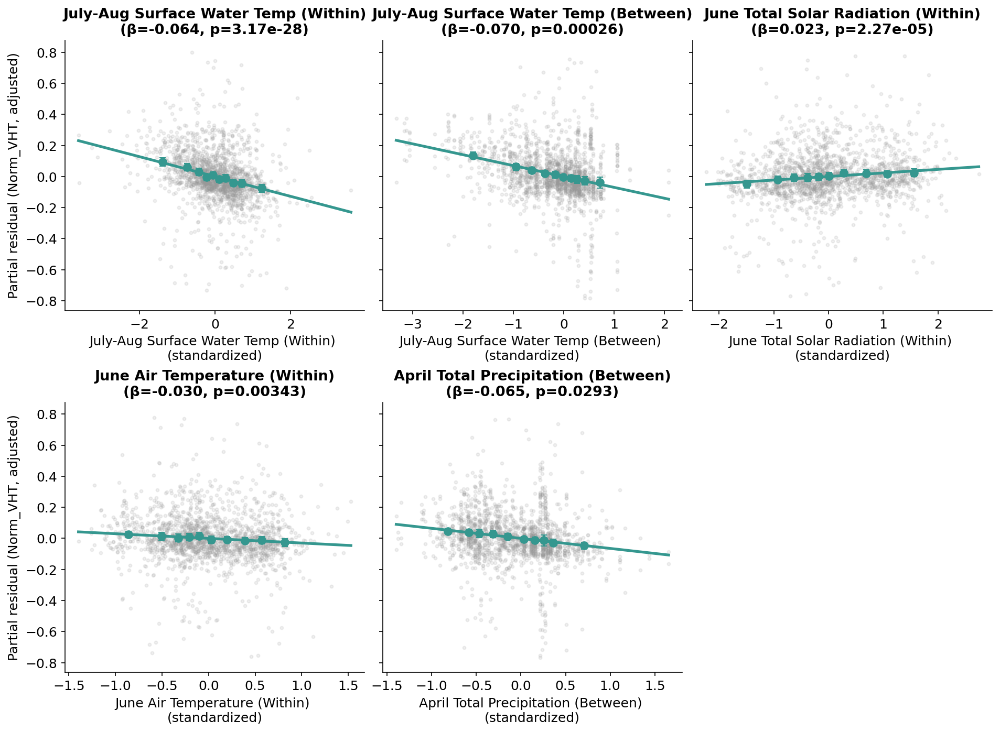

In [98]:
#partial residual plots for supp materials

#settings for plot
FS_LABEL, FS_TICK, FS_TITLE = 12, 12, 15

PRETTY = {
    'precip_m_April_between': 'April Total Precipitation (Between)',
    'temp_c_June_within':     'June Air Temperature (Within)',
    'tsr_june_within':        'June Total Solar Radiation (Within)',
    'wtemp_JA_between':       'July-Aug Surface Water Temp (Between)',
    'wtemp_JA_within':        'July-Aug Surface Water Temp (Within)',
}

ALPHA = 0.05  
SIG_PREDICTORS = fe_final.index[fe_final['p'] < ALPHA].tolist()
print(f"Plotting {len(SIG_PREDICTORS)} significant term(s): {SIG_PREDICTORS}")

N_BINS = 10  # deciles; drop to 6-8 if a predictor has few unique values

var_pal = sns.color_palette('BrBG', n_colors=9)
line_color, band_color, point_color = var_pal[7], var_pal[6], '#999999'

# Compute model residuals and per-predictor partial residuals ────────────
fitted_full = result_final.fittedvalues              # includes BLUPs (lake random intercepts)
resid_full  = df_nz[TARGET_COL].values - fitted_full.values

n_terms = len(SIG_PREDICTORS)
n_rows  = 2 if n_terms > 1 else 1
n_cols  = int(np.ceil(n_terms / n_rows))

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(4.2 * n_cols, 4.6 * n_rows),
                         sharey=True, constrained_layout=True,
                         squeeze=False)
axes_flat = axes.flatten()

for i, col in enumerate(SIG_PREDICTORS):
    ax = axes_flat[i]
    b = fe_final.loc[col, 'coef']
    p = fe_final.loc[col, 'p']
    x = df_nz[col].values
    partial_resid = resid_full + b * x
    ax.scatter(x, partial_resid, color=point_color, s=8, alpha=0.15, zorder=1)

    # binned means +/- 95% CI to show the shape clearly 
    tmp = pd.DataFrame({'x': x, 'y': partial_resid})
    tmp['bin'] = pd.qcut(tmp['x'], q=N_BINS, duplicates='drop')
    binned = (
        tmp.groupby('bin', observed=True)
        .agg(x_mean=('x', 'mean'), y_mean=('y', 'mean'),
             y_se=('y', lambda v: v.std(ddof=1) / np.sqrt(len(v))),
             n=('y', 'size'))
        .reset_index(drop=True)
    )
    ax.errorbar(binned['x_mean'], binned['y_mean'], yerr=1.96 * binned['y_se'],
                fmt='o', color=line_color, ecolor=line_color, elinewidth=1.5,
                capsize=3, markersize=7, zorder=3)

    # model-implied partial-dependence line ------------------------------
    x_line = np.linspace(x.min(), x.max(), 100)
    intercept_adj = partial_resid.mean() - b * x.mean()
    ax.plot(x_line, b * x_line + intercept_adj, color=line_color, lw=2.5, zorder=2)

    ax.set_title(f'{PRETTY.get(col, col)}\n(\u03b2={b:.3f}, p={p:.3g})',
                 fontsize=FS_TITLE - 2, fontweight='bold')
    ax.set_xlabel(f'{PRETTY.get(col, col)} \n(standardized)', fontsize=FS_LABEL)
    if i % n_cols == 0:   # first panel in each row gets the y-label
        ax.set_ylabel(f'Partial residual ({TARGET_COL}, adjusted)', fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right']].set_visible(False)

# Hide any unused panels (e.g., odd number of terms)
for j in range(n_terms, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.savefig('SupFig10_partial_residuals_full_model.png', bbox_inches='tight', dpi=300)
print('Saved: SupFig10_partial_residuals_full_model.png')

In [99]:
# for diagnostics: linearity check via LRT vs. spline ─────────

print('\nLinearity diagnostic (linear vs. natural cubic spline, LRT):')
for term in best_formula_terms:
    other_terms = [t for t in best_formula_terms if t != term]

    formula_linear = f"{TARGET_COL} ~ " + " + ".join(best_formula_terms)
    formula_spline = (f"{TARGET_COL} ~ cr({term}, df=4) + "
                       + " + ".join(other_terms))

    fit_linear = smf.mixedlm(formula_linear, data=df_nz,
                              groups=df_nz[LAKE_COL]).fit(reml=False)
    fit_spline = smf.mixedlm(formula_spline, data=df_nz,
                              groups=df_nz[LAKE_COL]).fit(reml=False)

    if not (fit_linear.converged and fit_spline.converged):
        print(f'  {term:<25s} WARNING: one or both fits did not converge -- skip/inspect')
        continue

    lr_stat = 2 * (fit_spline.llf - fit_linear.llf)
    lr_df = 3  # spline df=4 basis vs. 1 linear parameter for this term
    lr_p = stats.chi2.sf(lr_stat, df=lr_df)
    flag = '** possible nonlinearity **' if lr_p < 0.05 else 'linear adequate'
    print(f'  {term:<25s} LRT χ²({lr_df})={lr_stat:6.2f}  p={lr_p:.4g}  {flag}')


Linearity diagnostic (linear vs. natural cubic spline, LRT):
  wtemp_JA_within           LRT χ²(3)=  6.02  p=0.1108  linear adequate
  wtemp_JA_between          LRT χ²(3)= 26.16  p=8.849e-06  ** possible nonlinearity **
  tsr_june_within           LRT χ²(3)=  3.57  p=0.3118  linear adequate
  temp_c_June_within        LRT χ²(3)=  0.14  p=0.9865  linear adequate
  precip_m_April_between    LRT χ²(3)=  3.05  p=0.3837  linear adequate


In [107]:
def nakagawa_r2(result, df):
    """
    Nakagawa & Schielzeth (2013), Methods Ecol Evol 4:133-142.
    Marginal R^2   = var(Xb) / (var(Xb) + var_random + var_resid)
    Conditional R^2 = (var(Xb) + var_random) / (var(Xb) + var_random + var_resid)
    """
    # fixed-effects-only linear predictor: X * beta_hat
    fixef_pred = np.dot(result.model.exog, result.fe_params)
    var_fixed  = np.var(fixef_pred, ddof=1)

    # sum all random-effect variance components (not just [0,0] —
    # only safe to hard-code [0,0] if the model is random-intercept-only,
    # i.e. no re_formula with random slopes)
    var_random = np.trace(result.cov_re.values) if result.cov_re.shape[0] > 1 else result.cov_re.iloc[0, 0]

    var_resid  = result.scale
    var_total  = var_fixed + var_random + var_resid

    r2_m = var_fixed / var_total
    r2_c = (var_fixed + var_random) / var_total
    return r2_m, r2_c

# Make non-zero subset for LME───────────────────────────────────────────────
df_nz = df_scaled[df_scaled['VHT_present'] == 1].copy().reset_index(drop=True)
print(f'Part 2 dataset: {len(df_nz)} obs | '
      f'{df_nz[LAKE_COL].nunique()} lakes')
print(f'Target mean : {df_nz[TARGET_COL].mean():.3f}')
print(f'Target SD   : {df_nz[TARGET_COL].std():.3f}')

# define predictors ──────────────────────────────────────────────
abund_preds = [c for c in final_preds if c in df_nz.columns]

# collinearity check on non-zero subset ──────────
print('\nCollinearity check on non-zero subset (|r| > 0.70):')
corr_nz = df_nz[abund_preds].corr(method='spearman').abs()
high_corr_nz = []
cols_nz = corr_nz.columns.tolist()
for i in range(len(cols_nz)):
    for j in range(i+1, len(cols_nz)):
        r = corr_nz.iloc[i, j]
        if r > 0.70:
            high_corr_nz.append((cols_nz[i], cols_nz[j], round(r, 3)))
high_corr_nz.sort(key=lambda x: -x[2])
if high_corr_nz:
    print('Highly correlated pairs in non-zero subset:')
    for a, b, r in high_corr_nz:
        print(f'  {a:<30s} — {b:<30s}  r={r:.3f}')
    dropped_nz = set()
    for a, b, r in high_corr_nz:
        if a in dropped_nz or b in dropped_nz:
            continue
        r_a = within_r_lookup.get(a, 0)
        r_b = within_r_lookup.get(b, 0)
        drop = a if r_a < r_b else b
        dropped_nz.add(drop)
        print(f'  Dropping {drop} (|mean_r|={min(r_a,r_b):.3f}) '
              f'in favour of {[a,b][[a,b].index(drop)^1]} (|mean_r|={max(r_a,r_b):.3f})')
    abund_preds = [c for c in abund_preds if c not in dropped_nz]
    print(f'abund_preds after drop: {abund_preds}')
else:
    print('No pairs exceed |r| > 0.70')

# fit full model with remaining predictors ─────────────────────────────────
formula_full = f"{TARGET_COL} ~ " + " + ".join(abund_preds)
model_full   = smf.mixedlm(formula_full, data=df_nz,
                            groups=df_nz[LAKE_COL])
result_full  = model_full.fit(reml=False)  # ML for AIC

# extract fixed effects table ──────────────────────────────────────────────
fe_full = pd.DataFrame({
    'coef':    result_full.fe_params,
    'se':      result_full.bse_fe,
    'p':       result_full.pvalues,
    'ci_low':  result_full.conf_int().iloc[:, 0],
    'ci_high': result_full.conf_int().iloc[:, 1],
}).drop(index=['Intercept', 'Group Var'], errors='ignore')
fe_full['significant'] = fe_full['p'] < 0.05
fe_full = fe_full.sort_values('p')
print(f'\nFull model — all {len(abund_preds)} predictors:')
print(f'AIC: {result_full.aic:.1f}')
print(fe_full[['coef','se','p','significant']].round(4).to_string())


Part 2 dataset: 1793 obs | 330 lakes
Target mean : 0.305
Target SD   : 0.312

Collinearity check on non-zero subset (|r| > 0.70):
Highly correlated pairs in non-zero subset:
  temp_c_JA                      — temp_c_June                     r=0.800
  Dropping temp_c_June (|mean_r|=0.137) in favour of temp_c_JA (|mean_r|=0.363)
abund_preds after drop: ['secchi_JA', 'wtemp_JA', 'PDO_JA', 'PNA_JA', 'NAM_JA', 'temp_c_JA', 'windspeed_ja', 'NAM_May', 'PNA_June', 'ENSO_June', 'tsr_june', 'temp_c_April', 'temp_c_May', 'PC1', 'PC2', 'PC3', 'precip_m_April', 'windspeed_may', 'wtemp_may', 'wtemp_june']

Full model — all 20 predictors:
AIC: -465.8
                  coef      se       p  significant
wtemp_JA       -0.0696  0.0069  0.0000         True
PC1            -0.0170  0.0058  0.0034         True
tsr_june        0.0176  0.0060  0.0035         True
wtemp_may       0.0090  0.0063  0.1569        False
windspeed_ja    0.0117  0.0083  0.1600        False
temp_c_May     -0.0133  0.0099  0.1785      

In [108]:
# Remove lakes with only 1 non-zero observation from df_nz
nz_counts = df_nz.groupby(LAKE_COL).size()
lakes_1obs = nz_counts[nz_counts < 2].index
print(f'Lakes with <2 non-zero obs: {len(lakes_1obs)}')

df_nz = df_nz[~df_nz[LAKE_COL].isin(lakes_1obs)].reset_index(drop=True)
print(f'df_nz after removing: {len(df_nz)} obs, {df_nz[LAKE_COL].nunique()} lakes')

Lakes with <2 non-zero obs: 22
df_nz after removing: 1771 obs, 308 lakes


In [110]:
# Parsimonious final model — significant predictors only ──────────────────

P_THRESHOLD = 0.1

sig_concurrent_final = fe_full[fe_full['p'] < P_THRESHOLD].index.tolist()
sig_concurrent_final = [p for p in sig_concurrent_final if p in df_nz.columns]
print(f'Significant predictors (p<{P_THRESHOLD}): {len(sig_concurrent_final)}')
print(sig_concurrent_final)

formula_final = f"{TARGET_COL} ~ " + " + ".join(sig_concurrent_final)

# Fit with REML for final inference
model_final  = smf.mixedlm(formula_final, data=df_nz,
                            groups=df_nz[LAKE_COL])
result_final = model_final.fit(reml=True)

# Also fit with ML for AIC comparison
result_final_ml = smf.mixedlm(formula_final, data=df_nz,
                               groups=df_nz[LAKE_COL]).fit(reml=False)

# Nakagawa R²
r2_m, r2_c = nakagawa_r2(result_final, df_nz)

# Likelihood ratio test vs null
null_ml = smf.mixedlm(f"{TARGET_COL} ~ 1", data=df_nz,
                       groups=df_nz[LAKE_COL]).fit(reml=False)
lr_stat = 2 * (result_final_ml.llf - null_ml.llf)
lr_p    = stats.chi2.sf(lr_stat, df=len(sig_concurrent_final))

print(f'\nFinal model summary:')
print(result_final.summary())
print(f'\nNakagawa R²:')
print(f'  Marginal   (fixed effects) : {r2_m:.3f}  ({r2_m*100:.1f}%)')
print(f'  Conditional (predictors + lake)       : {r2_c:.3f}  ({r2_c*100:.1f}%)')
print(f'\nLikelihood ratio test vs null:')
print(f'  χ²({len(sig_concurrent_final)}) = {lr_stat:.2f},  p = {lr_p:.4f}')
print(f'  Null AIC  : {null_ml.aic:.1f}')
print(f'  Final AIC : {result_final_ml.aic:.1f}')
print(f'  ΔAIC      : {null_ml.aic - result_final_ml.aic:.1f}')

Significant predictors (p<0.1): 3
['wtemp_JA', 'PC1', 'tsr_june']

Final model summary:
        Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: Norm_VHT
No. Observations: 1771    Method:             REML    
No. Groups:       308     Scale:              0.0292  
Min. group size:  2       Log-Likelihood:     236.2882
Max. group size:  24      Converged:          Yes     
Mean group size:  5.8                                 
------------------------------------------------------
           Coef.  Std.Err.    z    P>|z| [0.025 0.975]
------------------------------------------------------
Intercept   0.289    0.015  19.452 0.000  0.260  0.318
wtemp_JA   -0.067    0.005 -12.219 0.000 -0.078 -0.056
PC1        -0.010    0.005  -2.308 0.021 -0.019 -0.002
tsr_june    0.015    0.005   3.184 0.001  0.006  0.023
Group Var   0.059    0.034                            


Nakagawa R²:
  Marginal   (fixed effects) : 0.054  (5.4%)
  Conditional (predictors + lake)   

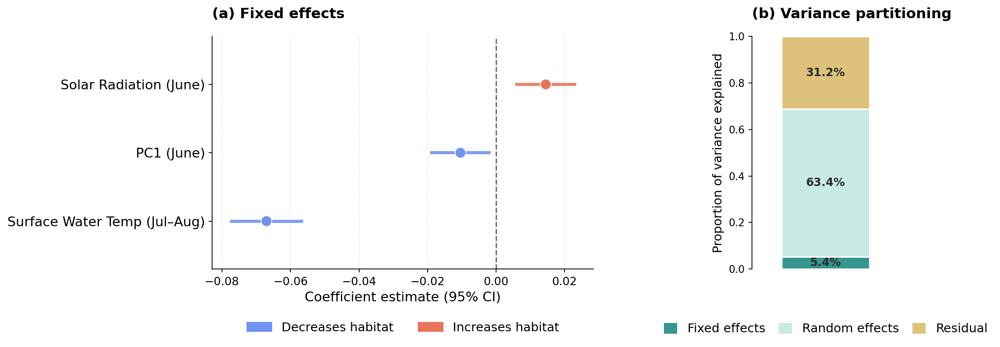

In [111]:

# --- Palettes ---
forest_pal = sns.color_palette("coolwarm", n_colors=5)
color_up, color_down = forest_pal[4], forest_pal[0]

var_full = sns.color_palette("BrBG", n_colors=9)
color_fixed, color_random, color_residual = var_full[7], var_full[5], var_full[2]
# fixed: 7->6 (lighter), random: 5->4 (darker), residual: 1->2 (lighter)

drop_rows = ["Intercept", "Group Var"]
coef_table = pd.DataFrame({
    "coef": result_final.params.drop(drop_rows, errors="ignore"),
    "ci_low": result_final.conf_int().drop(drop_rows, errors="ignore")[0],
    "ci_high": result_final.conf_int().drop(drop_rows, errors="ignore")[1],
    "p": result_final.pvalues.drop(drop_rows, errors="ignore"),
}).sort_values('coef')

preds = coef_table.index.tolist()
n = len(preds)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, n * 0.7 + 2),
    gridspec_kw={'width_ratios': [2.6, 1], 'wspace': 0.6}
)

# --- Left: forest plot ---
y = range(n)
colors = [color_up if c > 0 else color_down for c in coef_table['coef']]
ax1.scatter(coef_table['coef'], y, color=colors, zorder=3, s=110, edgecolor='white', linewidth=0.8)
ax1.hlines(y, coef_table['ci_low'], coef_table['ci_high'], color=colors, linewidth=3, alpha=0.9)
ax1.axvline(0, color='black', lw=1.3, linestyle='--', alpha=0.6, zorder=1)
ax1.set_yticks(y)
ax1.set_yticklabels([pretty(p) for p in preds], fontsize=13)
ax1.set_ylim(-0.7, n - 0.3)
ax1.set_xlabel('Coefficient estimate (95% CI)', fontsize=13)
ax1.tick_params(axis='x', labelsize=11)
ax1.grid(axis='x', linestyle=':', color='grey', alpha=0.3, zorder=0)
ax1.spines[['top', 'right']].set_visible(False)

ax1.set_title(
    '(a) Fixed effects',
    fontsize=14,
    fontweight='bold',
    loc='left',
    pad=18
)

ax1.legend(handles=[
    Patch(color=color_down, label='Decreases habitat'),
    Patch(color=color_up, label='Increases habitat')
], fontsize=12, loc='upper center', bbox_to_anchor=(0.5, -0.18),
   ncol=2, frameon=False)

# --- Right: variance-partitioning stacked bar ---
fixed_share = r2_m
random_share = r2_c - r2_m
residual_share = 1 - r2_c

bar_width = 0.6
bottom = 0
for share, color, label in [
    (fixed_share, color_fixed, 'Fixed effects'),
    (random_share, color_random, 'Random effects'),
    (residual_share, color_residual, 'Residual'),
]:
    ax2.bar(0, share, bottom=bottom, color=color, width=bar_width,
            edgecolor='white', linewidth=1.5, label=label)
    if share > 0.04:
        text_color = '#2b2b2b'
        ax2.text(0, bottom + share / 2, f'{share*100:.1f}%', ha='center', va='center',
                  fontsize=11, fontweight='bold', color=text_color)
    bottom += share

ax2.set_xlim(-0.5, 0.5)
ax2.set_ylim(0, 1)
ax2.set_xticks([])
ax2.set_ylabel('Proportion of variance explained', fontsize=12)

# Left-aligned, bold panel title
ax2.set_title(
    '(b) Variance partitioning',
    fontsize=14,
    fontweight='bold',
    loc='left',
    pad=18
)

ax2.tick_params(axis='y', labelsize=10)
ax2.spines[['top', 'right', 'bottom']].set_visible(False)
ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3,
           fontsize=12, frameon=False, columnspacing=1.0, handlelength=1.2, handleheight=1.2)

plt.tight_layout()
plt.savefig('mixedlm_forest_variance_combined.png', bbox_inches='tight', dpi=300)
plt.show()

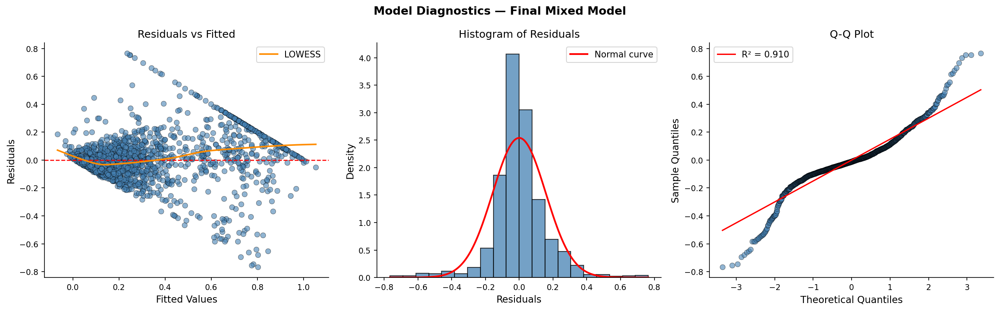

In [40]:
# Diagnostic plots ─────────────────────────────────────────────────────────
residuals   = result_final.resid
fitted_vals = result_final.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Model Diagnostics — Final Mixed Model', fontsize=13, fontweight='bold')

# Residuals vs Fitted ───────────────────────────────────────────────────
axes[0].scatter(fitted_vals, residuals, alpha=0.6, edgecolors='k', linewidths=0.4, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.2)
# Loess-style smoothed trend line
from statsmodels.nonparametric.smoothers_lowess import lowess
smooth = lowess(residuals, fitted_vals, frac=0.5)
axes[0].plot(smooth[:, 0], smooth[:, 1], color='darkorange', linewidth=1.8, label='LOWESS')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')
axes[0].legend()

# Histogram of Residuals ────────────────────────────────────────────────
axes[1].hist(residuals, bins=20, color='steelblue', edgecolor='k', alpha=0.75, density=True)
# Overlay normal curve
x = np.linspace(residuals.min(), residuals.max(), 200)
axes[1].plot(x, stats.norm.pdf(x, residuals.mean(), residuals.std()),
             color='red', linewidth=2, label='Normal curve')
axes[1].set_xlabel('Residuals')
axes[1].set_ylabel('Density')
axes[1].set_title('Histogram of Residuals')
axes[1].legend()

# Q-Q Plot ──────────────────────────────────────────────────────────────
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist='norm')
axes[2].scatter(osm, osr, alpha=0.6, edgecolors='k', linewidths=0.4, color='steelblue')
axes[2].plot(osm, slope * np.array(osm) + intercept, color='red', linewidth=1.5, label=f'R² = {r**2:.3f}')
axes[2].set_xlabel('Theoretical Quantiles')
axes[2].set_ylabel('Sample Quantiles')
axes[2].set_title('Q-Q Plot')
axes[2].legend()

plt.tight_layout()
plt.savefig('model_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

In [41]:
residuals = result_final.resid
outlier_mask = np.abs(residuals) > 3 * residuals.std()

print(f"Outliers: {outlier_mask.sum()} obs ({outlier_mask.mean()*100:.1f}%)")

# If < 5% outliers, your model is defensible as-is
# If > 5%, consider removing and refitting
df_nz_clean = df_nz[~outlier_mask].copy().reset_index(drop=True)
print(f"Clean dataset: {len(df_nz_clean)} obs")

#only 2.3% outliers so all is good

Outliers: 40 obs (2.3%)
Clean dataset: 1731 obs


In [42]:
# Refit final model on clean dataset
model_final_clean  = smf.mixedlm(formula_final, data=df_nz_clean,
                                  groups=df_nz_clean[LAKE_COL])
result_final_clean = model_final_clean.fit(reml=True)

# Compare key results — if stable, outliers aren't influential
print("=== Coefficient Stability Check ===")
comparison = pd.DataFrame({
    'coef_full' : result_final.fe_params,
    'coef_clean': result_final_clean.fe_params,
}).drop(index='Intercept', errors='ignore')
comparison['delta'] = (comparison['coef_clean'] - comparison['coef_full']).abs()
comparison['stable'] = comparison['delta'] < 0.05
print(comparison.round(4))

## THIS MEANS: A sensitivity analysis identified 34 outliers (2.0% of observations)
##removal did not substantially alter model conclusions

## Residual normality showed minor deviation (ok bc large sample size) and visual Q-Q inspection confirms approximate normality (R²=0.937)

=== Coefficient Stability Check ===
          coef_full  coef_clean   delta  stable
wtemp_JA    -0.0670     -0.0706  0.0035    True
PC1         -0.0104     -0.0099  0.0004    True
tsr_june     0.0145      0.0122  0.0023    True



Figure saved.
  Panel (b): fixed=7.7%, random=61.7%, residual=30.7% (marginal R²=7.7%, conditional R²=69.3%)


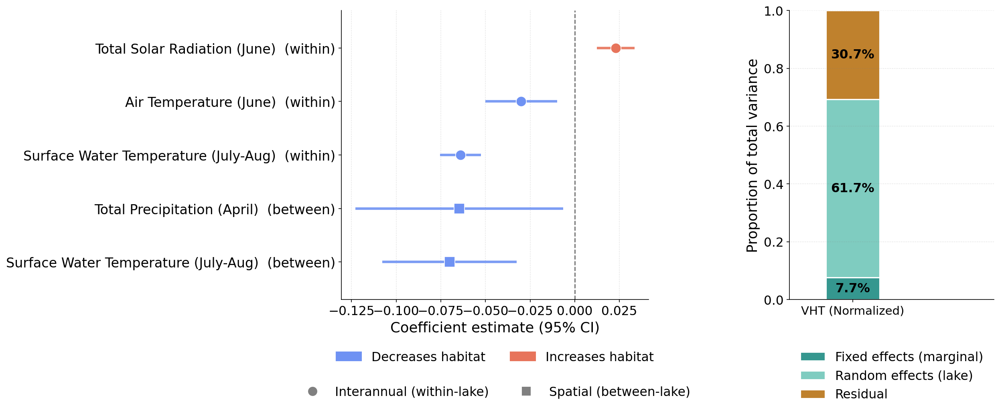

In [29]:
#figure — forest plot + variance decomposition ──────────────────

label_map = {
    'precip_m_April_between': 'Total Precipitation (April)',
    'temp_c_June_within':     'Air Temperature (June)',
    'tsr_june_within':        'Total Solar Radiation (June)',
    'wtemp_JA_between':       'Surface Water Temperature (July-Aug)',
    'wtemp_JA_within':        'Surface Water Temperature (July-Aug)',
}


def pretty(name):
    return label_map.get(name, name.replace('_', ' '))

def term_type(name):
    if name.endswith('_within'):
        return 'Interannual (within-lake)'
    elif name.endswith('_between'):
        return 'Spatial (between-lake)'
    return 'Other'

plot_table = fe_final.copy().sort_values('coef')
plot_table['type'] = [term_type(p) for p in plot_table.index]
preds = plot_table.index.tolist()
n = len(preds)
forest_pal = sns.color_palette('coolwarm', n_colors=5)
color_up, color_down = forest_pal[4], forest_pal[0]
var_pal = sns.color_palette('BrBG', n_colors=9)
color_fixed, color_random, color_resid = var_pal[7], var_pal[6], var_pal[1]

# Global font sizing -------------
FS_LABEL   = 17   # axis labels
FS_TICK    = 15   # tick labels
FS_LEGEND  = 15   # legend text
FS_YLABELS = 16   # forest-plot predictor labels
FS_ANNOT   = 15   # in-bar percentage annotations
FS_XTICK2  = 14   # right-panel x tick label

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(14, n * 0.75 + 2.5),
    gridspec_kw={'width_ratios': [1.8, 1.2], 'wspace': 0.55}
)

# Left: forest plot -------------------------------------------------
y = range(n)
colors = [color_up if c > 0 else color_down for c in plot_table['coef']]
markers = ['o' if t.startswith('Interannual') else 's' for t in plot_table['type']]

ax1.hlines(y, plot_table['ci_low'], plot_table['ci_high'],
           color=colors, linewidth=3, alpha=0.9, zorder=2)
for yi, xi, c, m in zip(y, plot_table['coef'], colors, markers):
    ax1.scatter(xi, yi, color=c, marker=m, zorder=3, s=150,
                edgecolor='white', linewidth=0.8)

ax1.axvline(0, color='black', lw=1.3, linestyle='--', alpha=0.6, zorder=1)
ax1.set_yticks(y)
ax1.set_yticklabels(
    [f"{pretty(p)}  ({'within' if p.endswith('_within') else 'between'})"
     for p in preds],
    fontsize=FS_YLABELS)
ax1.set_ylim(-0.7, n - 0.3)
ax1.set_xlabel('Coefficient estimate (95% CI)', fontsize=FS_LABEL)
ax1.tick_params(axis='x', labelsize=FS_TICK)
ax1.grid(axis='x', linestyle=':', color='grey', alpha=0.3, zorder=0)
ax1.spines[['top', 'right']].set_visible(False)
sign_handles = [
    Patch(color=color_down, label='Decreases habitat'),
    Patch(color=color_up, label='Increases habitat'),
]
shape_handles = [
    Line2D([0], [0], marker='o', color='grey', linestyle='None', markersize=10,
           label='Interannual (within-lake)'),
    Line2D([0], [0], marker='s', color='grey', linestyle='None', markersize=10,
           label='Spatial (between-lake)'),
]
leg1 = ax1.legend(handles=sign_handles, fontsize=FS_LEGEND, loc='upper center',
                   bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
ax1.add_artist(leg1)
ax1.legend(handles=shape_handles, fontsize=FS_LEGEND, loc='upper center',
           bbox_to_anchor=(0.5, -0.26), ncol=2, frameon=False)

#Right: variance decomposition (Nakagawa & Schielzeth 2017) ------------

prop_fixed  = ns_r2['var_fixed']  / ns_r2['var_total']
prop_random = ns_r2['var_random'] / ns_r2['var_total']
prop_resid  = ns_r2['var_resid']  / ns_r2['var_total']

x = [0]
width = 0.55

ax2.bar(x, [prop_fixed], width, color=color_fixed,
        edgecolor='white', linewidth=1.5, label='Fixed effects (marginal)')
ax2.bar(x, [prop_random], width, bottom=[prop_fixed], color=color_random,
        edgecolor='white', linewidth=1.5, label='Random effects (lake)')
ax2.bar(x, [prop_resid], width, bottom=[prop_fixed + prop_random],
        color=color_resid, edgecolor='white', linewidth=1.5, label='Residual')

ax2.text(0, prop_fixed / 2, f'{prop_fixed*100:.1f}%', ha='center', va='center',
          fontsize=FS_ANNOT, fontweight='bold', color='black')
ax2.text(0, prop_fixed + prop_random / 2, f'{prop_random*100:.1f}%',
          ha='center', va='center', fontsize=FS_ANNOT, fontweight='bold', color='black')
ax2.text(0, prop_fixed + prop_random + prop_resid / 2, f'{prop_resid*100:.1f}%',
          ha='center', va='center', fontsize=FS_ANNOT, fontweight='bold', color='black')

ax2.set_xticks(x)
ax2.set_xticklabels(['VHT (Normalized)'], fontsize=FS_XTICK2)
ax2.set_xlim(-0.65, 1.45)
ax2.set_ylim(0, 1.0)
ax2.set_ylabel('Proportion of total variance', fontsize=FS_LABEL)
ax2.tick_params(axis='y', labelsize=FS_TICK)
ax2.grid(axis='y', linestyle=':', color='grey', alpha=0.3, zorder=0)
ax2.spines[['top', 'right']].set_visible(False)
ax2.legend(fontsize=FS_LEGEND, loc='upper center', bbox_to_anchor=(0.5, -0.14),
           ncol=1, frameon=False)

plt.tight_layout()
plt.savefig('mixedlm_forest_variance_combined.png',
            bbox_inches='tight', dpi=300)
print('\nFigure saved.')
print(f"  Panel (b): fixed={prop_fixed*100:.1f}%, random={prop_random*100:.1f}%, "
      f"residual={prop_resid*100:.1f}% (marginal R\u00b2={prop_fixed*100:.1f}%, "
      f"conditional R\u00b2={(prop_fixed+prop_random)*100:.1f}%)")


Lake characteristic                            r         p  interpretation
--------------------------------------------------------------------------------
lake_maxdepth_m                           -0.377    0.0000  * larger → lower Norm_VHT
lake_area_ha                               0.072    0.2049   larger → higher Norm_VHT
TSI                                        0.006    0.9122   larger → higher Norm_VHT
geo_position                              -0.095    0.0970   larger → lower Norm_VHT


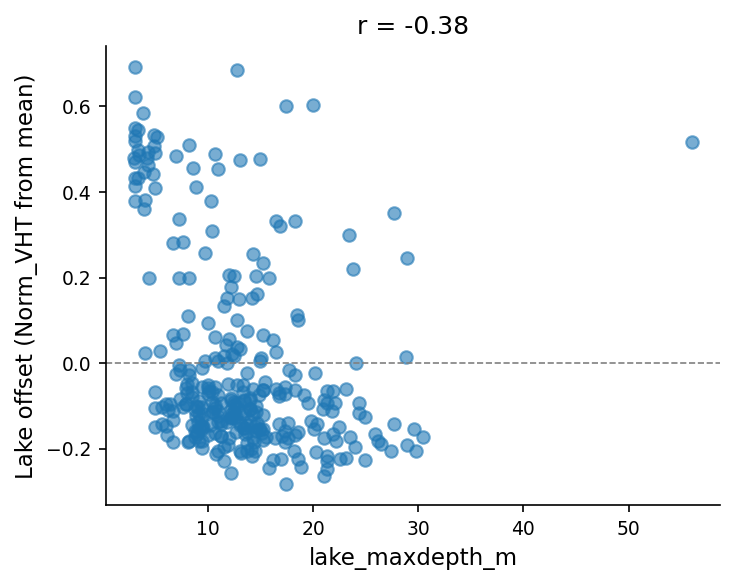

In [105]:
# try correlating lake BLUPs with lake characteristics ─────────────

# Lake-level BLUPs from the final (REML) model
#    random_effects maps lake -> Series with key 'Group' (random intercept).
blup_col = 'blup'
re_df = pd.DataFrame({
    LAKE_COL: list(result_final.random_effects.keys()),
    blup_col: [v.iloc[0] for v in result_final.random_effects.values()],
})

# Attach lake-level characteristics 
lake_char_cols = ['lake_maxdepth_m', 'lake_area_ha', 'TSI', 'geo_position']
lake_char_cols = [c for c in lake_char_cols if c in df_scaled.columns]

lake_chars = (df_scaled.groupby(LAKE_COL)[lake_char_cols].first().reset_index())
re_df = re_df.merge(lake_chars, on=LAKE_COL, how='left')

num_cols = lake_char_cols

lake_char_cols = ['lake_maxdepth_m', 'lake_area_ha', 'TSI', 'geo_position']
lake_char_cols = [c for c in lake_char_cols if c in df_scaled.columns]


# Spearman correlations
print(f'\n{"Lake characteristic":<40s}  {"r":>6s}  {"p":>8s}  interpretation')
print('-' * 80)

results_a1 = []
for col in num_cols:
    valid = re_df[[col, blup_col]].dropna()
    if len(valid) < 10:
        continue
    r, p = scipy_stats.spearmanr(valid[col], valid[blup_col])
    sig = '*' if p < 0.05 else ''
    direction = 'larger → higher Norm_VHT' if r > 0 else 'larger → lower Norm_VHT'
    results_a1.append({'var': col, 'r': r, 'p': p})
    print(f'{col:<40s}  {r:>6.3f}  {p:>8.4f}  {sig} {direction}')

# Scatter plots for significant ones
sig_num = [d['var'] for d in results_a1 if d['p'] < 0.05]

if sig_num:
    fig, axes = plt.subplots(1, len(sig_num), figsize=(5 * len(sig_num), 4),
                             squeeze=False)
    for ax, col in zip(axes.flatten(), sig_num):
        ax.scatter(re_df[col], re_df[blup_col], alpha=0.6)
        ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)

        if col == 'lake_area_ha':
            ax.set_xscale('log')
            ax.set_xlabel('lake_area_ha (log scale)')
        else:
            ax.set_xlabel(col)

        ax.set_ylabel('Lake offset (Norm_VHT from mean)')
        r_val = next(d['r'] for d in results_a1 if d['var'] == col)
        ax.set_title(f'r = {r_val:.2f}')

    plt.tight_layout()
    plt.show()

           var  levels  n_lakes       H      p  epsilon2   p_BH
depth_category       3      308 29.5543 0.0000    0.0903 0.0000
 trophic_state       3      308  8.1217 0.0172    0.0201 0.0332
hydro_category       2      308  5.0325 0.0249    0.0132 0.0332
  geo_position       2      308  2.7560 0.0969    0.0057 0.0969


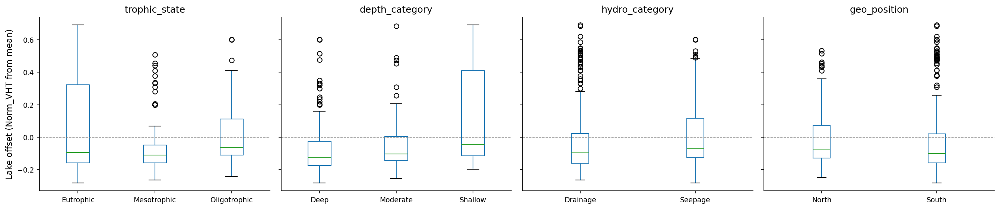

In [106]:
cat_candidates = ['trophic_state', 'depth_category', 'hydro_category', 'geo_position']
cat_candidates = [c for c in cat_candidates if c in df_scaled.columns]

cat_chars = df_scaled.groupby(LAKE_COL)[cat_candidates].first().reset_index()
cat_chars = cat_chars.astype({c: str for c in cat_candidates})   # force categorical
re_cat = re_df[[LAKE_COL, blup_col]].merge(cat_chars, on=LAKE_COL, how='left')

MIN_LAKES = 5
rows = []
for col in cat_candidates:
    sub = re_cat[[col, blup_col]].dropna()
    sub = sub[sub[col] != 'nan']
    counts = sub[col].value_counts()
    sub = sub[sub[col].isin(counts[counts >= MIN_LAKES].index)]
    groups = [g[blup_col].values for _, g in sub.groupby(col)]
    if len(groups) < 2:
        print(f'{col}: <2 levels with >= {MIN_LAKES} lakes, skipped')
        continue
    h, p = scipy_stats.kruskal(*groups)
    n, k = len(sub), len(groups)
    rows.append({'var': col, 'levels': k, 'n_lakes': n, 'H': h, 'p': p,
                 'epsilon2': (h - k + 1) / (n - k)})

res_cat = pd.DataFrame(rows)
res_cat['p_BH'] = multipletests(res_cat['p'], method='fdr_bh')[1]
print(res_cat.sort_values('p').round(4).to_string(index=False))

# Boxplots for all four (only a few, so no need to filter)
fig, axes = plt.subplots(1, len(cat_candidates), figsize=(4.5 * len(cat_candidates), 4),
                         sharey=True, squeeze=False)
for ax, col in zip(axes.flatten(), cat_candidates):
    sub = re_cat[re_cat[col] != 'nan']
    sub.boxplot(column=blup_col, by=col, ax=ax, grid=False)
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_title(col); ax.set_xlabel('')
axes[0, 0].set_ylabel('Lake offset (Norm_VHT from mean)')
plt.suptitle('')
plt.tight_layout()
plt.show()

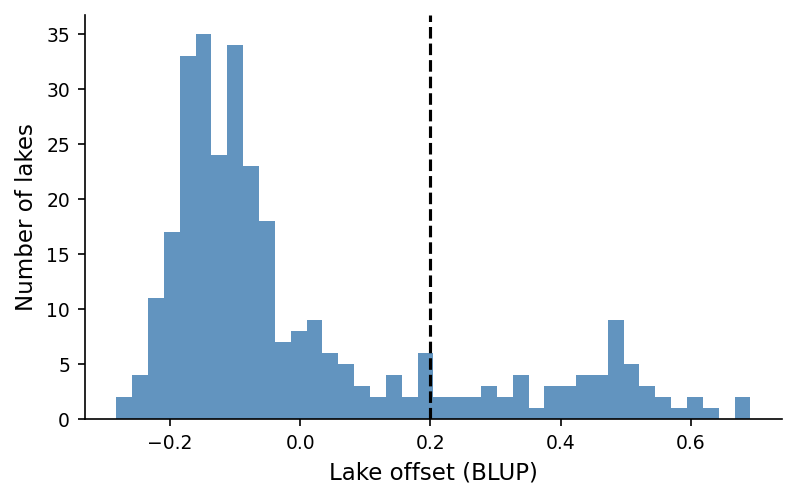

high
False    251
True      57
Name: count, dtype: int64


In [107]:
HI_THRESH = 0.2

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(re_df[blup_col], bins=40, color='steelblue', alpha=0.85)
ax.axvline(HI_THRESH, color='k', ls='--')
ax.set_xlabel('Lake offset (BLUP)'); ax.set_ylabel('Number of lakes')
plt.show()

re_df['high'] = re_df[blup_col] > HI_THRESH
print(re_df['high'].value_counts())

In [117]:
import statsmodels.formula.api as smf
d = full.copy()
d['high_i'] = d['high'].astype(int)
d['log_depth'] = np.log(d['lake_maxdepth_m'])
d['log_area']  = np.log(d['lake_area_ha'])
print(d[['log_depth', 'log_area', 'TSI', 'secchi_JA_between']].corr(method='spearman').round(2))

m1 = smf.logit('high_i ~ log_depth + log_area + secchi_JA_between', data=d).fit()
m2 = smf.logit('high_i ~ log_depth + log_area + TSI + I(TSI**2)', data=d).fit()  # allows the U-shape
print(m1.summary().tables[1]); print(m2.summary().tables[1])

f0 = f"{TARGET_COL} ~ " + " + ".join(best_formula_terms)
f1 = f0 + " + np.log(lake_maxdepth_m) + np.log(lake_area_ha)"
for f in (f0, f1):
    m = smf.mixedlm(f, df_nz, groups=df_nz[LAKE_COL]).fit(reml=True)
    print(f'Group Var = {m.cov_re.iloc[0, 0]:.4f}')

                   log_depth  log_area     TSI  secchi_JA_between
log_depth             1.0000    0.2500 -0.4700             0.4500
log_area              0.2500    1.0000  0.0400            -0.0700
TSI                  -0.4700    0.0400  1.0000            -0.9300
secchi_JA_between     0.4500   -0.0700 -0.9300             1.0000
Optimization terminated successfully.
         Current function value: 0.370796
         Iterations 7
Optimization terminated successfully.
         Current function value: 0.359112
         Iterations 7
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             2.5305      0.922      2.745      0.006       0.724       4.337
log_depth            -2.6028      0.402     -6.478      0.000      -3.390      -1.815
log_area              0.4306      0.122      3.529      0.000       0.191       0.670
secchi_JA_between     0.4753      0.

Annual regional dataset: n=16 years, 1994–2018
                            OLS Regression Results                            
Dep. Variable:     Regional_VHT_index   R-squared:                       0.197
Model:                            OLS   Adj. R-squared:                 -0.095
Method:                 Least Squares   F-statistic:                    0.6740
Date:                Mon, 14 Sep 2026   Prob (F-statistic):              0.624
Time:                        12:30:24   Log-Likelihood:                -28.281
No. Observations:                  16   AIC:                             66.56
Df Residuals:                      11   BIC:                             70.42
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const

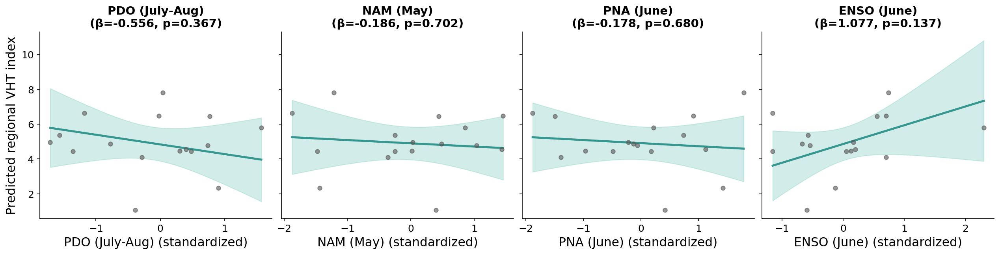

In [32]:
# testing out regional lake index × climate indices ───────────────

FS_LABEL, FS_TICK, FS_TITLE, FS_LEGEND, FS_ANNOT = 15, 12, 16, 12, 12

CLIMATE_COLS = ['PDO_JA', 'NAM_May', 'PNA_June', 'ENSO_June']
CLIMATE_LABELS = {
    'PDO_JA':    'PDO (July-Aug)',
    'NAM_May':   'NAM (May)',
    'PNA_June':  'PNA (June)',
    'ENSO_June': 'ENSO (June)',
}
PAIRS = [
    ('PDO_JA', 'NAM_May'), ('PDO_JA', 'PNA_June'), ('PDO_JA', 'ENSO_June'),
    ('NAM_May', 'PNA_June'), ('NAM_May', 'ENSO_June'), ('PNA_June', 'ENSO_June'),
]
TARGET_COL = 'Regional_VHT_index'

# Load reliable-period regional lake index ───────────────────────────────
regional_lake_index = pd.read_csv("regional_lake_index.csv")

# Extract years and lake index
common_years_rel = regional_lake_index["common_years_rel"].values
lake_index_rel = regional_lake_index["lake_index_rel"].values

# Shared setup: one row per reliable year, index + climate indices ───────
climate_annual = df_scaled.groupby('year')[CLIMATE_COLS].first()

annual = (
    pd.DataFrame({
        'year': common_years_rel,
        TARGET_COL: lake_index_rel
    })
    .set_index('year')
    .join(climate_annual, how='left')
    .dropna()
)

print(
    f"Annual regional dataset: n={len(annual)} years, "
    f"{annual.index.min()}–{annual.index.max()}"
)

var_pal = sns.color_palette('BrBG', n_colors=9)
cmap = 'BrBG'


# FIGURE 8b — partial dependence of regional VHT index on each climate index

X = sm.add_constant(annual[CLIMATE_COLS])
y = annual[TARGET_COL]
ols_fit = sm.OLS(y, X).fit()
print(ols_fit.summary())

fig8b, axes = plt.subplots(1, len(CLIMATE_COLS), figsize=(4.2 * len(CLIMATE_COLS), 4.2),
                            sharey=True, constrained_layout=True)

line_color = var_pal[7]
band_color = var_pal[6]

for i, col in enumerate(CLIMATE_COLS):
    ax = axes[i]
    x_range = np.linspace(annual[col].min(), annual[col].max(), 100)

    # hold all other predictors at their sample mean
    X_pred = pd.DataFrame({c: [annual[c].mean()] * 100 for c in CLIMATE_COLS})
    X_pred[col] = x_range
    X_pred = sm.add_constant(X_pred, has_constant='add')[X.columns]

    pred = ols_fit.get_prediction(X_pred)
    pred_df = pred.summary_frame(alpha=0.05)

    ax.plot(x_range, pred_df['mean'], color=line_color, lw=2.5, zorder=3)
    ax.fill_between(x_range, pred_df['mean_ci_lower'], pred_df['mean_ci_upper'],
                     color=band_color, alpha=0.35, zorder=2)
    ax.scatter(annual[col], annual[TARGET_COL], color='#555555', s=25,
               alpha=0.6, zorder=4)

    p = ols_fit.pvalues[col]
    b = ols_fit.params[col]
    ax.set_title(f'{CLIMATE_LABELS[col]}\n(β={b:.3f}, p={p:.3f})',
                 fontsize=FS_TITLE - 2, fontweight='bold')
    ax.set_xlabel(f'{CLIMATE_LABELS[col]} (standardized)', fontsize=FS_LABEL)
    if i == 0:
        ax.set_ylabel('Predicted regional VHT index', fontsize=FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right']].set_visible(False)

fig8b.savefig('Climate-partial_dependence.png', bbox_inches='tight', dpi=300)
print('Saved: Climate-partial_dependence.png')


# Not included in publication- more plots

In [43]:
# Built dynamically from significant predictors in Part 1 and Part 2

# Part 2 significant concurrent predictors (from final abundance model)
part2_sig = sig_concurrent_final

# Part 1 significant predictors (from GEE presence/absence model)
part1_sig = result_pa.pvalues[result_pa.pvalues < 0.05].index.tolist()
part1_sig = [p for p in part1_sig if p != 'Intercept' and p in df_scaled.columns]

# Combine, preserving order, no duplicates
PLOT_PREDS = list(dict.fromkeys(part2_sig + part1_sig))
PLOT_PREDS = [p for p in PLOT_PREDS if p in df_scaled.columns]

print(f'Predictors to plot: {len(PLOT_PREDS)}')
print(f'  Part 2 (abundance) : {part2_sig}')
print(f'  Part 1 (presence)  : {[p for p in part1_sig if p not in part2_sig]}')

Predictors to plot: 10
  Part 2 (abundance) : ['wtemp_JA', 'PC1', 'tsr_june']
  Part 1 (presence)  : ['secchi_JA', 'PDO_JA', 'NAM_May', 'PNA_June', 'ENSO_June', 'temp_c_June', 'windspeed_may']


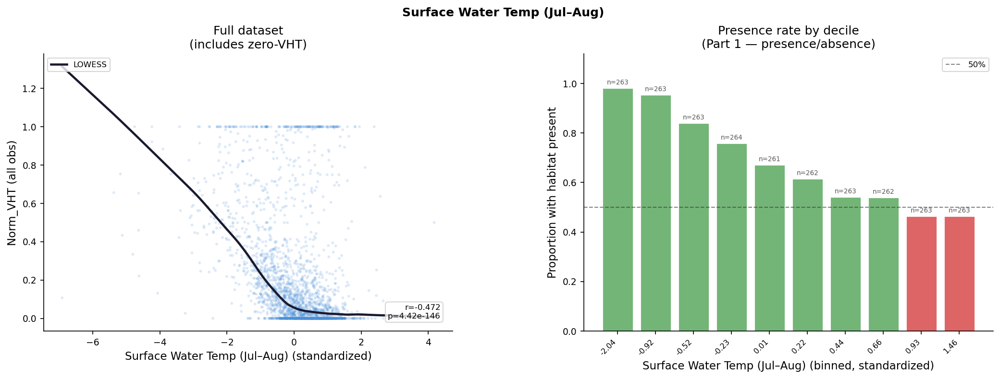

Saved: diagnostic_wtemp_JA.png


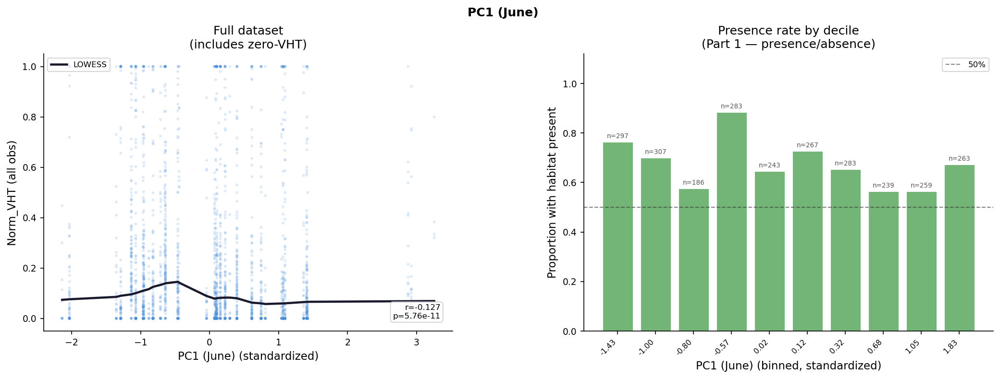

Saved: diagnostic_PC1.png


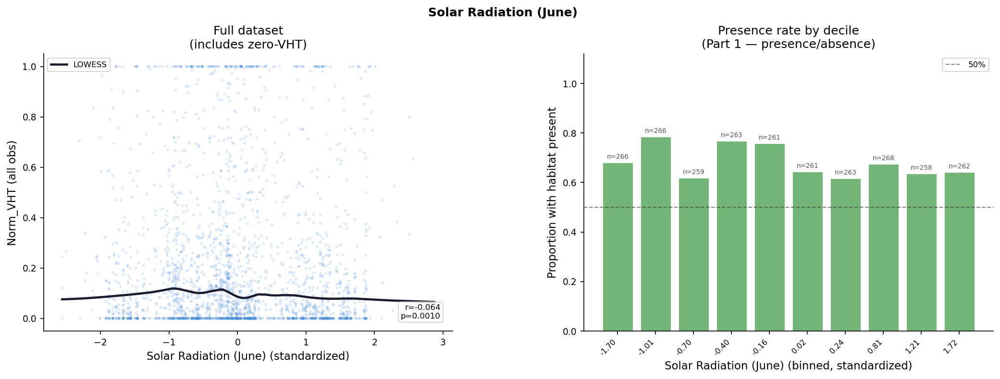

Saved: diagnostic_tsr_june.png


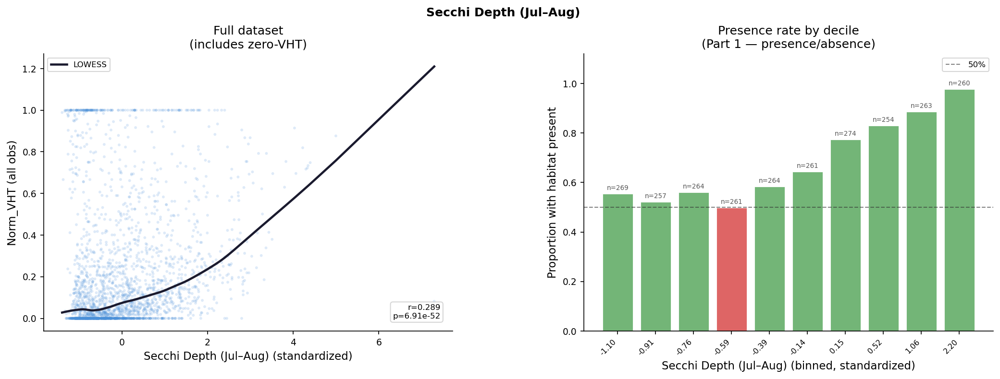

Saved: diagnostic_secchi_JA.png


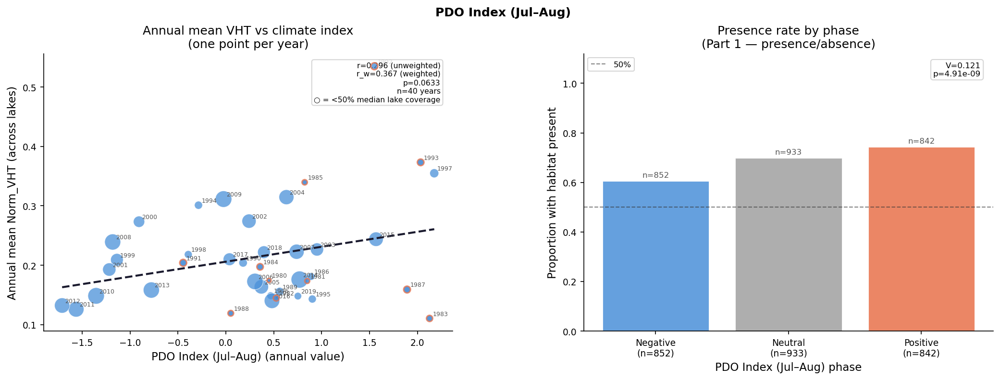

Saved: diagnostic_PDO_JA.png


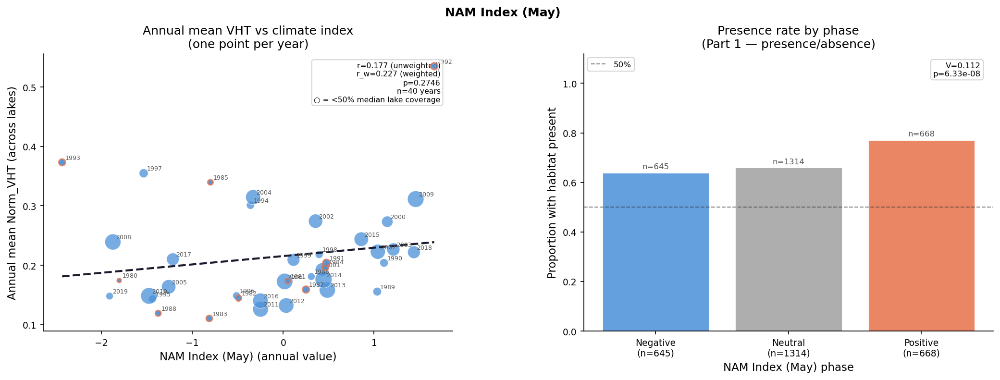

Saved: diagnostic_NAM_May.png


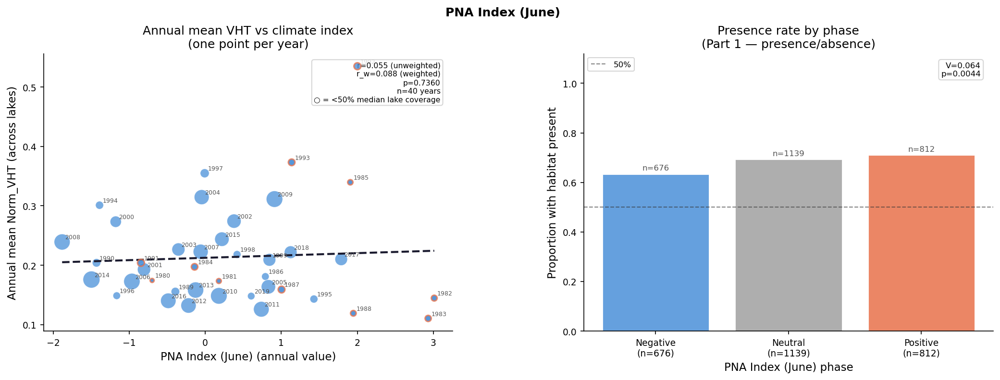

Saved: diagnostic_PNA_June.png


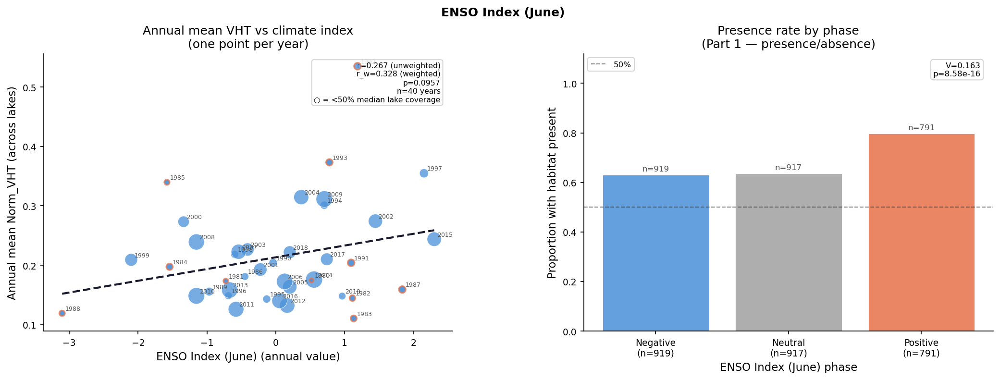

Saved: diagnostic_ENSO_June.png


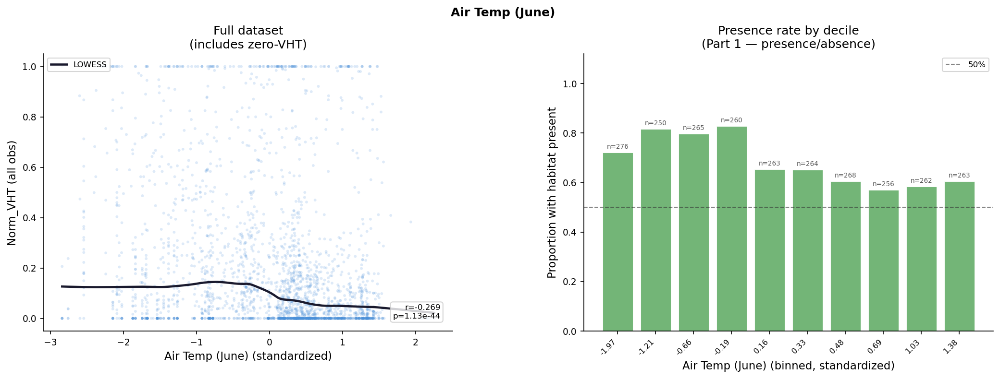

Saved: diagnostic_temp_c_June.png


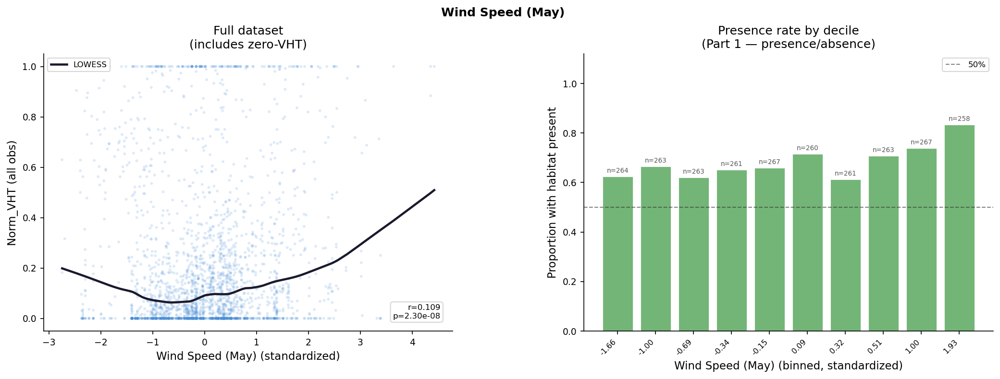

Saved: diagnostic_windspeed_may.png

All 10 diagnostic plots saved.


In [44]:
for pred in PLOT_PREDS:
    is_index = pred in CLIMATE_INDICES
    fig = plt.figure(figsize=(17, 5))
    gs  = gridspec.GridSpec(1, 2, wspace=0.32, width_ratios=[1, 1])
    axes = [fig.add_subplot(gs[i]) for i in range(2)]

    # ── Panel 1 ───────────────────────────────────────────────────────────────
    ax = axes[0]
    xy_full = df_scaled[[pred, TARGET_COL]].dropna()

    # Log-transform for visualization only
    LOGTRANSFORM_PREDS = {'chla_JA', 'chla_june', 'chla_may'}
    if pred in LOGTRANSFORM_PREDS:
        xy_plot = xy_full.copy()
        xy_plot[pred] = np.log1p(xy_plot[pred] - xy_plot[pred].min() + 1)
        x_label_scatter = f'log({pretty(pred)}) (standardized)'
    else:
        xy_plot = xy_full
        x_label_scatter = f'{pretty(pred)} (standardized)'

    if is_index:
        # Annual mean VHT vs index value — one point per year
        annual = df_scaled[[pred, TARGET_COL, 'year']].dropna().groupby('year').agg(
            index_val = (pred,       'first'),
            mean_vht  = (TARGET_COL, 'mean'),
            n_lakes   = (TARGET_COL, 'count')
        ).reset_index()

        sc = ax.scatter(annual['index_val'], annual['mean_vht'],
                        s=annual['n_lakes'] * 2,
                        alpha=0.75, color=COL1_COLOR,
                        edgecolors='white', linewidth=0.5)

        for _, row in annual.iterrows():
            ax.annotate(str(int(row['year'])),
                        (row['index_val'], row['mean_vht']),
                        fontsize=6, color='#555555',
                        xytext=(3, 3), textcoords='offset points')

        weights = annual['n_lakes'].values
        slope, intercept, r, p, _ = linregress(annual['index_val'], annual['mean_vht'])
        x_line = np.linspace(annual['index_val'].min(), annual['index_val'].max(), 100)
        ax.plot(x_line, slope * x_line + intercept,
                color=LOWESS_COLOR, lw=2, linestyle='--')

        # Weighted Pearson r
        w    = weights / weights.sum()
        x_w  = (annual['index_val'] * w).sum()
        y_w  = (annual['mean_vht']  * w).sum()
        r_weighted = (w * (annual['index_val'] - x_w) *
                      (annual['mean_vht'] - y_w)).sum() / np.sqrt(
            (w * (annual['index_val'] - x_w)**2).sum() *
            (w * (annual['mean_vht']  - y_w)**2).sum()
        )

        # Flag low-coverage years with orange ring
        median_n     = annual['n_lakes'].median()
        low_coverage = annual['n_lakes'] < median_n * 0.5
        ax.scatter(annual.loc[low_coverage, 'index_val'],
                   annual.loc[low_coverage, 'mean_vht'],
                   s=annual.loc[low_coverage, 'n_lakes'] * 2,
                   alpha=0.75, color=COL1_COLOR,
                   edgecolors='#E8714A', linewidth=1.5, zorder=5)

        ax.text(0.97, 0.97,
                f'r={r:.3f} (unweighted)\nr_w={r_weighted:.3f} (weighted)\n'
                f'p={fmt_p(p)}\nn={len(annual)} years\n'
                f'○ = <50% median lake coverage',
                transform=ax.transAxes, ha='right', va='top',
                fontsize=7.5, bbox=dict(boxstyle='round,pad=0.3',
                                        fc='white', ec='#cccccc', alpha=0.8))
        ax.set(xlabel=f'{pretty(pred)} (annual value)',
               ylabel=f'Annual mean {TARGET_COL} (across lakes)',
               title='Annual mean VHT vs climate index\n(one point per year)')

    else:
        ax.scatter(xy_plot[pred], xy_plot[TARGET_COL],
                   alpha=SCATTER_ALPHA, s=SCATTER_SIZE,
                   color=COL1_COLOR, edgecolors='none')
        if len(xy_plot) > 20:
            sm = lowess(xy_plot[TARGET_COL].values,
                        xy_plot[pred].values, frac=LOWESS_FRAC)
            ax.plot(sm[:, 0], sm[:, 1], '-',
                    color=LOWESS_COLOR, lw=2.2, label='LOWESS')
            ax.legend(fontsize=8, loc='upper left')

        r_full, p_full = scipy_stats.spearmanr(xy_plot[pred], xy_plot[TARGET_COL])
        ax.text(0.97, 0.04, f'r={r_full:.3f}\np={fmt_p(p_full)}',
                transform=ax.transAxes, ha='right', va='bottom',
                fontsize=8, bbox=dict(boxstyle='round,pad=0.3',
                                      fc='white', ec='#cccccc', alpha=0.8))
        ax.set(xlabel=x_label_scatter,
               ylabel=f'{TARGET_COL} (all obs)',
               title='Full dataset\n(includes zero-VHT)')

    ax.spines[['top', 'right']].set_visible(False)

    # ── Panel 2: Presence rate ─────────────────────────────────────────────
    ax = axes[1]
    tmp = df_scaled[[pred, 'VHT_present']].dropna().copy()

    if pred in LOGTRANSFORM_PREDS:
        tmp[pred] = np.log1p(tmp[pred] - tmp[pred].min() + 1)
        x_label_bin = f'log({pretty(pred)}) (binned)'
    else:
        x_label_bin = f'{pretty(pred)} (binned, standardized)'

    if is_index:
        tmp['phase'] = tmp[pred].apply(phase_label)
        phase_order  = ['Negative', 'Neutral', 'Positive']
        phase_colors = ['#4A90D9', '#A0A0A0', '#E8714A']

        presence = tmp.groupby('phase')['VHT_present'].mean().reindex(phase_order)
        counts   = tmp.groupby('phase')['VHT_present'].count().reindex(phase_order)

        bars = ax.bar(range(len(phase_order)), presence.values,
                      color=phase_colors, edgecolor='white',
                      linewidth=0.5, alpha=0.85)
        for bar, n in zip(bars, counts.values):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.01,
                    f'n={n}', ha='center', va='bottom',
                    fontsize=8, color='#555555')

        ct = pd.crosstab(tmp['phase'], tmp['VHT_present'])
        chi2_stat, chi_p, dof, _ = scipy_stats.chi2_contingency(ct)
        n_total   = ct.values.sum()
        cramers_v = np.sqrt(chi2_stat / (n_total * (min(ct.shape) - 1)))

        ax.text(0.97, 0.97, f'V={cramers_v:.3f}\np={fmt_p(chi_p)}',
                transform=ax.transAxes, ha='right', va='top',
                fontsize=8, bbox=dict(boxstyle='round,pad=0.3',
                                      fc='white', ec='#cccccc', alpha=0.8))

        ax.axhline(0.5, color='#333333', lw=1, ls='--', alpha=0.6, label='50%')
        ax.set_xticks(range(len(phase_order)))
        ax.set_xticklabels([f'{p}\n(n={counts[p]})' for p in phase_order], fontsize=9)
        ax.set(xlabel=f'{pretty(pred)} phase',
               ylabel='Proportion with habitat present',
               title='Presence rate by phase\n(Part 1 — presence/absence)')
        ax.legend(fontsize=8)

    else:
        try:
            tmp['bin']    = pd.qcut(tmp[pred], q=N_BINS, duplicates='drop')
            presence      = tmp.groupby('bin')['VHT_present'].mean()
            counts        = tmp.groupby('bin')['VHT_present'].count()
            centers       = tmp.groupby('bin')[pred].mean()
            n_bins_actual = len(presence)

            bar_colors = [COL3_COLOR if v >= 0.5 else '#D94A4A'
                          for v in presence.values]
            bars = ax.bar(range(n_bins_actual), presence.values,
                          color=bar_colors, edgecolor='white',
                          linewidth=0.5, alpha=0.85)
            for bar, n in zip(bars, counts.values):
                ax.text(bar.get_x() + bar.get_width()/2,
                        bar.get_height() + 0.01,
                        f'n={n}', ha='center', va='bottom',
                        fontsize=6.5, color='#555555')

            ax.axhline(0.5, color='#333333', lw=1,
                       ls='--', alpha=0.6, label='50%')
            ax.set_xticks(range(n_bins_actual))
            ax.set_xticklabels([f'{x:.2f}' for x in centers.values],
                                rotation=45, ha='right', fontsize=7.5)
            ax.legend(fontsize=8)

        except Exception as e:
            ax.text(0.5, 0.5, f'Could not bin:\n{e}',
                    transform=ax.transAxes, ha='center', va='center',
                    fontsize=9, color='grey')

        ax.set(xlabel=x_label_bin,
               ylabel='Proportion with habitat present',
               title='Presence rate by decile\n(Part 1 — presence/absence)')

    ax.set_ylim(0, 1.12)
    ax.spines[['top', 'right']].set_visible(False)

    fig.suptitle(f'{pretty(pred)}', fontsize=12, fontweight='bold', y=1.01)
    plt.tight_layout()
    safe_name = pred.replace('/', '_')
    fname = f'diagnostic_{safe_name}.png'
    plt.show()
    print(f'Saved: {fname}')

print(f'\nAll {len(PLOT_PREDS)} diagnostic plots saved.')

In [39]:
# Get original chla stats before standardization
chla_orig = df_raw['chla_JA'].dropna()
chla_mean = chla_orig.mean()
chla_std  = chla_orig.std()

# Back-transform: original = standardized * std + mean
thresh_low_ugl  = -0.73 * chla_std + chla_mean
thresh_high_ugl = -0.13 * chla_std + chla_mean
print(f'Threshold in μg/L: {thresh_low_ugl:.1f} – {thresh_high_ugl:.1f} μg/L')

Threshold in μg/L: 2.7 – 18.0 μg/L


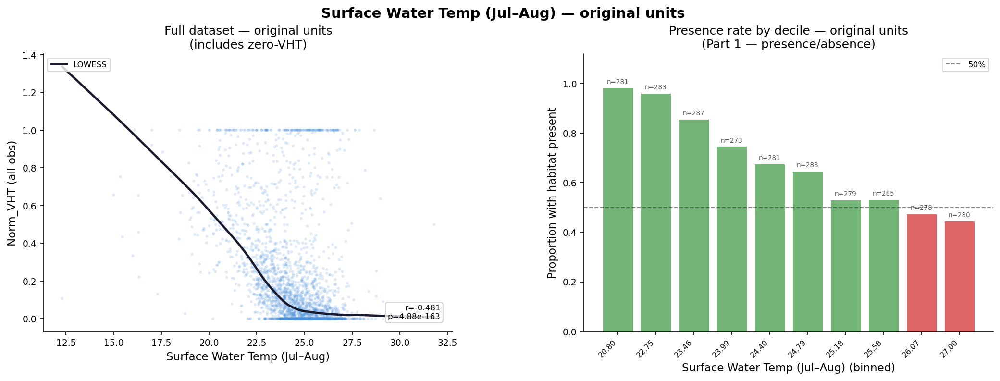

Saved: diagnostic_rawunits_wtemp_JA.png


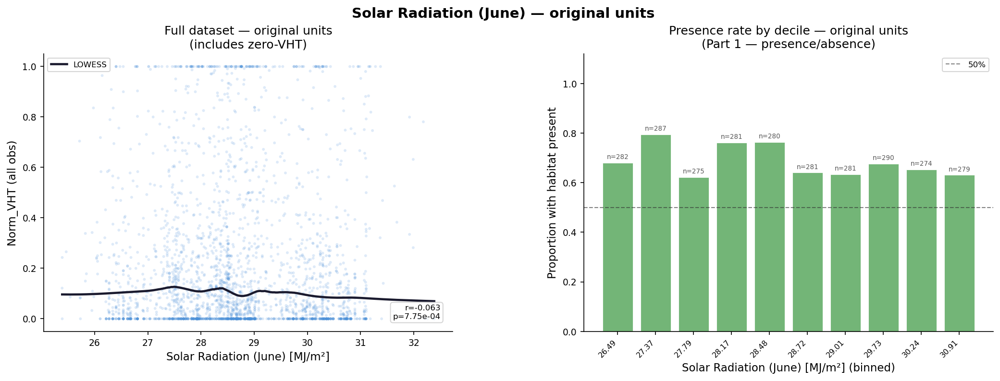

Saved: diagnostic_rawunits_tsr_june.png


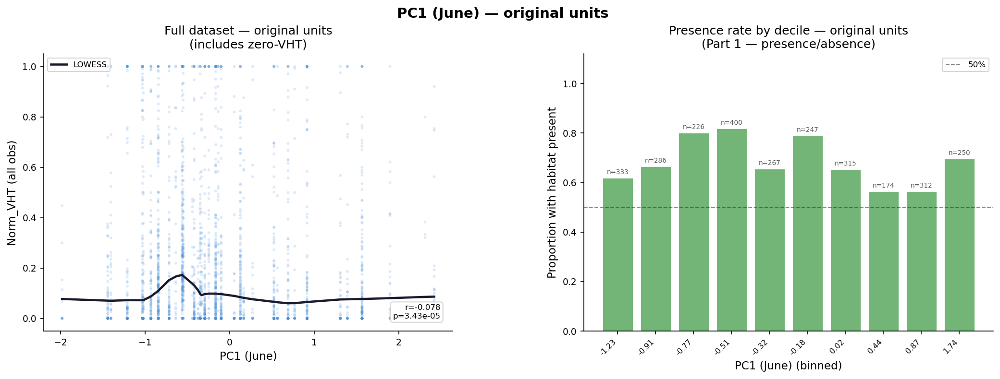

Saved: diagnostic_rawunits_PC1.png


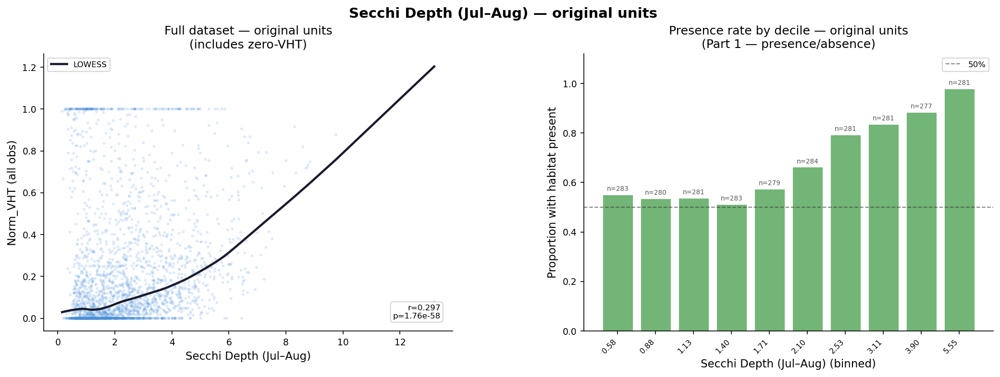

Saved: diagnostic_rawunits_secchi_JA.png


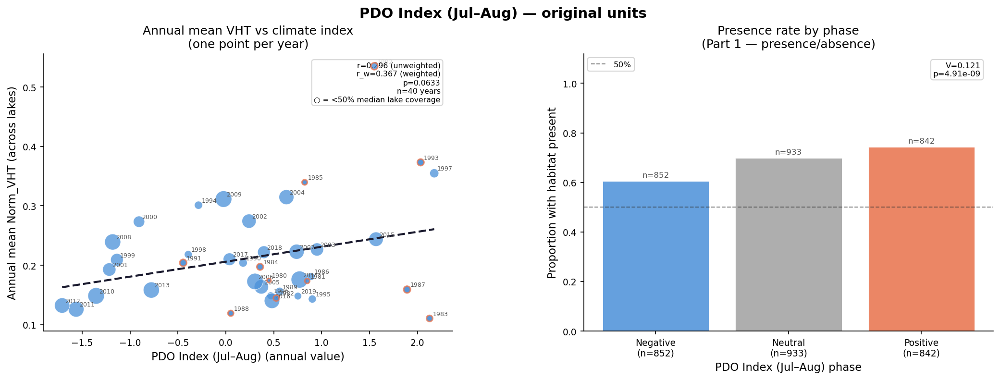

Saved: diagnostic_rawunits_PDO_JA.png


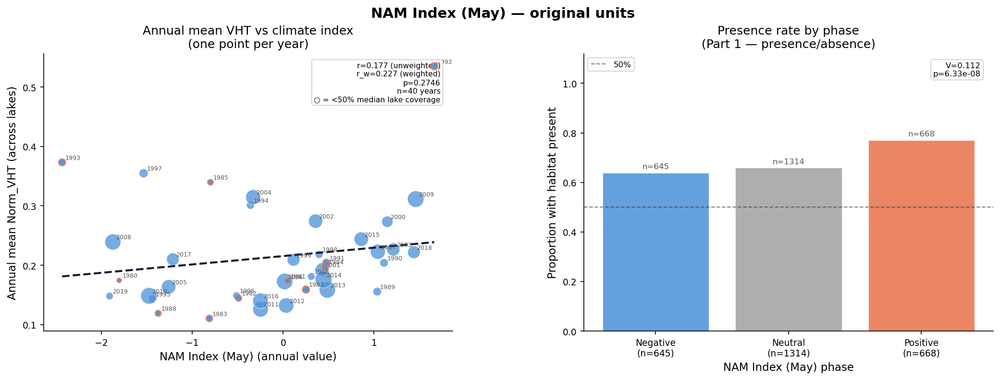

Saved: diagnostic_rawunits_NAM_May.png


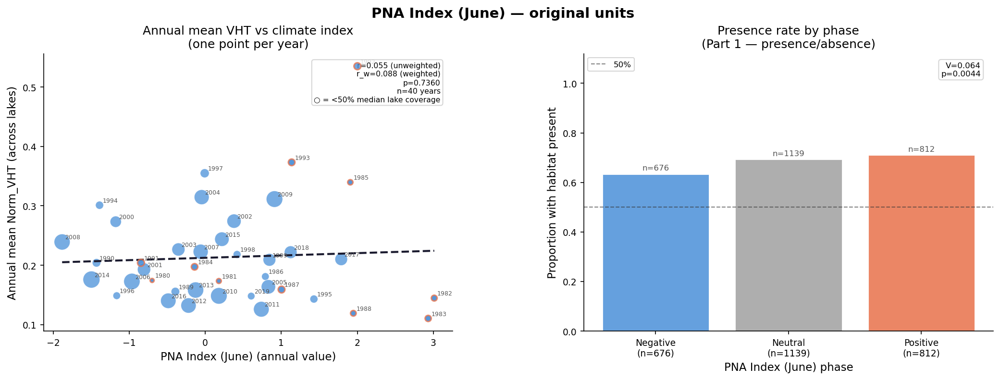

Saved: diagnostic_rawunits_PNA_June.png


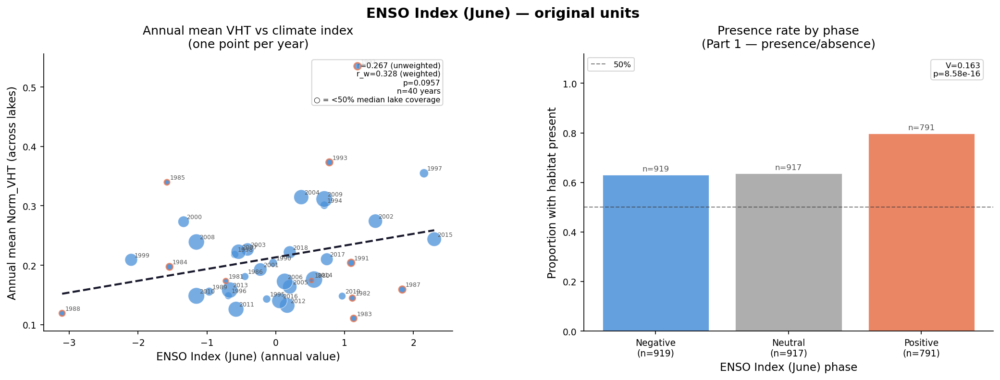

Saved: diagnostic_rawunits_ENSO_June.png


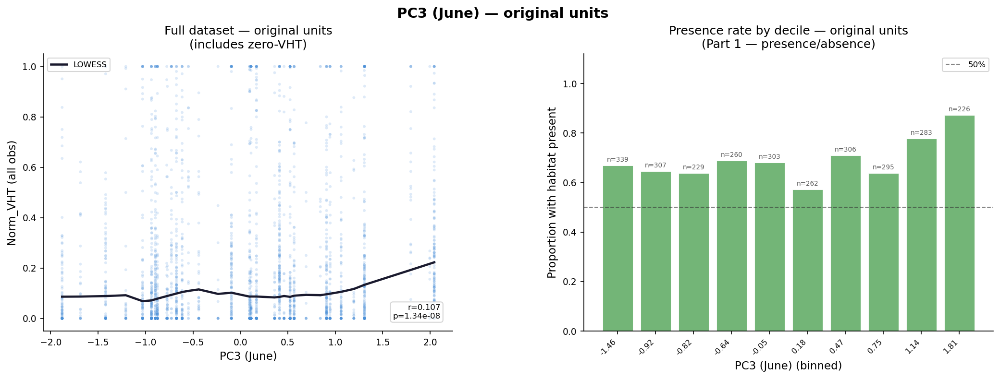

Saved: diagnostic_rawunits_PC3.png


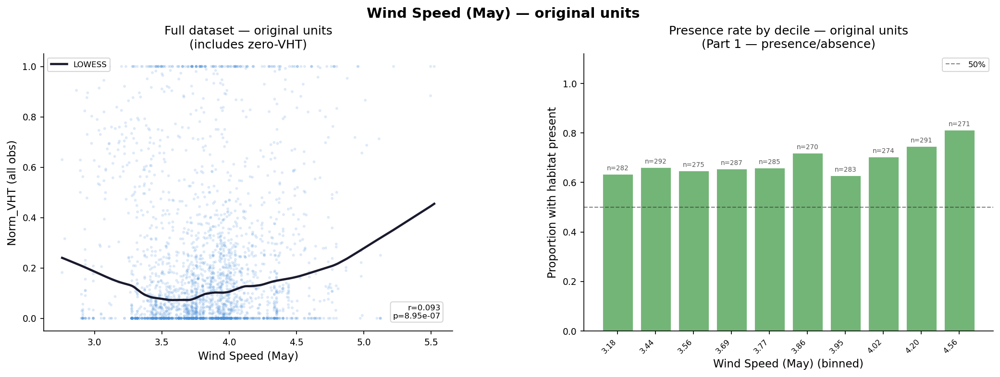

Saved: diagnostic_rawunits_windspeed_may.png

All 10 original-units diagnostic plots saved.


In [40]:

# DIAGNOSTIC PLOTS — ORIGINAL UNITS (df_raw)

df_plot = df_raw.copy()
for col in df_plot.select_dtypes(include='Float64').columns:
    df_plot[col] = df_plot[col].astype('float64')

# VHT present from raw meters
df_plot['VHT_present'] = (df_plot['Norm_VHT'] > 0).astype(int)

# Climate indices: use scaled values since raw values are SST not anomalies
climate_scaled = df_scaled[['lagoslakeid', 'year'] + 
                            [c for c in CLIMATE_INDICES if c in df_scaled.columns]].drop_duplicates()
df_plot = df_plot.merge(climate_scaled, on=['lagoslakeid', 'year'], 
                        how='left', suffixes=('', '_scaled'))
for idx_col in CLIMATE_INDICES:
    scaled_col = f'{idx_col}_scaled'
    if scaled_col in df_plot.columns:
        df_plot[idx_col] = df_plot[scaled_col]
        df_plot = df_plot.drop(columns=[scaled_col])

# Visualization settings ────────────────────────────────────────────────────
LOGTRANSFORM_PREDS = {'chla_JA', 'chla_june', 'chla_may'}

UNIT_CONVERSIONS = {
    'tsr_ja'   : (1e-6, 'Solar Radiation (Jul–Aug) [MJ/m²]'),
    'tsr_june' : (1e-6, 'Solar Radiation (June) [MJ/m²]'),
    'tsr_may'  : (1e-6, 'Solar Radiation (May) [MJ/m²]'),
}

for pred in PLOT_PREDS:
    is_index = pred in CLIMATE_INDICES
    fig = plt.figure(figsize=(17, 5))
    gs  = gridspec.GridSpec(1, 2, wspace=0.32, width_ratios=[1, 1])
    axes = [fig.add_subplot(gs[i]) for i in range(2)]

    # Panel 1 ───────────────────────────────────────────────────────────────
    ax = axes[0]
    xy_full = df_plot[[pred, TARGET_COL]].dropna()

    # Log-transform chlorophyll for visualization only
    if pred in LOGTRANSFORM_PREDS:
        xy_plot = xy_full.copy()
        xy_plot[pred] = np.log1p(xy_plot[pred])
        x_label_scatter = f'log({pretty(pred)})'
        x_label_bin     = f'log({pretty(pred)}) (binned)'
    else:
        xy_plot = xy_full.copy()
        x_label_scatter = f'{pretty(pred)}'
        x_label_bin     = f'{pretty(pred)} (binned)'

    # Unit conversion for solar radiation
    if pred in UNIT_CONVERSIONS:
        scale, unit_label = UNIT_CONVERSIONS[pred]
        xy_plot = xy_plot.copy()
        xy_plot[pred] = xy_plot[pred] * scale
        x_label_scatter = unit_label
        x_label_bin     = f'{unit_label} (binned)'

    if is_index:
        # Annual mean VHT vs index value — one point per year
        annual = df_plot[[pred, TARGET_COL, 'year']].dropna().groupby('year').agg(
            index_val = (pred,       'first'),
            mean_vht  = (TARGET_COL, 'mean'),
            n_lakes   = (TARGET_COL, 'count')
        ).reset_index()

        sc = ax.scatter(annual['index_val'], annual['mean_vht'],
                        s=annual['n_lakes'] * 2,
                        alpha=0.75, color=COL1_COLOR,
                        edgecolors='white', linewidth=0.5)

        for _, row in annual.iterrows():
            ax.annotate(str(int(row['year'])),
                        (row['index_val'], row['mean_vht']),
                        fontsize=6, color='#555555',
                        xytext=(3, 3), textcoords='offset points')

        weights = annual['n_lakes'].values
        slope, intercept, r, p, _ = linregress(annual['index_val'], annual['mean_vht'])
        x_line = np.linspace(annual['index_val'].min(), annual['index_val'].max(), 100)
        ax.plot(x_line, slope * x_line + intercept,
                color=LOWESS_COLOR, lw=2, linestyle='--')

        # Weighted Pearson r
        w    = weights / weights.sum()
        x_w  = (annual['index_val'] * w).sum()
        y_w  = (annual['mean_vht']  * w).sum()
        r_weighted = (w * (annual['index_val'] - x_w) *
                      (annual['mean_vht'] - y_w)).sum() / np.sqrt(
            (w * (annual['index_val'] - x_w)**2).sum() *
            (w * (annual['mean_vht']  - y_w)**2).sum()
        )

        # Flag low-coverage years with orange ring
        median_n     = annual['n_lakes'].median()
        low_coverage = annual['n_lakes'] < median_n * 0.5
        ax.scatter(annual.loc[low_coverage, 'index_val'],
                   annual.loc[low_coverage, 'mean_vht'],
                   s=annual.loc[low_coverage, 'n_lakes'] * 2,
                   alpha=0.75, color=COL1_COLOR,
                   edgecolors='#E8714A', linewidth=1.5, zorder=5)

        ax.text(0.97, 0.97,
                f'r={r:.3f} (unweighted)\nr_w={r_weighted:.3f} (weighted)\n'
                f'p={fmt_p(p)}\nn={len(annual)} years\n'
                f'○ = <50% median lake coverage',
                transform=ax.transAxes, ha='right', va='top',
                fontsize=7.5, bbox=dict(boxstyle='round,pad=0.3',
                                        fc='white', ec='#cccccc', alpha=0.8))
        ax.set(xlabel=f'{pretty(pred)} (annual value)',
               ylabel=f'Annual mean {TARGET_COL} (across lakes)',
               title='Annual mean VHT vs climate index\n(one point per year)')

    else:
        ax.scatter(xy_plot[pred], xy_plot[TARGET_COL],
                   alpha=SCATTER_ALPHA, s=SCATTER_SIZE,
                   color=COL1_COLOR, edgecolors='none')

        if len(xy_plot) > 20:
            sm = lowess(xy_plot[TARGET_COL].values,
                        xy_plot[pred].values, frac=LOWESS_FRAC)
            ax.plot(sm[:, 0], sm[:, 1], '-',
                    color=LOWESS_COLOR, lw=2.2, label='LOWESS')
            ax.legend(fontsize=8, loc='upper left')

        # Threshold lines for chlorophyll
        if pred in LOGTRANSFORM_PREDS:
            ax.axvline(np.log1p(2.7),  color='orange', lw=1.2,
                       ls='--', alpha=0.8, label='2.7 μg/L')
            ax.axvline(np.log1p(18.0), color='red',    lw=1.2,
                       ls='--', alpha=0.8, label='18.0 μg/L')
            ax.legend(fontsize=8, loc='upper right')

        r_full, p_full = scipy_stats.spearmanr(xy_plot[pred], xy_plot[TARGET_COL])
        ax.text(0.97, 0.04, f'r={r_full:.3f}\np={fmt_p(p_full)}',
                transform=ax.transAxes, ha='right', va='bottom',
                fontsize=8, bbox=dict(boxstyle='round,pad=0.3',
                                      fc='white', ec='#cccccc', alpha=0.8))
        ax.set(xlabel=x_label_scatter,
               ylabel=f'{TARGET_COL} (all obs)',
               title='Full dataset — original units\n(includes zero-VHT)')

    ax.spines[['top', 'right']].set_visible(False)

    # Panel 2: Presence rate ─────────────────────────────────────────────
    ax = axes[1]
    tmp = df_plot[[pred, 'VHT_present']].dropna().copy()

    # Apply same transforms to tmp as xy_plot
    if pred in LOGTRANSFORM_PREDS:
        tmp[pred] = np.log1p(tmp[pred])
    if pred in UNIT_CONVERSIONS:
        scale, _ = UNIT_CONVERSIONS[pred]
        tmp[pred] = tmp[pred] * scale

    if is_index:
        tmp['phase'] = tmp[pred].apply(phase_label)
        phase_order  = ['Negative', 'Neutral', 'Positive']
        phase_colors = ['#4A90D9', '#A0A0A0', '#E8714A']

        presence = tmp.groupby('phase')['VHT_present'].mean().reindex(phase_order)
        counts   = tmp.groupby('phase')['VHT_present'].count().reindex(phase_order)

        bars = ax.bar(range(len(phase_order)), presence.values,
                      color=phase_colors, edgecolor='white',
                      linewidth=0.5, alpha=0.85)
        for bar, n in zip(bars, counts.values):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + 0.01,
                    f'n={n}', ha='center', va='bottom',
                    fontsize=8, color='#555555')

        ct = pd.crosstab(tmp['phase'], tmp['VHT_present'])
        chi2_stat, chi_p, dof, _ = scipy_stats.chi2_contingency(ct)
        n_total   = ct.values.sum()
        cramers_v = np.sqrt(chi2_stat / (n_total * (min(ct.shape) - 1)))

        ax.text(0.97, 0.97, f'V={cramers_v:.3f}\np={fmt_p(chi_p)}',
                transform=ax.transAxes, ha='right', va='top',
                fontsize=8, bbox=dict(boxstyle='round,pad=0.3',
                                      fc='white', ec='#cccccc', alpha=0.8))

        ax.axhline(0.5, color='#333333', lw=1, ls='--', alpha=0.6, label='50%')
        ax.set_xticks(range(len(phase_order)))
        ax.set_xticklabels([f'{p}\n(n={counts[p]})' for p in phase_order], fontsize=9)
        ax.set(xlabel=f'{pretty(pred)} phase',
               ylabel='Proportion with habitat present',
               title='Presence rate by phase\n(Part 1 — presence/absence)')
        ax.legend(fontsize=8)

    else:
        try:
            tmp['bin']    = pd.qcut(tmp[pred], q=N_BINS, duplicates='drop')
            presence      = tmp.groupby('bin')['VHT_present'].mean()
            counts        = tmp.groupby('bin')['VHT_present'].count()
            centers       = tmp.groupby('bin')[pred].mean()
            n_bins_actual = len(presence)

            bar_colors = [COL3_COLOR if v >= 0.5 else '#D94A4A'
                          for v in presence.values]
            bars = ax.bar(range(n_bins_actual), presence.values,
                          color=bar_colors, edgecolor='white',
                          linewidth=0.5, alpha=0.85)
            for bar, n in zip(bars, counts.values):
                ax.text(bar.get_x() + bar.get_width()/2,
                        bar.get_height() + 0.01,
                        f'n={n}', ha='center', va='bottom',
                        fontsize=6.5, color='#555555')

            ax.axhline(0.5, color='#333333', lw=1,
                       ls='--', alpha=0.6, label='50%')
            ax.set_xticks(range(n_bins_actual))

            # For chla back-transform bin labels to μg/L
            if pred in LOGTRANSFORM_PREDS:
                ax.set_xticklabels([f'{np.expm1(x):.1f}' for x in centers.values],
                                    rotation=45, ha='right', fontsize=7.5)
            else:
                ax.set_xticklabels([f'{x:.2f}' for x in centers.values],
                                    rotation=45, ha='right', fontsize=7.5)
            ax.legend(fontsize=8)

        except Exception as e:
            ax.text(0.5, 0.5, f'Could not bin:\n{e}',
                    transform=ax.transAxes, ha='center', va='center',
                    fontsize=9, color='grey')

        ax.set(xlabel=x_label_bin,
               ylabel='Proportion with habitat present',
               title='Presence rate by decile — original units\n(Part 1 — presence/absence)')

    ax.set_ylim(0, 1.12)
    ax.spines[['top', 'right']].set_visible(False)

    fig.suptitle(f'{pretty(pred)} — original units',
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    safe_name = pred.replace('/', '_')
    fname = f'diagnostic_rawunits_{safe_name}.png'
    fig.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print(f'Saved: {fname}')

print(f'\nAll {len(PLOT_PREDS)} original-units diagnostic plots saved.')

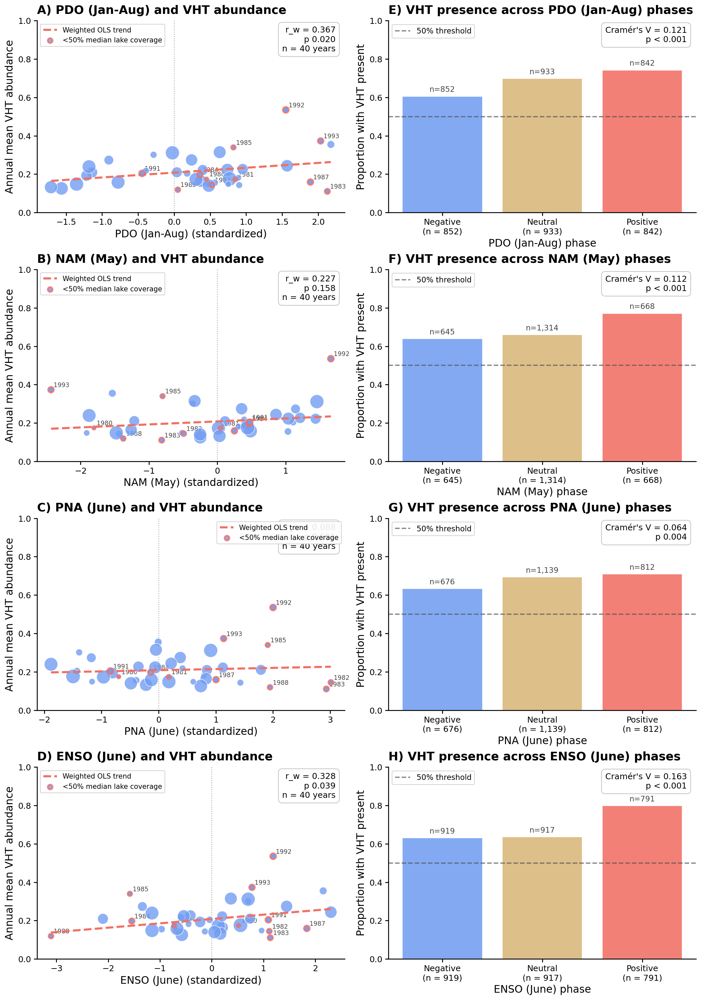

Saved: Figure_VHT_climate_indices_4x2.png


In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as scipy_stats
from statsmodels.nonparametric.smoothers_lowess import lowess

# ============================================================
# 4 × 2 FIGURE
# Climate indices × VHT abundance + VHT presence
#
# Rows:
#   1. PDO_JA
#   2. NAM_May
#   3. PNA_June
#   4. ENSO_June
#
# Columns:
#   Left  = index × VHT abundance
#   Right = index phase × VHT presence
# ============================================================

TARGET_COL = 'Norm_VHT'
YEAR_COL   = 'year'

INDEXES = [
    ('PDO_JA',    'PDO (Jan-Aug)'),
    ('NAM_May',   'NAM (May)'),
    ('PNA_June',  'PNA (June)'),
    ('ENSO_June', 'ENSO (June)')
]

PRES = dict(
    fig_w=14,
    fig_h=20,
    title_fs=17,
    label_fs=15,
    tick_fs=12,
    annot_fs=11,
    stat_fs=12,
    lw_main=3.0,
    lw_ref=1.8,
    scatter_s=45,
    scatter_a=0.35,
    bar_a=0.88,
    dpi=300,
    spine_lw=1.3,
)

# ============================================================
# COLORS
# ============================================================

C_MAIN  = '#729DF2'
C_TREND = '#F26F63'
C_LOW   = '#328C83'
C_HIGH  = '#D9B779'
C_WARN  = '#F26F63'

PHASE_COLORS = {
    'Negative': '#729DF2',
    'Neutral':  '#D9B779',
    'Positive': '#F26F63'
}

PHASE_ORDER = [
    'Negative',
    'Neutral',
    'Positive'
]

STAT_BOX = dict(
    boxstyle='round,pad=0.45',
    fc='white',
    ec='#bbbbbb',
    alpha=0.9
)


# ============================================================
# FUNCTIONS
# ============================================================

def fmt_p(p):
    return '< 0.001' if p < 0.001 else f'{p:.3f}'


def phase_label(v):
    if v < -0.5:
        return 'Negative'
    if v > 0.5:
        return 'Positive'
    return 'Neutral'


def apply_pres_style(ax, title):
    ax.spines[['top', 'right']].set_visible(False)

    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(
            PRES['spine_lw']
        )

    ax.tick_params(
        axis='both',
        labelsize=PRES['tick_fs'],
        width=1.3,
        length=5
    )

    ax.xaxis.label.set_size(
        PRES['label_fs']
    )

    ax.yaxis.label.set_size(
        PRES['label_fs']
    )

    ax.set_title(
        title,
        loc='left',
        fontsize=PRES['title_fs'],
        fontweight='bold',
        pad=10
    )


def annotate_bar_counts(ax, bars, counts, fontsize):
    for bar, n in zip(bars, counts):

        n = 0 if pd.isna(n) else int(n)

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f'n={n:,}',
            ha='center',
            va='bottom',
            fontsize=fontsize,
            color='#444444'
        )


def weighted_ols(x, y, w):

    X = np.column_stack([
        np.ones(len(x)),
        x
    ])

    W = np.diag(w)

    beta = np.linalg.solve(
        X.T @ W @ X,
        X.T @ W @ y
    )

    resid = y - X @ beta

    n, k = len(x), 2

    sigma2 = (
        w * resid ** 2
    ).sum() / (n - k)

    cov_beta = (
        sigma2 *
        np.linalg.inv(X.T @ W @ X)
    )

    se_slope = np.sqrt(
        cov_beta[1, 1]
    )

    t_stat = (
        beta[1] /
        se_slope
    )

    p_val = 2 * (
        1 -
        scipy_stats.t.cdf(
            abs(t_stat),
            df=n - k
        )
    )

    x_w = (x * w).sum()
    y_w = (y * w).sum()

    cov = (
        w *
        (x - x_w) *
        (y - y_w)
    ).sum()

    var_x = (
        w *
        (x - x_w) ** 2
    ).sum()

    var_y = (
        w *
        (y - y_w) ** 2
    ).sum()

    r_w = (
        cov /
        np.sqrt(var_x * var_y)
    )

    return beta, r_w, p_val


# ============================================================
# CREATE FIGURE — 4 ROWS × 2 COLUMNS
# ============================================================

fig, axes = plt.subplots(
    4,
    2,
    figsize=(PRES['fig_w'], PRES['fig_h']),
    constrained_layout=True
)


# ============================================================
# LOOP THROUGH CLIMATE INDICES
# ============================================================

for row, (INDEX_COL, INDEX_LABEL) in enumerate(INDEXES):

    # ========================================================
    # LEFT PANEL — INDEX × VHT ABUNDANCE
    # ========================================================

    ax = axes[row, 0]

    annual = (
        df_scaled[
            [INDEX_COL, TARGET_COL, YEAR_COL]
        ]
        .dropna()
        .groupby(YEAR_COL)
        .agg(
            index_val=(INDEX_COL, 'mean'),
            mean_vht=(TARGET_COL, 'mean'),
            n_lakes=(TARGET_COL, 'count')
        )
        .reset_index()
    )

    # Weighted regression
    w = (
        annual['n_lakes'].values /
        annual['n_lakes'].sum()
    )

    beta, r_w, p_w = weighted_ols(
        annual['index_val'].values,
        annual['mean_vht'].values,
        w
    )

    x_line = np.linspace(
        annual['index_val'].min(),
        annual['index_val'].max(),
        200
    )

    # Scatter
    ax.scatter(
        annual['index_val'],
        annual['mean_vht'],
        s=annual['n_lakes'] * 3,
        alpha=0.80,
        color=C_MAIN,
        edgecolors='white',
        linewidth=0.8,
        zorder=4
    )

    # Weighted OLS trend
    ax.plot(
        x_line,
        beta[0] + beta[1] * x_line,
        color=C_TREND,
        lw=PRES['lw_main'],
        ls='--',
        label='Weighted OLS trend',
        zorder=5
    )

    # Highlight low lake coverage
    median_n = annual['n_lakes'].median()

    low_cov = (
        annual['n_lakes'] <
        median_n * 0.5
    )

    ax.scatter(
        annual.loc[low_cov, 'index_val'],
        annual.loc[low_cov, 'mean_vht'],
        s=annual.loc[low_cov, 'n_lakes'] * 3,
        alpha=0.80,
        color=C_MAIN,
        edgecolors=C_WARN,
        linewidth=2.5,
        zorder=6,
        label='<50% median lake coverage'
    )

    # Label low-coverage years
    for _, r in annual[low_cov].iterrows():

        ax.annotate(
            str(int(r[YEAR_COL])),
            (
                r['index_val'],
                r['mean_vht']
            ),
            fontsize=PRES['annot_fs'] - 2,
            color='#444444',
            xytext=(4, 4),
            textcoords='offset points'
        )

    # Statistics
    ax.text(
        0.97,
        0.97,
        f'r_w = {r_w:.3f}\n'
        f'p {fmt_p(p_w)}\n'
        f'n = {len(annual)} years',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=PRES['stat_fs'],
        bbox=STAT_BOX
    )

    # Zero reference
    ax.axvline(
        0,
        color='#aaaaaa',
        lw=1.2,
        ls=':',
        zorder=1
    )

    # Y-axis 0–1
    ax.set_ylim(0, 1)

    ax.set_xlabel(
        f'{INDEX_LABEL} (standardized)'
    )

    ax.set_ylabel(
        'Annual mean VHT abundance'
    )

    ax.legend(
        fontsize=PRES['annot_fs'] - 1,
        framealpha=0.9,
        loc='best'
    )

    apply_pres_style(
        ax,
        f'{chr(65 + row)}) {INDEX_LABEL} and VHT abundance'
    )


    # ========================================================
    # RIGHT PANEL — INDEX PHASE × VHT PRESENCE
    # ========================================================

    ax = axes[row, 1]

    tmp = (
        df_scaled[
            [INDEX_COL, 'VHT_present']
        ]
        .dropna()
        .copy()
    )

    tmp['phase'] = (
        tmp[INDEX_COL]
        .apply(phase_label)
    )

    presence = (
        tmp.groupby('phase')['VHT_present']
        .mean()
        .reindex(PHASE_ORDER)
        .fillna(0)
    )

    counts = (
        tmp.groupby('phase')['VHT_present']
        .count()
        .reindex(PHASE_ORDER)
        .fillna(0)
    )

    # Bars
    bars = ax.bar(
        range(len(PHASE_ORDER)),
        presence.values,
        color=[
            PHASE_COLORS[p]
            for p in PHASE_ORDER
        ],
        edgecolor='white',
        linewidth=0.8,
        alpha=PRES['bar_a']
    )

    annotate_bar_counts(
        ax,
        bars,
        counts.values,
        PRES['annot_fs']
    )

    # Chi-square test
    ct = pd.crosstab(
        tmp['phase'],
        tmp['VHT_present']
    )

    chi2_stat, chi_p, _, _ = (
        scipy_stats.chi2_contingency(ct)
    )

    n_total = ct.values.sum()

    cramers_v = np.sqrt(
        chi2_stat /
        (
            n_total *
            (min(ct.shape) - 1)
        )
    )

    ax.text(
        0.97,
        0.97,
        f"Cramér's V = {cramers_v:.3f}\n"
        f"p {fmt_p(chi_p)}",
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=PRES['stat_fs'],
        bbox=STAT_BOX
    )

    # 50% reference
    ax.axhline(
        0.5,
        color='#555555',
        lw=PRES['lw_ref'],
        ls='--',
        alpha=0.7,
        label='50% threshold'
    )

    ax.set_xticks(
        range(len(PHASE_ORDER))
    )

    ax.set_xticklabels(
        [
            f'{p}\n(n = {int(counts[p]):,})'
            for p in PHASE_ORDER
        ]
    )

    # Y-axis 0–1
    ax.set_ylim(0, 1)

    ax.set_xlabel(
        f'{INDEX_LABEL} phase'
    )

    ax.set_ylabel(
        'Proportion with VHT present'
    )

    ax.legend(
        fontsize=PRES['annot_fs'],
        framealpha=0.9
    )

    apply_pres_style(
        ax,
        f'{chr(65 + row + 4)}) VHT presence across {INDEX_LABEL} phases'
    )


# ============================================================
# SAVE
# ============================================================

fig.savefig(
    'Figure_VHT_climate_indices_4x2.png',
    dpi=PRES['dpi'],
    bbox_inches='tight'
)

plt.show()
plt.close(fig)

print(
    'Saved: Figure_VHT_climate_indices_4x2.png'
)


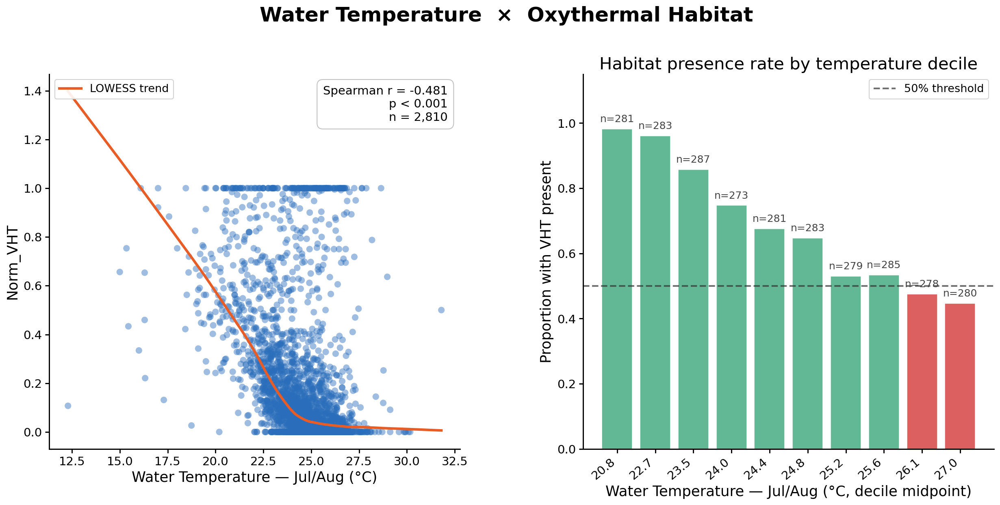

Saved: pres_water_temperature.png


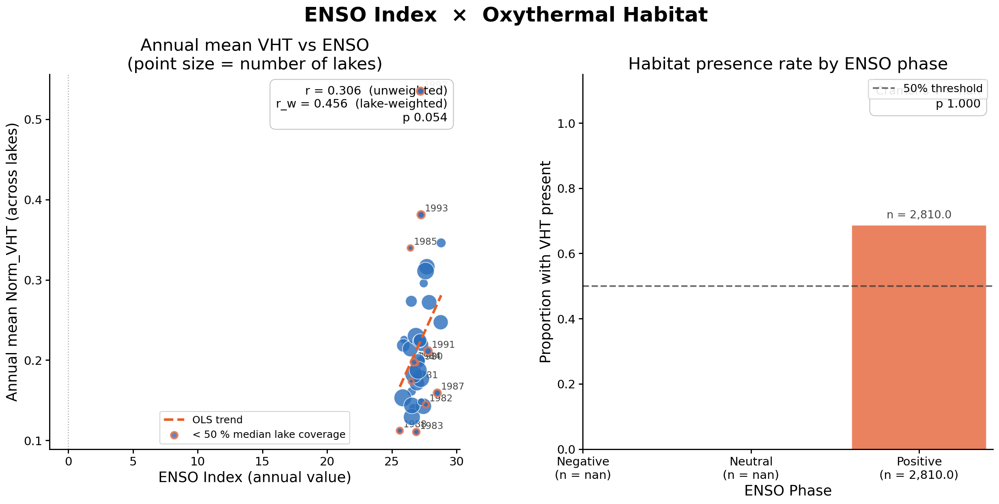

Saved: pres_enso_index.png


In [41]:
WTEMP_COL  = 'wtemp_JA'   
ENSO_COL   = 'ENSO_JA'       
TARGET_COL = 'Norm_VHT'   

# ── Presentation theme ────────────────────────────────────────────────────────
PRES = dict(
    fig_w        = 20,
    fig_h        = 8,
    title_fs     = 20,
    suptitle_fs  = 24,
    label_fs     = 17,
    tick_fs      = 14,
    annot_fs     = 13,
    stat_fs      = 14,
    lw_main      = 3.0,
    lw_ref       = 2.0,
    scatter_s    = 60,
    scatter_a    = 0.45,
    bar_a        = 0.88,
    dpi          = 180,
    spine_lw     = 1.4,
)

# Colour palette
C_MAIN   = '#2A6EBB'   # scatter / bars
C_LOWESS = '#E85D26'   # trend line
C_LOW    = '#4CAF87'   # bars ≥ 50% presence
C_HIGH   = '#D94A4A'   # bars < 50% presence
C_WARN   = '#E8714A'   # low-coverage ring (ENSO panel)

def fmt_p(p):
    if p < 0.001: return '< 0.001'
    if p < 0.01:  return f'{p:.3f}'
    return f'{p:.3f}'

def phase_label(v):
    if v < -0.5:  return 'Negative'
    if v >  0.5:  return 'Positive'
    return 'Neutral'

def apply_pres_style(ax):
    """Apply consistent presentation styling to an axes."""
    ax.spines[['top', 'right']].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(PRES['spine_lw'])
    ax.tick_params(axis='both', labelsize=PRES['tick_fs'], width=1.4, length=5)
    ax.xaxis.label.set_size(PRES['label_fs'])
    ax.yaxis.label.set_size(PRES['label_fs'])
    ax.title.set_size(PRES['title_fs'])

STAT_BOX = dict(boxstyle='round,pad=0.5', fc='white', ec='#bbbbbb', alpha=0.9)


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 1 — WATER TEMPERATURE
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(
    1, 2,
    figsize=(PRES['fig_w'], PRES['fig_h']),
    gridspec_kw=dict(wspace=0.30)
)

# ── Panel 1a: scatter + LOWESS ────────────────────────────────────────────────
ax = axes[0]
xy = df_plot[[WTEMP_COL, TARGET_COL]].dropna()

ax.scatter(
    xy[WTEMP_COL], xy[TARGET_COL],
    s=PRES['scatter_s'], alpha=PRES['scatter_a'],
    color=C_MAIN, edgecolors='none'
)

if len(xy) > 20:
    sm = lowess(xy[TARGET_COL].values, xy[WTEMP_COL].values, frac=0.4)
    ax.plot(sm[:, 0], sm[:, 1], '-', color=C_LOWESS,
            lw=PRES['lw_main'], label='LOWESS trend', zorder=5)
    ax.legend(fontsize=PRES['annot_fs'], framealpha=0.9, loc='upper left')

r, p = scipy_stats.spearmanr(xy[WTEMP_COL], xy[TARGET_COL])
ax.text(
    0.97, 0.97,
    f'Spearman r = {r:.3f}\np {fmt_p(p)}\nn = {len(xy):,}',
    transform=ax.transAxes, ha='right', va='top',
    fontsize=PRES['stat_fs'], bbox=STAT_BOX
)
ax.set(
    xlabel='Water Temperature — Jul/Aug (°C)',
    ylabel=f'{TARGET_COL}'
)
apply_pres_style(ax)

# ── Panel 1b: presence rate by decile ────────────────────────────────────────
ax = axes[1]
tmp = df_plot[[WTEMP_COL, 'VHT_present']].dropna().copy()

tmp['bin']   = pd.qcut(tmp[WTEMP_COL], q=10, duplicates='drop')
presence     = tmp.groupby('bin')['VHT_present'].mean()
counts       = tmp.groupby('bin')['VHT_present'].count()
centers      = tmp.groupby('bin')[WTEMP_COL].mean()
n_bins       = len(presence)

bar_colors = [C_LOW if v >= 0.5 else C_HIGH for v in presence.values]
bars = ax.bar(
    range(n_bins), presence.values,
    color=bar_colors, edgecolor='white',
    linewidth=0.8, alpha=PRES['bar_a']
)
for bar, n in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f'n={n}', ha='center', va='bottom',
        fontsize=PRES['annot_fs'] - 1, color='#444444'
    )

ax.axhline(0.5, color='#333333', lw=PRES['lw_ref'],
           ls='--', alpha=0.7, label='50% threshold')
ax.set_xticks(range(n_bins))
ax.set_xticklabels(
    [f'{x:.1f}' for x in centers.values],
    rotation=40, ha='right', fontsize=PRES['tick_fs']
)
ax.set_ylim(0, 1.15)
ax.set(
    xlabel='Water Temperature — Jul/Aug (°C, decile midpoint)',
    ylabel='Proportion with VHT present',
    title='Habitat presence rate by temperature decile'
)
ax.legend(fontsize=PRES['annot_fs'], framealpha=0.9)
apply_pres_style(ax)

fig.suptitle('Water Temperature  ×  Oxythermal Habitat',
             fontsize=PRES['suptitle_fs'], fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig('pres_water_temperature.png', dpi=PRES['dpi'], bbox_inches='tight')
plt.show(); plt.close(fig)
print('Saved: pres_water_temperature.png')


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 2 — ENSO INDEX
# ══════════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(
    1, 2,
    figsize=(PRES['fig_w'], PRES['fig_h']),
    gridspec_kw=dict(wspace=0.30)
)

# Aggregate to annual means (one point per year)
annual = (
    df_plot[[ENSO_COL, TARGET_COL, 'year']].dropna()
    .groupby('year')
    .agg(
        index_val = (ENSO_COL,   'first'),
        mean_vht  = (TARGET_COL, 'mean'),
        n_lakes   = (TARGET_COL, 'count')
    )
    .reset_index()
)

# ── Panel 2a: annual scatter ──────────────────────────────────────────────────
ax = axes[0]

sc = ax.scatter(
    annual['index_val'], annual['mean_vht'],
    s=annual['n_lakes'] * 3,
    alpha=0.80, color=C_MAIN,
    edgecolors='white', linewidth=0.8, zorder=4
)

# Annotate only low-coverage years (added after low_cov is defined below)

# OLS trend line
slope, intercept, r_ols, p_ols, _ = linregress(
    annual['index_val'], annual['mean_vht']
)
x_line = np.linspace(annual['index_val'].min(), annual['index_val'].max(), 200)
ax.plot(x_line, slope * x_line + intercept,
        color=C_LOWESS, lw=PRES['lw_main'], ls='--', label='OLS trend', zorder=5)

# Weighted Pearson r
w    = annual['n_lakes'].values / annual['n_lakes'].sum()
x_w  = (annual['index_val'] * w).sum()
y_w  = (annual['mean_vht']  * w).sum()
r_w  = (
    (w * (annual['index_val'] - x_w) * (annual['mean_vht'] - y_w)).sum()
    / np.sqrt(
        (w * (annual['index_val'] - x_w)**2).sum() *
        (w * (annual['mean_vht']  - y_w)**2).sum()
    )
)

# Flag low-coverage years
median_n     = annual['n_lakes'].median()
low_cov      = annual['n_lakes'] < median_n * 0.5
ax.scatter(
    annual.loc[low_cov, 'index_val'],
    annual.loc[low_cov, 'mean_vht'],
    s=annual.loc[low_cov, 'n_lakes'] * 3,
    alpha=0.80, color=C_MAIN,
    edgecolors=C_WARN, linewidth=2.5, zorder=6,
    label='< 50 % median lake coverage'
)

# Annotate only the low-coverage (orange-ringed) dots
for _, row in annual[low_cov].iterrows():
    ax.annotate(
        str(int(row['year'])),
        (row['index_val'], row['mean_vht']),
        fontsize=PRES['annot_fs'] - 2, color='#444444',
        xytext=(4, 4), textcoords='offset points'
    )

ax.text(
    0.97, 0.97,
    (f'r = {r_ols:.3f}  (unweighted)\n'
     f'r_w = {r_w:.3f}  (lake-weighted)\n'
     f'p {fmt_p(p_ols)}'),
    transform=ax.transAxes, ha='right', va='top',
    fontsize=PRES['stat_fs'], bbox=STAT_BOX
)
ax.axvline(0, color='#aaaaaa', lw=1.2, ls=':', zorder=1)   # neutral reference

ax.set(
    xlabel='ENSO Index (annual value)',
    ylabel=f'Annual mean {TARGET_COL} (across lakes)',
    title='Annual mean VHT vs ENSO\n(point size = number of lakes)'
)
ax.legend(fontsize=PRES['annot_fs'] - 1, framealpha=0.9)
apply_pres_style(ax)

# ── Panel 2b: presence rate by ENSO phase ────────────────────────────────────
ax = axes[1]

tmp = df_plot[[ENSO_COL, 'VHT_present']].dropna().copy()
tmp['phase'] = tmp[ENSO_COL].apply(phase_label)

PHASE_ORDER  = ['Negative', 'Neutral', 'Positive']
PHASE_COLORS = ['#4A90D9', '#A0A0A0', '#E8714A']

presence = tmp.groupby('phase')['VHT_present'].mean().reindex(PHASE_ORDER)
counts   = tmp.groupby('phase')['VHT_present'].count().reindex(PHASE_ORDER)

bars = ax.bar(
    range(len(PHASE_ORDER)), presence.values,
    color=PHASE_COLORS, edgecolor='white',
    linewidth=0.8, alpha=PRES['bar_a']
)
for bar, (phase, n) in zip(bars, counts.items()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f'n = {n:,}', ha='center', va='bottom',
        fontsize=PRES['annot_fs'], color='#444444'
    )

# Chi-square + Cramér's V
ct = pd.crosstab(tmp['phase'], tmp['VHT_present'])
chi2_stat, chi_p, _, _ = scipy_stats.chi2_contingency(ct)
n_total   = ct.values.sum()
cramers_v = np.sqrt(chi2_stat / (n_total * (min(ct.shape) - 1)))

ax.text(
    0.97, 0.97,
    f"Cramér's V = {cramers_v:.3f}\np {fmt_p(chi_p)}",
    transform=ax.transAxes, ha='right', va='top',
    fontsize=PRES['stat_fs'], bbox=STAT_BOX
)

ax.axhline(0.5, color='#333333', lw=PRES['lw_ref'],
           ls='--', alpha=0.7, label='50% threshold')
ax.set_xticks(range(len(PHASE_ORDER)))
ax.set_xticklabels(
    [f'{p}\n(n = {counts[p]:,})' for p in PHASE_ORDER],
    fontsize=PRES['tick_fs'] + 1
)
ax.set_ylim(0, 1.15)
ax.set(
    xlabel='ENSO Phase',
    ylabel='Proportion with VHT present',
    title='Habitat presence rate by ENSO phase'
)
ax.legend(fontsize=PRES['annot_fs'], framealpha=0.9)
apply_pres_style(ax)

fig.suptitle('ENSO Index  ×  Oxythermal Habitat',
             fontsize=PRES['suptitle_fs'], fontweight='bold', y=1.02)
plt.tight_layout()
fig.savefig('pres_enso_index.png', dpi=PRES['dpi'], bbox_inches='tight')
plt.show(); plt.close(fig)
print('Saved: pres_enso_index.png')

June ENSO Index in df_scaled:
count    2.627000e+03
mean     3.471571e-15
std      1.000000e+00
min     -3.105095e+00
25%     -6.702997e-01
50%      1.289079e-01
75%      5.563910e-01
max      2.303496e+00
Name: ENSO_June, dtype: float64

Surface Water Temperature (Jul-Aug) in df_scaled:
count    2.627000e+03
mean    -1.081907e-17
std      1.000000e+00
min     -6.914249e+00
25%     -5.330795e-01
50%      1.115764e-01
75%      6.585033e-01
max      4.177102e+00
Name: wtemp_JA, dtype: float64


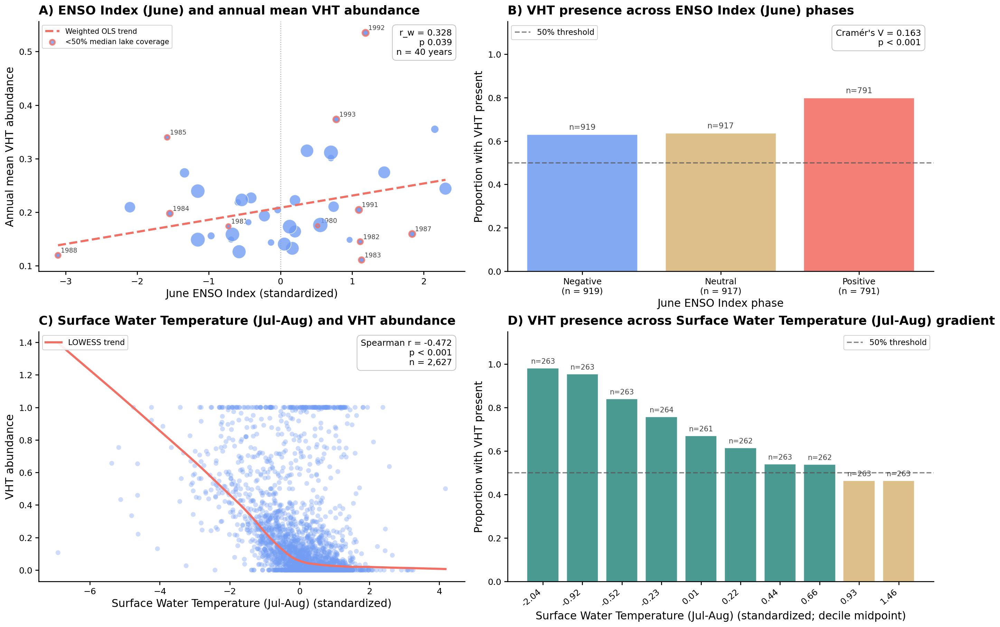

Saved: Figure_VHT_ENSO_wtemp_4panel.png


In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as scipy_stats
from statsmodels.nonparametric.smoothers_lowess import lowess

# ============================================================
# COMBINED 4-PANEL FIGURE
# ENSO x oxythermal (VHT) habitat + Water temperature
# ============================================================

WTEMP_COL   = 'wtemp_JA'
ENSO_COL    = 'ENSO_June'
TARGET_COL  = 'Norm_VHT'
YEAR_COL    = 'year'          # <-- adjust if needed

WTEMP_LABEL = 'Surface Water Temperature (Jul-Aug)'
ENSO_LABEL  = 'June ENSO Index'

PRES = dict(
    fig_w=18, fig_h=12,
    title_fs=17, suptitle_fs=23,
    label_fs=15, tick_fs=12,
    annot_fs=11, stat_fs=12,
    lw_main=3.0, lw_ref=1.8,
    scatter_s=45, scatter_a=0.35,
    bar_a=0.88, dpi=300, spine_lw=1.3,
)

C_MAIN   = '#729DF2' #blue
C_TREND  = '#F26F63' #dark orange
C_LOW    = '#328C83' 
C_HIGH   = '#D9B779' 
C_WARN   = '#F26F63' 
PHASE_COLORS = {'Negative': '#729DF2', 'Neutral': '#D9B779', 'Positive': '#F26F63'}
                            #blue                  #light tan           #dark orange
PHASE_ORDER  = ['Negative', 'Neutral', 'Positive']

STAT_BOX = dict(boxstyle='round,pad=0.45', fc='white', ec='#bbbbbb', alpha=0.9)


def fmt_p(p):
    return '< 0.001' if p < 0.001 else f'{p:.3f}'


def phase_label(v):
    if v < -0.5:
        return 'Negative'
    if v > 0.5:
        return 'Positive'
    return 'Neutral'


def apply_pres_style(ax, title):
    ax.spines[['top', 'right']].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(PRES['spine_lw'])
    ax.tick_params(axis='both', labelsize=PRES['tick_fs'], width=1.3, length=5)
    ax.xaxis.label.set_size(PRES['label_fs'])
    ax.yaxis.label.set_size(PRES['label_fs'])
    ax.set_title(title, loc='left', fontsize=PRES['title_fs'], fontweight='bold', pad=10)


def annotate_bar_counts(ax, bars, counts, fontsize):
    for bar, n in zip(bars, counts):
        n = 0 if pd.isna(n) else int(n)
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
                f'n={n:,}', ha='center', va='bottom', fontsize=fontsize, color='#444444')


def weighted_ols(x, y, w):
    X = np.column_stack([np.ones(len(x)), x])
    W = np.diag(w)
    beta = np.linalg.solve(X.T @ W @ X, X.T @ W @ y)
    resid = y - X @ beta
    n, k = len(x), 2
    sigma2 = (w * resid ** 2).sum() / (n - k)
    cov_beta = sigma2 * np.linalg.inv(X.T @ W @ X)
    se_slope = np.sqrt(cov_beta[1, 1])
    t_stat = beta[1] / se_slope
    p_val = 2 * (1 - scipy_stats.t.cdf(abs(t_stat), df=n - k))
    x_w = (x * w).sum()
    y_w = (y * w).sum()
    cov = (w * (x - x_w) * (y - y_w)).sum()
    var_x = (w * (x - x_w) ** 2).sum()
    var_y = (w * (y - y_w) ** 2).sum()
    r_w = cov / np.sqrt(var_x * var_y)
    return beta, r_w, p_val


print(f"{ENSO_LABEL} in df_scaled:")
print(df_scaled[ENSO_COL].describe())
print(f"\n{WTEMP_LABEL} in df_scaled:")
print(df_scaled[WTEMP_COL].describe())

# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(PRES['fig_w'], PRES['fig_h']), constrained_layout=True)
axA, axB, axC, axD = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]

# ============================================================
# PANEL A — ENSO x annual mean VHT abundance (weighted)
# ============================================================
ax = axA
annual = (
    df_scaled[[ENSO_COL, TARGET_COL, YEAR_COL]]
    .dropna()
    .groupby(YEAR_COL)
    .agg(index_val=(ENSO_COL, 'mean'), mean_vht=(TARGET_COL, 'mean'), n_lakes=(TARGET_COL, 'count'))
    .reset_index()
)
w = annual['n_lakes'].values / annual['n_lakes'].sum()
beta, r_w, p_w = weighted_ols(annual['index_val'].values, annual['mean_vht'].values, w)
x_line = np.linspace(annual['index_val'].min(), annual['index_val'].max(), 200)

ax.scatter(annual['index_val'], annual['mean_vht'], s=annual['n_lakes'] * 3, alpha=0.80,
           color=C_MAIN, edgecolors='white', linewidth=0.8, zorder=4)
ax.plot(x_line, beta[0] + beta[1] * x_line, color=C_TREND, lw=PRES['lw_main'], ls='--',
        label='Weighted OLS trend', zorder=5)

median_n = annual['n_lakes'].median()
low_cov = annual['n_lakes'] < median_n * 0.5
ax.scatter(annual.loc[low_cov, 'index_val'], annual.loc[low_cov, 'mean_vht'],
           s=annual.loc[low_cov, 'n_lakes'] * 3, alpha=0.80, color=C_MAIN,
           edgecolors=C_WARN, linewidth=2.5, zorder=6, label='<50% median lake coverage')

for _, row in annual[low_cov].iterrows():
    ax.annotate(str(int(row[YEAR_COL])), (row['index_val'], row['mean_vht']),
                fontsize=PRES['annot_fs'] - 2, color='#444444',
                xytext=(4, 4), textcoords='offset points')

ax.text(0.97, 0.97, f'r_w = {r_w:.3f}\np {fmt_p(p_w)}\nn = {len(annual)} years',
        transform=ax.transAxes, ha='right', va='top', fontsize=PRES['stat_fs'], bbox=STAT_BOX)
ax.axvline(0, color='#aaaaaa', lw=1.2, ls=':', zorder=1)

ax.set_xlabel(f'{ENSO_LABEL} (standardized)')
ax.set_ylabel('Annual mean VHT abundance')
ax.legend(fontsize=PRES['annot_fs'] - 1, framealpha=0.9)
apply_pres_style(ax, f'A) ENSO Index (June) and annual mean VHT abundance')

# ============================================================
# PANEL B — ENSO phase x VHT presence
# ============================================================
ax = axB
tmp = df_scaled[[ENSO_COL, 'VHT_present']].dropna().copy()
tmp['phase'] = tmp[ENSO_COL].apply(phase_label)

presence = tmp.groupby('phase')['VHT_present'].mean().reindex(PHASE_ORDER).fillna(0)
counts   = tmp.groupby('phase')['VHT_present'].count().reindex(PHASE_ORDER).fillna(0)

bars = ax.bar(range(len(PHASE_ORDER)), presence.values,
              color=[PHASE_COLORS[p] for p in PHASE_ORDER],
              edgecolor='white', linewidth=0.8, alpha=PRES['bar_a'])
annotate_bar_counts(ax, bars, counts.values, PRES['annot_fs'])

ct = pd.crosstab(tmp['phase'], tmp['VHT_present'])
chi2_stat, chi_p, _, _ = scipy_stats.chi2_contingency(ct)
n_total = ct.values.sum()
cramers_v = np.sqrt(chi2_stat / (n_total * (min(ct.shape) - 1)))

ax.text(0.97, 0.97, f"Cramér's V = {cramers_v:.3f}\np {fmt_p(chi_p)}",
        transform=ax.transAxes, ha='right', va='top', fontsize=PRES['stat_fs'], bbox=STAT_BOX)
ax.axhline(0.5, color='#555555', lw=PRES['lw_ref'], ls='--', alpha=0.7, label='50% threshold')

ax.set_xticks(range(len(PHASE_ORDER)))
ax.set_xticklabels([f'{p}\n(n = {int(counts[p]):,})' for p in PHASE_ORDER])
ax.set_ylim(0, 1.15)
ax.set_xlabel(f'{ENSO_LABEL} phase')
ax.set_ylabel('Proportion with VHT present')
ax.legend(fontsize=PRES['annot_fs'], framealpha=0.9)
apply_pres_style(ax, f'B) VHT presence across ENSO Index (June) phases')

# ============================================================
# PANEL C — Water temp x VHT abundance
# ============================================================
xy = df_scaled[[WTEMP_COL, TARGET_COL]].dropna()
ax = axC

ax.scatter(xy[WTEMP_COL], xy[TARGET_COL], s=PRES['scatter_s'], alpha=PRES['scatter_a'],
           color=C_MAIN, edgecolors='none')

if len(xy) > 20:
    sm = lowess(xy[TARGET_COL].values, xy[WTEMP_COL].values, frac=0.4)
    ax.plot(sm[:, 0], sm[:, 1], color=C_TREND, lw=PRES['lw_main'], label='LOWESS trend', zorder=5)
    ax.legend(fontsize=PRES['annot_fs'], framealpha=0.9, loc='upper left')

r, p = scipy_stats.spearmanr(xy[WTEMP_COL], xy[TARGET_COL])
ax.text(0.97, 0.97, f'Spearman r = {r:.3f}\np {fmt_p(p)}\nn = {len(xy):,}',
        transform=ax.transAxes, ha='right', va='top', fontsize=PRES['stat_fs'], bbox=STAT_BOX)

ax.set_xlabel(f'{WTEMP_LABEL} (standardized)')
ax.set_ylabel('VHT abundance')
apply_pres_style(ax, f'C) {WTEMP_LABEL} and VHT abundance')

# ============================================================
# PANEL D — Water temp x VHT presence (decile bins)
# ============================================================
ax = axD
tmp = df_scaled[[WTEMP_COL, 'VHT_present']].dropna().copy()
tmp['bin'] = pd.qcut(tmp[WTEMP_COL], q=10, duplicates='drop')

presence = tmp.groupby('bin', observed=True)['VHT_present'].mean()
counts   = tmp.groupby('bin', observed=True)['VHT_present'].count()
centers  = tmp.groupby('bin', observed=True)[WTEMP_COL].mean()
n_bins   = len(presence)

bar_colors = [C_LOW if v >= 0.5 else C_HIGH for v in presence.values]
bars = ax.bar(range(n_bins), presence.values, color=bar_colors,
              edgecolor='white', linewidth=0.8, alpha=PRES['bar_a'])
annotate_bar_counts(ax, bars, counts.values, PRES['annot_fs'] - 1)

ax.axhline(0.5, color='#555555', lw=PRES['lw_ref'], ls='--', alpha=0.7, label='50% threshold')
ax.set_xticks(range(n_bins))
ax.set_xticklabels([f'{x:.2f}' for x in centers.values], rotation=40, ha='right')
ax.set_ylim(0, 1.15)
ax.set_xlabel(f'{WTEMP_LABEL} (standardized; decile midpoint)')
ax.set_ylabel('Proportion with VHT present')
ax.legend(fontsize=PRES['annot_fs'], framealpha=0.9)
apply_pres_style(ax, f'D) VHT presence across Surface Water Temperature (Jul-Aug) gradient')

# ============================================================
# SAVE (no suptitle)
# ============================================================
fig.savefig('Figure_VHT_ENSO_wtemp_4panel.png', dpi=PRES['dpi'], bbox_inches='tight')
plt.show()
plt.close(fig)

print('Saved: Figure_VHT_ENSO_wtemp_4panel.png')

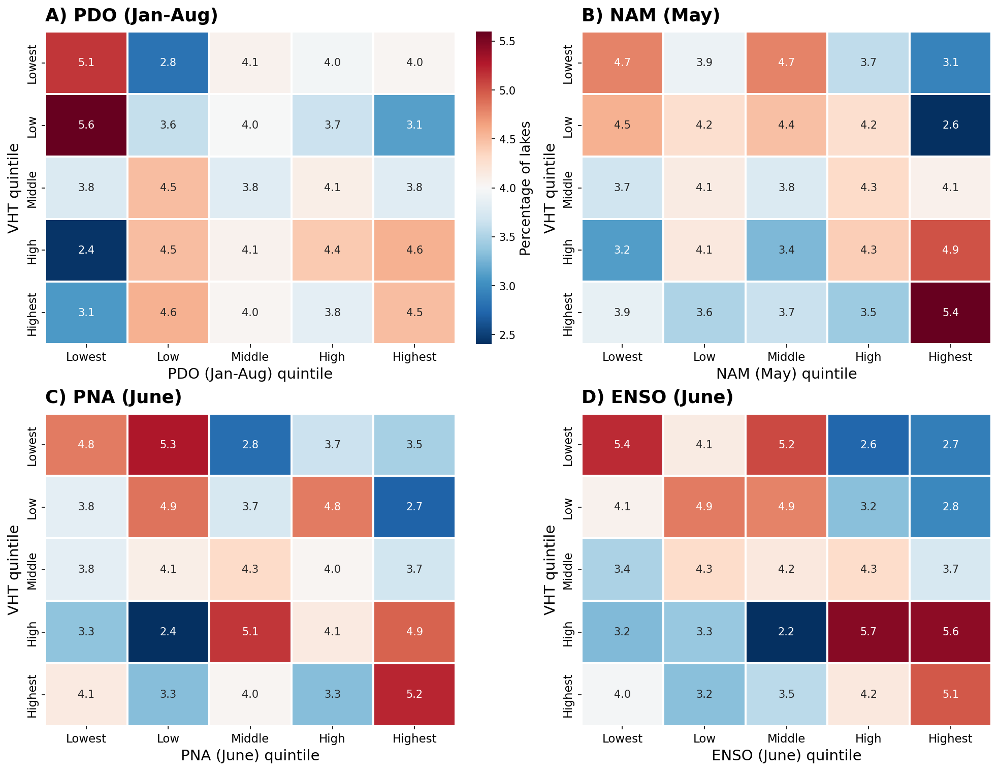

Saved: Figure_VHT_climate_heatmaps_diverging.png


In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm

# ============================================================
# FIGURE 2 — CLIMATE × VHT DISTRIBUTION HEATMAPS
#
# x = climate-index quintile
# y = VHT quintile
# color = % of lakes
#
# Diverging colors centered at 4%.
# 4% = expected proportion if climate and VHT are independent.
# ============================================================

TARGET_COL = 'Norm_VHT'

INDEXES = [
    ('PDO_JA',    'PDO (Jan-Aug)'),
    ('NAM_May',   'NAM (May)'),
    ('PNA_June',  'PNA (June)'),
    ('ENSO_June', 'ENSO (June)')
]

GROUP_LABELS = [
    'Lowest',
    'Low',
    'Middle',
    'High',
    'Highest'
]


def make_quantile_groups(series, n_groups=5):
    """
    Divide values into approximately equal-sized quantile groups.
    Ranking first prevents qcut problems caused by tied values.
    """

    ranks = series.rank(method='first')

    return pd.qcut(
        ranks,
        q=n_groups,
        labels=False
    )


# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 10),
    constrained_layout=True
)

axes = axes.flatten()


for i, (index_col, index_label) in enumerate(INDEXES):

    ax = axes[i]

    tmp = (
        df_scaled[
            [index_col, TARGET_COL]
        ]
        .dropna()
        .copy()
    )

    # --------------------------------------------------------
    # Climate quintiles
    # --------------------------------------------------------

    tmp['Climate group'] = make_quantile_groups(
        tmp[index_col],
        n_groups=5
    )

    # --------------------------------------------------------
    # VHT quintiles
    # --------------------------------------------------------

    tmp['VHT group'] = make_quantile_groups(
        tmp[TARGET_COL],
        n_groups=5
    )

    # --------------------------------------------------------
    # Convert groups to labels
    # --------------------------------------------------------

    tmp['Climate group'] = tmp[
        'Climate group'
    ].map(
        dict(enumerate(GROUP_LABELS))
    )

    tmp['VHT group'] = tmp[
        'VHT group'
    ].map(
        dict(enumerate(GROUP_LABELS))
    )

    # --------------------------------------------------------
    # Percentage of lakes in each combination
    # --------------------------------------------------------

    table = pd.crosstab(
        tmp['VHT group'],
        tmp['Climate group'],
        normalize=True
    ) * 100

    table = table.reindex(
        index=GROUP_LABELS,
        columns=GROUP_LABELS,
        fill_value=0
    )

    # --------------------------------------------------------
    # Diverging normalization
    #
    # 4% = expected cell frequency if independent
    # --------------------------------------------------------

    expected = 4.0

    max_deviation = max(
        expected - table.values.min(),
        table.values.max() - expected
    )

    norm = TwoSlopeNorm(
        vmin=expected - max_deviation,
        vcenter=expected,
        vmax=expected + max_deviation
    )

    # --------------------------------------------------------
    # Diverging heatmap
    # --------------------------------------------------------

    sns.heatmap(
        table,
        ax=ax,

        # Blue = below expected
        # White = expected
        # Orange = above expected
        cmap='RdBu_r',

        norm=norm,

        annot=True,
        fmt='.1f',

        linewidths=1,
        linecolor='white',

        cbar=(i == 0),

        annot_kws={
            'fontsize': 10
        }
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_xlabel(
        f'{index_label} quintile',
        fontsize=14
    )

    ax.set_ylabel(
        'VHT quintile',
        fontsize=14
    )

    ax.set_title(
        f'{chr(65+i)}) {index_label}',
        loc='left',
        fontsize=17,
        fontweight='bold',
        pad=10
    )

    ax.tick_params(
        labelsize=11
    )


# ============================================================
# COLORBAR LABEL
# ============================================================

cbar = axes[0].collections[0].colorbar

cbar.set_label(
    'Percentage of lakes',
    fontsize=13
)

cbar.ax.tick_params(
    labelsize=10
)


# ============================================================
# SAVE
# ============================================================

plt.show()
plt.close(fig)

print(
    'Saved: Figure_VHT_climate_heatmaps_diverging.png'
)


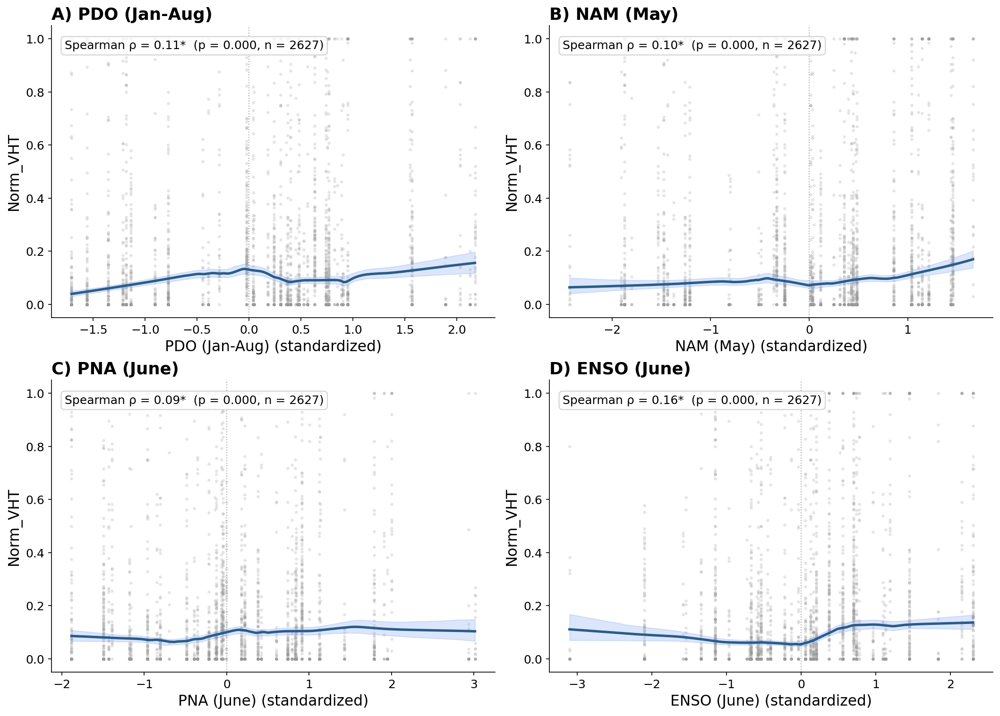

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as scipy_stats
from statsmodels.nonparametric.smoothers_lowess import lowess

# ============================================================
# FIGURE 4 (v2) — CLIMATE INDEX ↔ VHT RELATIONSHIPS, WITH
# STATISTICAL SUPPORT
#
# Why this differs from the decile-median version:
#   - A LOESS-smoothed trend replaces the jagged decile line,
#     so panel-to-panel wiggles reflect an actual local
#     average rather than bin-edge artifacts.
#   - A bootstrap confidence band on the smoothed trend
#     (resampling lakes, not just showing raw-data IQR) shows
#     where the trend itself is uncertain vs. where it's solid.
#   - Spearman rho + p-value is reported for each index, so the
#     panel isn't just "does this look like it's going up" —
#     there's an actual monotonic-association statistic.
#   - Individual lakes are shown as a faint scatter, so the
#     reader can see sample density and outliers, not just a
#     summary line.
# ============================================================

TARGET_COL = 'Norm_VHT'

INDEXES = [
    ('PDO_JA',    'PDO (Jan-Aug)'),
    ('NAM_May',   'NAM (May)'),
    ('PNA_June',  'PNA (June)'),
    ('ENSO_June', 'ENSO (June)')
]

N_BOOT = 1000
LOWESS_FRAC = 0.5
CI_LOW, CI_HIGH = 2.5, 97.5   # 95% band
RNG = np.random.default_rng(42)

C_LINE = '#2A5C8A'
C_BAND = '#729DF2'
C_POINTS = '#999999'

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
axes = axes.flatten()

for i, (index_col, index_label) in enumerate(INDEXES):
    ax = axes[i]

    tmp = df_scaled[[index_col, TARGET_COL]].dropna().copy()
    x = tmp[index_col].to_numpy()
    y = tmp[TARGET_COL].to_numpy()
    n = len(tmp)

    # --------------------------------------------------------
    # Spearman correlation (monotonic association, robust to
    # nonlinearity and outliers)
    # --------------------------------------------------------
    rho, pval = scipy_stats.spearmanr(x, y)

    # --------------------------------------------------------
    # LOESS trend + bootstrap confidence band
    # --------------------------------------------------------
    x_grid = np.linspace(x.min(), x.max(), 200)

    fit = lowess(y, x, frac=LOWESS_FRAC, xvals=x_grid)

    boot_curves = np.empty((N_BOOT, len(x_grid)))
    for b in range(N_BOOT):
        idx = RNG.integers(0, n, n)
        xb, yb = x[idx], y[idx]
        order = np.argsort(xb)
        boot_curves[b] = lowess(
            yb[order], xb[order], frac=LOWESS_FRAC, xvals=x_grid
        )

    lo = np.nanpercentile(boot_curves, CI_LOW, axis=0)
    hi = np.nanpercentile(boot_curves, CI_HIGH, axis=0)

    # --------------------------------------------------------
    # Plot raw lakes (faint), CI band, and LOESS trend
    # --------------------------------------------------------
    ax.scatter(x, y, color=C_POINTS, s=10, alpha=0.25, linewidth=0, zorder=1)
    ax.fill_between(x_grid, lo, hi, color=C_BAND, alpha=0.25, zorder=2)
    ax.plot(x_grid, fit, color=C_LINE, lw=2.5, zorder=3)

    ax.axvline(0, color='#aaaaaa', lw=1.0, ls=':', zorder=0)

    # --------------------------------------------------------
    # Stats annotation
    # --------------------------------------------------------
    sig_flag = '*' if pval < 0.05 else ''
    ax.text(
        0.03, 0.95,
        f'Spearman ρ = {rho:.2f}{sig_flag}  (p = {pval:.3f}, n = {n})',
        transform=ax.transAxes,
        fontsize=12,
        va='top',
        ha='left',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#cccccc', alpha=0.9)
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------
    ax.set_xlabel(f'{index_label} (standardized)', fontsize=15)
    ax.set_ylabel(f'{TARGET_COL}', fontsize=15)
    ax.set_title(f'{chr(65+i)}) {index_label}', loc='left', fontsize=17, fontweight='bold')
    ax.tick_params(labelsize=12)
    ax.spines[['top', 'right']].set_visible(False)

#fig.savefig('Figure4_v2_robust_climate_trends.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)
#print('Saved: Figure4_v2_robust_climate_trends.png')

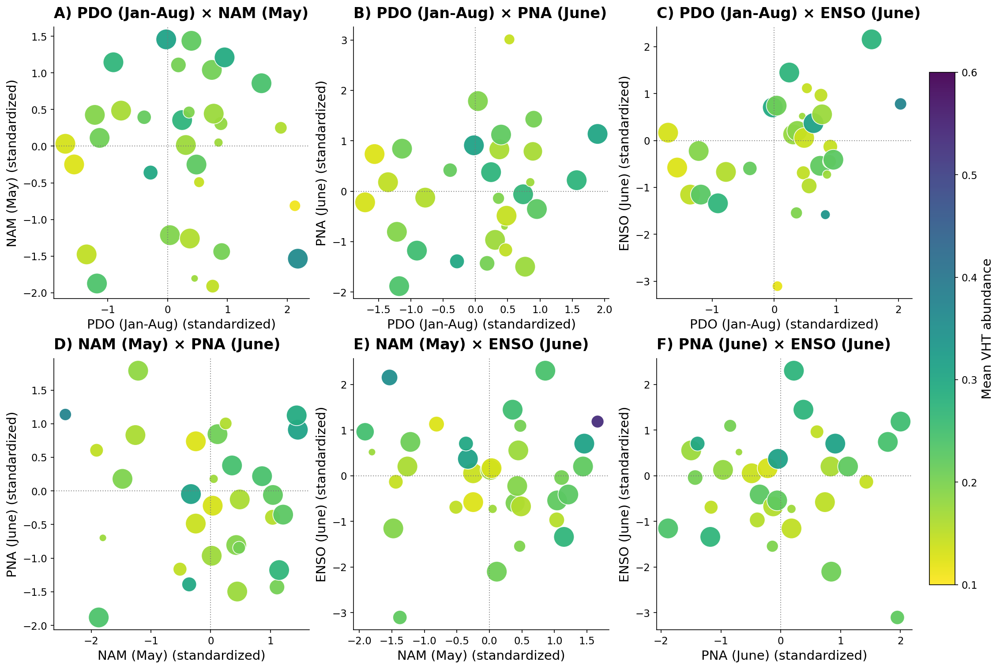

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# FIGURE 8 — 2D CLIMATE RESPONSE SURFACES
#
# Each panel:
#
# x = climate index 1
# y = climate index 2
# color = mean VHT
#
# Lakes are grouped into 2D climate bins.
# ============================================================

TARGET_COL = 'Norm_VHT'

PAIRS = [
    ('PDO_JA',    'PDO (Jan-Aug)',  'NAM_May',   'NAM (May)'),
    ('PDO_JA',    'PDO (Jan-Aug)',  'PNA_June',  'PNA (June)'),
    ('PDO_JA',    'PDO (Jan-Aug)',  'ENSO_June', 'ENSO (June)'),
    ('NAM_May',   'NAM (May)',      'PNA_June',  'PNA (June)'),
    ('NAM_May',   'NAM (May)',      'ENSO_June', 'ENSO (June)'),
    ('PNA_June',  'PNA (June)',     'ENSO_June', 'ENSO (June)')
]

# Shared color scale across all panels — set once so panels stay comparable.
VMIN, VMAX = 0.1, 0.6

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 10),
    constrained_layout=True
)

axes = axes.flatten()

all_summaries = []  # collected for a post-hoc range sanity check

for panel, (
    x_col,
    x_label,
    y_col,
    y_label
) in enumerate(PAIRS):

    ax = axes[panel]

    tmp = (
        df_scaled[
            [x_col, y_col, TARGET_COL]
        ]
        .dropna()
        .copy()
    )

    # --------------------------------------------------------
    # Create 8 × 8 climate bins
    # --------------------------------------------------------

    tmp['x_bin'] = pd.qcut(
        tmp[x_col],
        q=8,
        labels=False,
        duplicates='drop'
    )

    tmp['y_bin'] = pd.qcut(
        tmp[y_col],
        q=8,
        labels=False,
        duplicates='drop'
    )

    # --------------------------------------------------------
    # Calculate mean VHT within each climate bin
    # --------------------------------------------------------

    summary = (
        tmp.groupby(
            ['x_bin', 'y_bin']
        )
        .agg(
            mean_vht=(TARGET_COL, 'mean'),
            n=(TARGET_COL, 'count'),
            x=(x_col, 'median'),
            y=(y_col, 'median')
        )
        .reset_index()
    )

    # Only display bins containing enough lakes
    summary = summary[
        summary['n'] >= 3
    ]

    all_summaries.append(summary)

    # --------------------------------------------------------
    # Plot mean VHT
    # --------------------------------------------------------

    sc = ax.scatter(
        summary['x'],
        summary['y'],
        c=summary['mean_vht'],
        s=np.clip(
            summary['n'] * 8,
            30,
            500
        ),
        cmap='viridis_r',      # sequential — mean VHT is a magnitude, not a
                              # deviation from a meaningful midpoint, so a
                              # diverging cmap (e.g. BrBG) would mislead
        vmin=VMIN,
        vmax=VMAX,
        edgecolors='white',
        linewidth=0.8,
        alpha=0.95
    )

    # --------------------------------------------------------
    # Reference lines
    # --------------------------------------------------------

    ax.axvline(
        0,
        color='#777777',
        lw=1,
        ls=':',
        alpha=0.8
    )

    ax.axhline(
        0,
        color='#777777',
        lw=1,
        ls=':',
        alpha=0.8
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_xlabel(
        f'{x_label} (standardized)',
        fontsize=14
    )

    ax.set_ylabel(
        f'{y_label} (standardized)',
        fontsize=14
    )

    ax.set_title(
        f'{chr(65+panel)}) {x_label} × {y_label}',
        loc='left',
        fontsize=16,
        fontweight='bold',
        pad=10
    )

    ax.tick_params(
        labelsize=11
    )

    ax.spines[['top', 'right']].set_visible(False)


# ============================================================
# SANITY CHECK — make sure VMIN/VMAX actually cover the data
# ============================================================

full_summary = pd.concat(all_summaries, ignore_index=True)
data_min, data_max = full_summary['mean_vht'].min(), full_summary['mean_vht'].max()

if data_min < VMIN or data_max > VMAX:
    print(
        f'WARNING: mean_vht range in data is [{data_min:.3f}, {data_max:.3f}], '
        f'which falls outside the fixed color scale [{VMIN}, {VMAX}]. '
        f'Some bins will be clipped/saturated in the plot.'
    )


# ============================================================
# COLORBAR
# ============================================================

cbar = fig.colorbar(
    sc,
    ax=axes,
    shrink=0.85,
    pad=0.02
)

cbar.set_label(
    'Mean VHT abundance',
    fontsize=14
)

cbar.ax.tick_params(
    labelsize=11
)


# ============================================================
# SAVE
# ============================================================

#fig.savefig(
#    'Figure_VHT_2D_climate_response_surfaces.png',
#    dpi=300,
#    bbox_inches='tight'
#)

plt.show()
plt.close(fig)


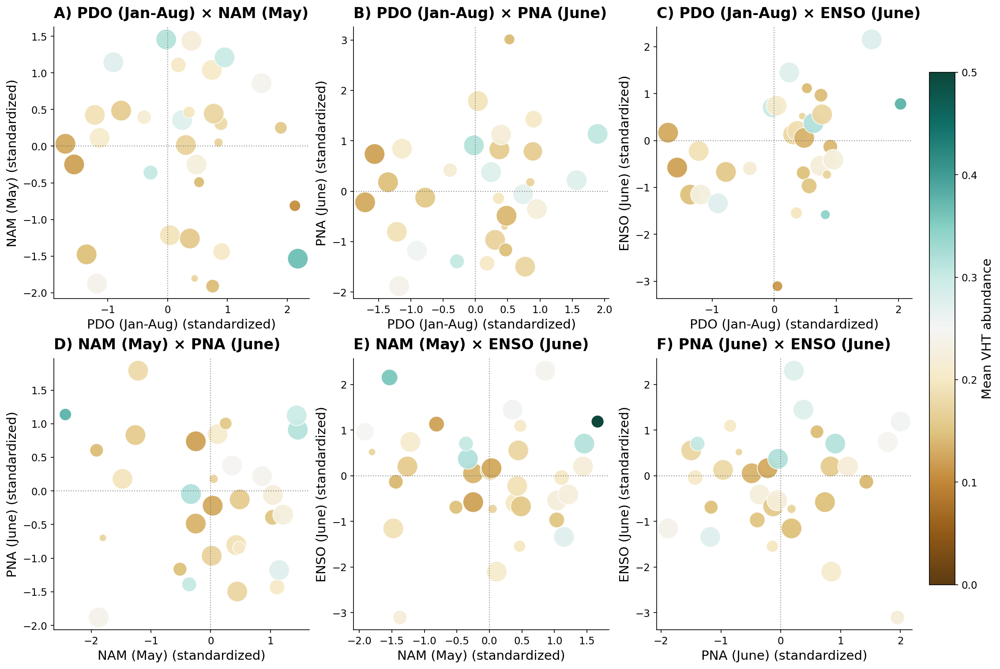

Saved: Figure_VHT_2D_climate_response_surfaces.png


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# FIGURE 8 — 2D CLIMATE RESPONSE SURFACES
#
# Each panel:
#
# x = climate index 1
# y = climate index 2
# color = mean VHT
#
# Lakes are grouped into 2D climate bins.
# ============================================================

TARGET_COL = 'Norm_VHT'

PAIRS = [
    ('PDO_JA',    'PDO (Jan-Aug)',  'NAM_May',   'NAM (May)'),
    ('PDO_JA',    'PDO (Jan-Aug)',  'PNA_June',  'PNA (June)'),
    ('PDO_JA',    'PDO (Jan-Aug)',  'ENSO_June', 'ENSO (June)'),
    ('NAM_May',   'NAM (May)',      'PNA_June',  'PNA (June)'),
    ('NAM_May',   'NAM (May)',      'ENSO_June', 'ENSO (June)'),
    ('PNA_June',  'PNA (June)',     'ENSO_June', 'ENSO (June)')
]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 10),
    constrained_layout=True
)

axes = axes.flatten()


for panel, (
    x_col,
    x_label,
    y_col,
    y_label
) in enumerate(PAIRS):

    ax = axes[panel]

    tmp = (
        df_scaled[
            [x_col, y_col, TARGET_COL]
        ]
        .dropna()
        .copy()
    )

    # --------------------------------------------------------
    # Create 8 × 8 climate bins
    # --------------------------------------------------------

    tmp['x_bin'] = pd.qcut(
        tmp[x_col],
        q=8,
        labels=False,
        duplicates='drop'
    )

    tmp['y_bin'] = pd.qcut(
        tmp[y_col],
        q=8,
        labels=False,
        duplicates='drop'
    )

    # --------------------------------------------------------
    # Calculate mean VHT within each climate bin
    # --------------------------------------------------------

    summary = (
        tmp.groupby(
            ['x_bin', 'y_bin']
        )
        .agg(
            mean_vht=(TARGET_COL, 'mean'),
            n=(TARGET_COL, 'count'),
            x=(x_col, 'median'),
            y=(y_col, 'median')
        )
        .reset_index()
    )

    # Only display bins containing enough lakes
    summary = summary[
        summary['n'] >= 3
    ]

    # --------------------------------------------------------
    # Plot mean VHT
    # --------------------------------------------------------

    sc = ax.scatter(
        summary['x'],
        summary['y'],
        c=summary['mean_vht'],
        s=np.clip(
            summary['n'] * 8,
            30,
            500
        ),
        cmap='BrBG',
        vmin=0,
        vmax=0.5,
        edgecolors='white',
        linewidth=0.8,
        alpha=0.95
    )

    # --------------------------------------------------------
    # Reference lines
    # --------------------------------------------------------

    ax.axvline(
        0,
        color='#777777',
        lw=1,
        ls=':',
        alpha=0.8
    )

    ax.axhline(
        0,
        color='#777777',
        lw=1,
        ls=':',
        alpha=0.8
    )

    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_xlabel(
        f'{x_label} (standardized)',
        fontsize=14
    )

    ax.set_ylabel(
        f'{y_label} (standardized)',
        fontsize=14
    )

    ax.set_title(
        f'{chr(65+panel)}) {x_label} × {y_label}',
        loc='left',
        fontsize=16,
        fontweight='bold',
        pad=10
    )

    ax.tick_params(
        labelsize=11
    )

    ax.spines[['top', 'right']].set_visible(False)


# ============================================================
# COLORBAR
# ============================================================

cbar = fig.colorbar(
    sc,
    ax=axes,
    shrink=0.85,
    pad=0.02
)

cbar.set_label(
    'Mean VHT abundance',
    fontsize=14
)

cbar.ax.tick_params(
    labelsize=11
)


# ============================================================
# SAVE
# ============================================================


plt.show()
plt.close(fig)

print(
    'Saved: Figure_VHT_2D_climate_response_surfaces.png'
)


### Long-term Trend Assessment

Test whether Norm_VHT is declining over time beyond what climate predictors
explain

In [69]:
# Test year trend in target ────────────────────────────────────────────────
formula_trend = f"{TARGET_COL} ~ year_std + " + " + ".join(sig_concurrent_final)
model_trend   = smf.mixedlm(formula_trend, data=df_nz,
                             groups=df_nz[LAKE_COL])
result_trend  = model_trend.fit(reml=True)
yr_coef = result_trend.fe_params.get('year_std', np.nan)
yr_p    = result_trend.pvalues.get('year_std', np.nan)
yr_se   = result_trend.bse_fe.get('year_std', np.nan)

yr_sd           = df_scaled[YEAR_COL].std()
yr_coef_peryear = yr_coef / yr_sd
n_years         = df[YEAR_COL].max() - df[YEAR_COL].min()
print(f'Long-term trend in {TARGET_COL}:')
print(f'  Year coefficient (std): {yr_coef:.5f}  SE={yr_se:.5f}  p={yr_p:.4f}')
print(f'  Change per year       : {yr_coef_peryear:.5f} units')
print(f'  Change over {n_years} years  : {yr_coef_peryear * n_years:.3f} units')
if yr_p < 0.05:
    direction = 'declining' if yr_coef < 0 else 'increasing'
    print(f'  → Significant {direction} trend (p={yr_p:.4f})')
    print(f'    Include year_std as covariate in final model')
else:
    print(f'  → No significant long-term trend (p={yr_p:.4f})')
    print(f'    Year covariate not required')

# Check whether key predictors are themselves trending ─────────────────────
print(f'\nTrend in top predictors over time:')
print(f'{"Predictor":<30s}  {"slope/yr":>10s}  {"r":>6s}  {"p":>8s}  {"trending?"}')
top_preds_check = sig_concurrent_final[:6] if len(sig_concurrent_final) >= 6 else sig_concurrent_final
for col in top_preds_check:
    if col not in df_scaled.columns:
        continue
    yr_means = df_scaled.groupby(YEAR_COL)[col].mean().dropna()
    if len(yr_means) < 5:
        continue
    slope, _, r, p, _ = stats.linregress(yr_means.index, yr_means.values)
    trending = 'YES' if p < 0.05 else 'no'
    print(f'{col:<30s}  {slope:>10.4f}  {r:>6.2f}  {p:>8.3f}  {trending}')

# Add year to final model if significant ───────────────────────────────────
INCLUDE_YEAR_TREND = yr_p < 0.05
if INCLUDE_YEAR_TREND:
    formula_final = f"{TARGET_COL} ~ year_std + " + " + ".join(sig_concurrent_final)
    model_final   = smf.mixedlm(formula_final, data=df_nz,
                                groups=df_nz[LAKE_COL])
    result_final  = model_final.fit(reml=True)
    r2_m, r2_c    = nakagawa_r2(result_final, TARGET_COL, df_nz)
    print(f'\nFinal model updated to include year_std covariate.')
    print(f'Marginal R²   : {r2_m:.3f}')
    print(f'Conditional R²: {r2_c:.3f}')

Long-term trend in Norm_VHT:
  Year coefficient (std): -0.00609  SE=0.00557  p=0.2741
  Change per year       : -0.00069 units
  Change over 39 years  : -0.027 units
  → No significant long-term trend (p=0.2741)
    Year covariate not required

Trend in top predictors over time:
Predictor                         slope/yr       r         p  trending?
wtemp_JA                            0.0135    0.25     0.124  no
tsr_june                           -0.0067   -0.08     0.613  no
PC1                                -0.0049   -0.05     0.767  no

Final model unchanged (no year covariate needed).


# Not included in publication -- model splits, no longer connected to current run

Compare the value of different information sets:  
- M1: Concurrent predictors only 
- M2: Concurrent + preseason predictors
- M3: Preseason predictors only

M1: Concurrent only: using 1771 rows after dropping NaNs
M2: +Preseason: using 1771 rows after dropping NaNs
M3: Preseason only: using 1771 rows after dropping NaNs

  MODEL COMPARISON — Concurrent vs Preseason vs Combined
              label  n_preds    AIC  ΔAIC  marginal_r2  conditional_r2  LR_p
           M0: Null        0 -332.3   0.0        0.000           0.664   1.0
M1: Concurrent only        7 -472.0 139.7        0.418           0.806   0.0
     M2: +Preseason       21 -479.2 146.9        0.425           0.806   0.0
 M3: Preseason only       14 -371.2  38.9        0.403           0.796   0.0


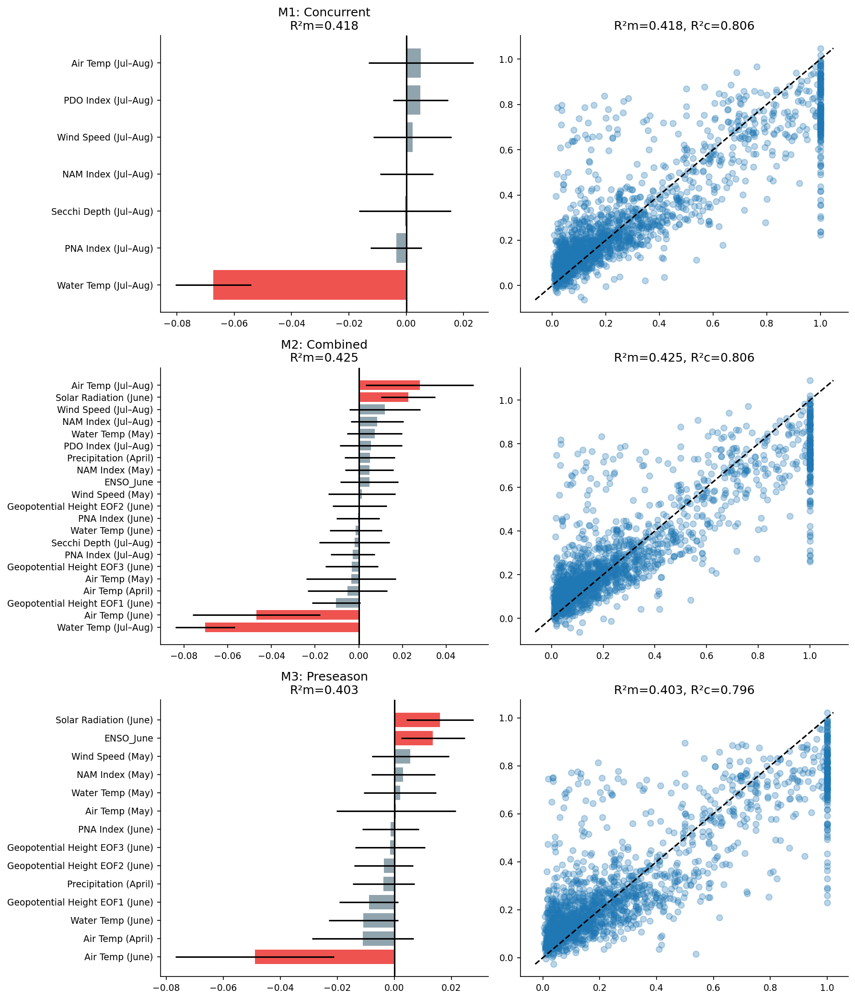

In [43]:
# Null model ─────────────────────────────────────────────
null_res = smf.mixedlm(f"{TARGET_COL} ~ 1", data=df_nz,
                       groups=df_nz[LAKE_COL]).fit(reml=False)

comp_results = [{
    'label': 'M0: Null',
    'n_preds': 0,
    'AIC': null_res.aic,
    'loglik': null_res.llf,
    'marginal_r2': 0.0,
    'conditional_r2': icc_lmm
}]

# predictors
conc_avail = [c for c in sig_concurrent if c in df_nz.columns]
pres_avail = [c for c in sig_preds if c in df_nz.columns]

# Fit models once ────────────────────────────────────────
r_m1 = fit_compare(conc_avail, df_nz, TARGET_COL, LAKE_COL, 'M1: Concurrent only')
r_m2 = fit_compare(conc_avail + pres_avail, df_nz, TARGET_COL, LAKE_COL, 'M2: +Preseason')
r_m3 = fit_compare(pres_avail, df_nz, TARGET_COL, LAKE_COL, 'M3: Preseason only')

for r in [r_m1, r_m2, r_m3]:
    if r:
        comp_results.append(r)

# Comparison table ───────────────────────────────────────
comp_df = pd.DataFrame(comp_results)

# remove accidental duplicates (important fix)
comp_df = comp_df.drop_duplicates(subset=['label'], keep='last')

comp_df['ΔAIC'] = null_res.aic - comp_df['AIC']

comp_df['LR_p'] = comp_df.apply(
    lambda row: stats.chi2.sf(
        2 * (row['loglik'] - null_res.llf),
        df=row['n_preds']
    ) if row['n_preds'] > 0 else 1.0,
    axis=1
)

model_order = [
    'M0: Null',
    'M1: Concurrent only',
    'M2: +Preseason',
    'M3: Preseason only'
]

comp_df['label'] = pd.Categorical(comp_df['label'],
                                  categories=model_order,
                                  ordered=True)

comp_df = comp_df.sort_values('label')

print('\n' + '=' * 65)
print('  MODEL COMPARISON — Concurrent vs Preseason vs Combined')
print('=' * 65)

print(comp_df[['label', 'n_preds', 'AIC', 'ΔAIC',
               'marginal_r2', 'conditional_r2', 'LR_p']]
      .round({
          'AIC': 1,
          'ΔAIC': 1,
          'marginal_r2': 3,
          'conditional_r2': 3,
          'LR_p': 4
      })
      .to_string(index=False))

# Extract models safely ──────────────────────────────────
result_m1 = r_m1['model'] if r_m1 else None
result_m2 = r_m2['model'] if r_m2 else None
result_m3 = r_m3['model'] if r_m3 else None

r1m = r_m1['r2m'] if r_m1 else None
r1c = r_m1['r2c'] if r_m1 else None

r2m_m2 = r_m2['r2m'] if r_m2 else None
r2c_m2 = r_m2['r2c'] if r_m2 else None

r2m_m3 = r_m3['r2m'] if r_m3 else None
r2c_m3 = r_m3['r2c'] if r_m3 else None


# plotting function ────────────────────────────────
def plot_model_panels(result, r1m, r1c, model_label,
                      ax_forest, ax_scatter, df,
                      panel_letters=('a', 'b')):

    if result is None:
        ax_forest.set_title(f"{model_label} (failed)")
        ax_scatter.set_visible(False)
        return

    fe = pd.DataFrame({
        'coef': result.fe_params,
        'p': result.pvalues,
        'ci_low': result.conf_int().iloc[:, 0],
        'ci_high': result.conf_int().iloc[:, 1],
    }).drop(index=['Intercept', 'Group Var', 'year_std'], errors='ignore')

    fe = fe.sort_values('coef')

    y = np.arange(len(fe))
    colors = ['#EF5350' if p < 0.05 else '#90A4AE' for p in fe['p']]

    ax_forest.barh(y, fe['coef'], color=colors)
    ax_forest.errorbar(fe['coef'], y,
                       xerr=[fe['coef'] - fe['ci_low'],
                             fe['ci_high'] - fe['coef']],
                       fmt='none', color='black')

    ax_forest.axvline(0, color='black')
    ax_forest.set_yticks(y)
    ax_forest.set_yticklabels([pretty(p) for p in fe.index], fontsize=9)

    ax_forest.set_title(f"{model_label}\nR²m={r1m:.3f}")

    # observed vs fitted
    fitted = result.fittedvalues
    observed = df[TARGET_COL].loc[result.fittedvalues.index]

    ax_scatter.scatter(observed, fitted, alpha=0.3)
    lims = [min(observed.min(), fitted.min()),
            max(observed.max(), fitted.max())]

    ax_scatter.plot(lims, lims, 'k--')
    ax_scatter.set_title(f"R²m={r1m:.3f}, R²c={r1c:.3f}")


# Plot ───────────────────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(12, 14))

# Get the model-specific dataframes
df_m1 = df_nz[[TARGET_COL] + conc_avail + [LAKE_COL]].dropna()
df_m2 = df_nz[[TARGET_COL] + conc_avail + pres_avail + [LAKE_COL]].dropna()
df_m3 = df_nz[[TARGET_COL] + pres_avail + [LAKE_COL]].dropna()

# Then plot with correct df:
plot_model_panels(result_m1, r1m,    r1c,    'M1: Concurrent',
                  axes[0,0], axes[0,1], df_m1)

plot_model_panels(result_m2, r2m_m2, r2c_m2, 'M2: Combined',
                  axes[1,0], axes[1,1], df_m2)

plot_model_panels(result_m3, r2m_m3, r2c_m3, 'M3: Preseason',
                  axes[2,0], axes[2,1], df_m3)

plt.tight_layout()
plt.savefig('ModelComparisonPlots', dpi=150, bbox_inches='tight')
plt.show()


Columns added: ['lagoslakeid', 'hydro_category', 'geo_position', 'TSI', 'log_lake_area']
NaNs in hydro_category: 0
M1: Concurrent only: using 1771 rows after dropping NaNs
M2: +Preseason: using 1771 rows after dropping NaNs
M3: Preseason only: using 1771 rows after dropping NaNs

  MODEL COMPARISON — Concurrent vs Preseason vs Combined
              label  n_preds    AIC  ΔAIC  marginal_r2  conditional_r2  LR_p
           M0: Null        0 -332.3   0.0        0.000           0.664   1.0
M1: Concurrent only       11 -496.7 164.4        0.434           0.799   0.0
     M2: +Preseason       25 -503.7 171.4        0.442           0.800   0.0
 M3: Preseason only       18 -394.5  62.2        0.419           0.788   0.0


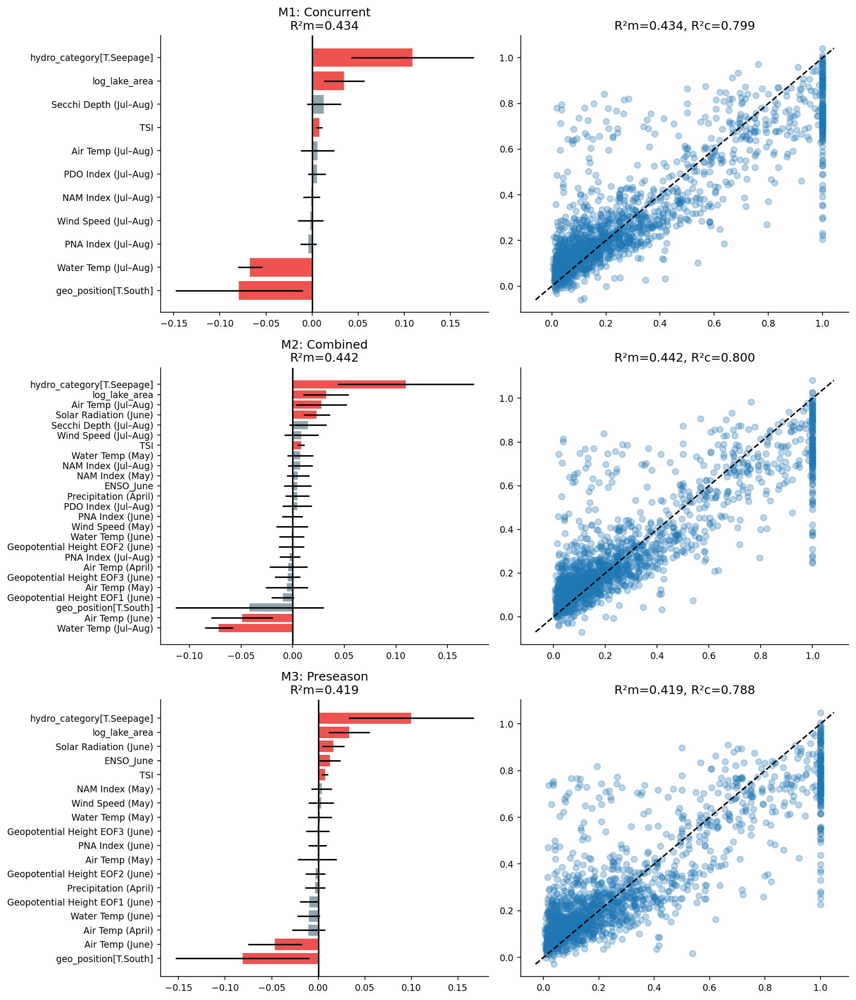

In [47]:
## TRY ADDING IN MORE FIXED EFFECTS USING LAKE CATEGORIES

# Merge lake characteristics into df_nz ──────────────────
lake_chars_sub = lake_chars[['lagoslakeid', 'hydro_category',
                              'geo_position', 'lake_area_ha', 'TSI']].copy()
lake_chars_sub['log_lake_area'] = np.log(lake_chars_sub['lake_area_ha'])
lake_chars_sub = lake_chars_sub.drop(columns='lake_area_ha')

# Drop any leftover columns from a previous failed run
for col in ['hydro_category', 'geo_position', 'log_lake_area', 'TSI']:
    if col in df_nz.columns:
        df_nz = df_nz.drop(columns=col)

# Use `on=` since both sides share the same column name
df_nz = df_nz.merge(lake_chars_sub, on='lagoslakeid', how='left')

# Verify
print(f"Columns added: {[c for c in lake_chars_sub.columns if c in df_nz.columns]}")
print(f"NaNs in hydro_category: {df_nz['hydro_category'].isna().sum()}")

# Encode categoricals
df_nz['hydro_category'] = pd.Categorical(df_nz['hydro_category'])
df_nz['geo_position']   = pd.Categorical(df_nz['geo_position'])

lake_char_preds = ['hydro_category', 'geo_position', 'log_lake_area', 'TSI']

# Null model ─────────────────────────────────────────────
null_res = smf.mixedlm(f"{TARGET_COL} ~ 1", data=df_nz,
                       groups=df_nz[LAKE_COL]).fit(reml=False)
comp_results = [{
    'label': 'M0: Null',
    'n_preds': 0,
    'AIC': null_res.aic,
    'loglik': null_res.llf,
    'marginal_r2': 0.0,
    'conditional_r2': icc_lmm
}]

# predictors
conc_avail = [c for c in sig_concurrent if c in df_nz.columns]
pres_avail = [c for c in sig_preds if c in df_nz.columns]

# Fit models once ────────────────────────────────────────
r_m1 = fit_compare(conc_avail + lake_char_preds, df_nz, TARGET_COL, LAKE_COL, 'M1: Concurrent only')
r_m2 = fit_compare(conc_avail + pres_avail + lake_char_preds, df_nz, TARGET_COL, LAKE_COL, 'M2: +Preseason')
r_m3 = fit_compare(pres_avail + lake_char_preds, df_nz, TARGET_COL, LAKE_COL, 'M3: Preseason only')

for r in [r_m1, r_m2, r_m3]:
    if r:
        comp_results.append(r)

# Comparison table ───────────────────────────────────────
comp_df = pd.DataFrame(comp_results)
comp_df = comp_df.drop_duplicates(subset=['label'], keep='last')
comp_df['ΔAIC'] = null_res.aic - comp_df['AIC']
comp_df['LR_p'] = comp_df.apply(
    lambda row: stats.chi2.sf(
        2 * (row['loglik'] - null_res.llf),
        df=row['n_preds']
    ) if row['n_preds'] > 0 else 1.0,
    axis=1
)
model_order = [
    'M0: Null',
    'M1: Concurrent only',
    'M2: +Preseason',
    'M3: Preseason only'
]
comp_df['label'] = pd.Categorical(comp_df['label'],
                                  categories=model_order,
                                  ordered=True)
comp_df = comp_df.sort_values('label')
print('\n' + '=' * 65)
print('  MODEL COMPARISON — Concurrent vs Preseason vs Combined')
print('=' * 65)
print(comp_df[['label', 'n_preds', 'AIC', 'ΔAIC',
               'marginal_r2', 'conditional_r2', 'LR_p']]
      .round({
          'AIC': 1,
          'ΔAIC': 1,
          'marginal_r2': 3,
          'conditional_r2': 3,
          'LR_p': 4
      })
      .to_string(index=False))

# Extract models safely ──────────────────────────────────
result_m1 = r_m1['model'] if r_m1 else None
result_m2 = r_m2['model'] if r_m2 else None
result_m3 = r_m3['model'] if r_m3 else None
r1m = r_m1['r2m'] if r_m1 else None
r1c = r_m1['r2c'] if r_m1 else None
r2m_m2 = r_m2['r2m'] if r_m2 else None
r2c_m2 = r_m2['r2c'] if r_m2 else None
r2m_m3 = r_m3['r2m'] if r_m3 else None
r2c_m3 = r_m3['r2c'] if r_m3 else None

# plotting function ────────────────────────────────
def plot_model_panels(result, r1m, r1c, model_label,
                      ax_forest, ax_scatter, df,
                      panel_letters=('a', 'b')):
    if result is None:
        ax_forest.set_title(f"{model_label} (failed)")
        ax_scatter.set_visible(False)
        return
    fe = pd.DataFrame({
        'coef': result.fe_params,
        'p': result.pvalues,
        'ci_low': result.conf_int().iloc[:, 0],
        'ci_high': result.conf_int().iloc[:, 1],
    }).drop(index=['Intercept', 'Group Var', 'year_std'], errors='ignore')
    fe = fe.sort_values('coef')
    y = np.arange(len(fe))
    colors = ['#EF5350' if p < 0.05 else '#90A4AE' for p in fe['p']]
    ax_forest.barh(y, fe['coef'], color=colors)
    ax_forest.errorbar(fe['coef'], y,
                       xerr=[fe['coef'] - fe['ci_low'],
                             fe['ci_high'] - fe['coef']],
                       fmt='none', color='black')
    ax_forest.axvline(0, color='black')
    ax_forest.set_yticks(y)
    ax_forest.set_yticklabels([pretty(p) for p in fe.index], fontsize=9)
    ax_forest.set_title(f"{model_label}\nR²m={r1m:.3f}")
    fitted = result.fittedvalues
    observed = df[TARGET_COL].loc[result.fittedvalues.index]
    ax_scatter.scatter(observed, fitted, alpha=0.3)
    lims = [min(observed.min(), fitted.min()),
            max(observed.max(), fitted.max())]
    ax_scatter.plot(lims, lims, 'k--')
    ax_scatter.set_title(f"R²m={r1m:.3f}, R²c={r1c:.3f}")

# Plot ───────────────────────────────────────────────────
fig, axes = plt.subplots(3, 2, figsize=(12, 14))
all_preds = conc_avail + pres_avail + lake_char_preds
df_m1 = df_nz[[TARGET_COL] + conc_avail + lake_char_preds + [LAKE_COL]].dropna()
df_m2 = df_nz[[TARGET_COL] + conc_avail + pres_avail + lake_char_preds + [LAKE_COL]].dropna()
df_m3 = df_nz[[TARGET_COL] + pres_avail + lake_char_preds + [LAKE_COL]].dropna()

plot_model_panels(result_m1, r1m,    r1c,    'M1: Concurrent',
                  axes[0,0], axes[0,1], df_m1)
plot_model_panels(result_m2, r2m_m2, r2c_m2, 'M2: Combined',
                  axes[1,0], axes[1,1], df_m2)
plot_model_panels(result_m3, r2m_m3, r2c_m3, 'M3: Preseason',
                  axes[2,0], axes[2,1], df_m3)

plt.tight_layout()
plt.savefig('ModelComparisonPlots', dpi=150, bbox_inches='tight')
plt.show()

In [48]:
# ── Build screened preseason groups ──────────────────────────────────────────
PRESEASON_GROUPS_SCREENED = {
    'Large-scale climate': [c for c in [
        'NAM_May', 'NAM_June', 'PNA_May', 'PNA_June',
        'ENSO_May', 'PDO_May', 'PDO_June', 'June_hgt', 'May_hgt',
        'AO_June', 'AO_May', 'ENSO_June', 'tsr_may', 'tsr_june',
        'ttr_may', 'ttr_june', 'PC1', 'PC2', 'PC3',
    ] if c in sig_preds and c in df_nz.columns],
    'Local climate': [c for c in [
        'temp_c_April', 'temp_c_May', 'temp_c_June',
        'precip_mm_April', 'precip_mm_May', 'precip_mm_June',
        'windspeed_may', 'windspeed_june',
    ] if c in sig_preds and c in df_nz.columns],
    'In-lake conditions': [c for c in [
        'wtemp_may', 'wtemp_june',
        'chla_may', 'chla_june', 'tp_may', 'secchi_may', 'secchi_june', 'ice_out_doy',
    ] if c in sig_preds and c in df_nz.columns],
}
PRESEASON_GROUPS_SCREENED = {k: v for k, v in PRESEASON_GROUPS_SCREENED.items() if v}

# Update PREDICTOR_GROUPS to use screened predictors only ──────────────────
CONCURRENT_GROUP_SCREENED = {
    'Concurrent (JA)': [c for c in sig_concurrent if c in df_nz.columns]
}

if MODEL_MODE == 'concurrent':
    PREDICTOR_GROUPS = CONCURRENT_GROUP_SCREENED
elif MODEL_MODE == 'concurrent+preseason':
    PREDICTOR_GROUPS = {**CONCURRENT_GROUP_SCREENED, **PRESEASON_GROUPS_SCREENED}
elif MODEL_MODE == 'preseason+concurrent':
    PREDICTOR_GROUPS = {**PRESEASON_GROUPS_SCREENED, **CONCURRENT_GROUP_SCREENED}

PREDICTOR_GROUPS = {k: v for k, v in PREDICTOR_GROUPS.items() if v}
print('Predictor groups for variance partitioning:')
for grp, cols in PREDICTOR_GROUPS.items():
    print(f'  {grp:<25s}: {len(cols)} predictors')

Predictor groups for variance partitioning:
  Concurrent (JA)          : 7 predictors
  Large-scale climate      : 7 predictors
  Local climate            : 4 predictors
  In-lake conditions       : 2 predictors


In [49]:
# Variance partitioning by predictor group ─────────────────────────────────
print('Variance partitioning — unique contribution of each predictor group')
print('(unique = R²(all) - R²(all without this group))\n')

all_group_preds = [c for grp in PREDICTOR_GROUPS.values() for c in grp
                   if c in df_nz.columns]

# R² with all predictors
r_all  = fit_compare(all_group_preds, df_nz, TARGET_COL, LAKE_COL, 'All')
r2_all = r_all['marginal_r2'] if r_all else np.nan

vp_rows = []
for grp_name, grp_cols in PREDICTOR_GROUPS.items():
    avail = [c for c in grp_cols if c in df_nz.columns]
    if not avail:
        continue
    # R² without this group
    others = [c for g, cs in PREDICTOR_GROUPS.items()
              for c in cs if g != grp_name and c in df_nz.columns]
    r_without  = fit_compare(others, df_nz, TARGET_COL, LAKE_COL, f'no {grp_name}')
    r2_without = r_without['marginal_r2'] if r_without else np.nan

    # R² with only this group
    r_only  = fit_compare(avail, df_nz, TARGET_COL, LAKE_COL, grp_name)
    r2_only = r_only['marginal_r2'] if r_only else np.nan

    unique_r2 = r2_all - r2_without
    shared_r2 = r2_only - unique_r2

    vp_rows.append({'Group': grp_name, 'Alone R²': r2_only,
                    'Unique R²': unique_r2, 'Shared R²': shared_r2})
    print(f'{grp_name:<25s}  alone={r2_only:.3f}  '
          f'unique={unique_r2:.3f}  shared={shared_r2:.3f}')

vp_df = pd.DataFrame(vp_rows)
print(f'\nTotal R² (all groups): {r2_all:.3f}')

Variance partitioning — unique contribution of each predictor group
(unique = R²(all) - R²(all without this group))

All: using 1771 rows after dropping NaNs
no Concurrent (JA): using 1771 rows after dropping NaNs
Concurrent (JA): using 1771 rows after dropping NaNs
Concurrent (JA)            alone=0.418  unique=0.023  shared=0.395
no Large-scale climate: using 1771 rows after dropping NaNs
Large-scale climate: using 1771 rows after dropping NaNs
Large-scale climate        alone=0.393  unique=0.004  shared=0.389
no Local climate: using 1771 rows after dropping NaNs
Local climate: using 1771 rows after dropping NaNs
Local climate              alone=0.399  unique=0.004  shared=0.395
no In-lake conditions: using 1771 rows after dropping NaNs
In-lake conditions: using 1771 rows after dropping NaNs
In-lake conditions         alone=0.392  unique=-0.000  shared=0.393

Total R² (all groups): 0.425


## Climate vs. inlake model runs

In [51]:
all_20 = ['secchi_JA', 'wtemp_JA', 'PDO_JA', 'PNA_JA', 'NAM_JA',
          'temp_c_JA', 'windspeed_ja', 'NAM_May', 'PNA_June',
          'ENSO_June', 'tsr_june', 'temp_c_April', 'temp_c_May',
          'temp_c_June', 'PC1', 'PC2', 'PC3', 'precip_m_April',
          'windspeed_may', 'wtemp_may', 'wtemp_june']

# Columns to add back
missing_preds = [c for c in all_20 if c not in df_nz.columns]
print(f'Adding back: {missing_preds}')

# Merge from df_raw on lake-year key
df_nz = df_nz.merge(
    df_raw[['lagoslakeid', 'year'] + missing_preds],
    on=['lagoslakeid', 'year'],
    how='left'
)

# Standardize the new columns to match existing predictors
for col in missing_preds:
    mean = df_nz[col].mean()
    std  = df_nz[col].std()
    if std > 0:
        df_nz[col] = (df_nz[col] - mean) / std
        print(f'Standardized {col}: mean={mean:.3f}, std={std:.3f}')

# Verify
still_missing = [c for c in all_20 if c not in df_nz.columns]
print(f'\nStill missing: {still_missing}')
print(f'df_nz shape after merge: {df_nz.shape}')

Adding back: []

Still missing: []
df_nz shape after merge: (1771, 36)


In [52]:
PREDICTOR_GROUPS_2x2 = {
    'Climate — Concurrent': [c for c in [
        'PDO_JA', 'ENSO_JA', 'tsr_ja', 'windspeed_ja', 'temp_c_JA', 'PC1', 'PC2', 'PC3',
    ] if c in df_nz.columns],

    'Climate — Preseason': [c for c in [
        'ENSO_May', 'ENSO_June',
        'temp_c_April', 'temp_c_May', 'temp_c_June',
        'precip_mm_April', 'precip_mm_May',
    ] if c in df_nz.columns],

    'In-lake — Concurrent': [c for c in [
        'wtemp_JA', 'chla_JA', 'secchi_JA',
    ] if c in df_nz.columns],

    'In-lake — Preseason': [c for c in [
        'wtemp_june', 'chla_may', 'chla_june',
        'secchi_june', 'ice_off_doy',
    ] if c in df_nz.columns],
}
PREDICTOR_GROUPS_2x2 = {k: v for k, v in PREDICTOR_GROUPS_2x2.items() if v}

print('Expanded 2x2 Predictor groups:')
total = 0
for grp, cols in PREDICTOR_GROUPS_2x2.items():
    print(f'  {grp:<30s}: {len(cols)} — {cols}')
    total += len(cols)
print(f'\nTotal predictors across groups: {total}')

Expanded 2x2 Predictor groups:
  Climate — Concurrent          : 6 — ['PDO_JA', 'windspeed_ja', 'temp_c_JA', 'PC1', 'PC2', 'PC3']
  Climate — Preseason           : 4 — ['ENSO_June', 'temp_c_April', 'temp_c_May', 'temp_c_June']
  In-lake — Concurrent          : 2 — ['wtemp_JA', 'secchi_JA']
  In-lake — Preseason           : 1 — ['wtemp_june']

Total predictors across groups: 13


In [53]:
null_res_2x2 = smf.mixedlm(f"{TARGET_COL} ~ 1", data=df_nz,
                             groups=df_nz[LAKE_COL]).fit(reml=False)

model_specs = {
    'M: Climate — Concurrent'  : PREDICTOR_GROUPS_2x2['Climate — Concurrent'],
    'M: Climate — Preseason'   : PREDICTOR_GROUPS_2x2['Climate — Preseason'],
    'M: In-lake — Concurrent'  : PREDICTOR_GROUPS_2x2['In-lake — Concurrent'],
    'M: In-lake — Preseason'   : PREDICTOR_GROUPS_2x2['In-lake — Preseason'],
    'M: All Climate'           : PREDICTOR_GROUPS_2x2['Climate — Concurrent'] + 
                                 PREDICTOR_GROUPS_2x2['Climate — Preseason'],
    'M: All In-lake'           : PREDICTOR_GROUPS_2x2['In-lake — Concurrent'] + 
                                 PREDICTOR_GROUPS_2x2['In-lake — Preseason'],
    'M: All Concurrent'        : PREDICTOR_GROUPS_2x2['Climate — Concurrent'] + 
                                 PREDICTOR_GROUPS_2x2['In-lake — Concurrent'],
    'M: All Preseason'         : PREDICTOR_GROUPS_2x2['Climate — Preseason'] + 
                                 PREDICTOR_GROUPS_2x2['In-lake — Preseason'],
    'M: Full (all 15)'         : [c for cols in PREDICTOR_GROUPS_2x2.values() 
                                   for c in cols],
}

results_2x2 = {}
comp_rows   = []

for label, preds in model_specs.items():
    r = fit_compare(preds, df_nz, TARGET_COL, LAKE_COL, label)
    if r:
        results_2x2[label] = r
        comp_rows.append(r)

comp_2x2 = pd.DataFrame(comp_rows)
comp_2x2['ΔAIC'] = null_res_2x2.aic - comp_2x2['AIC']
comp_2x2['LR_p'] = comp_2x2.apply(
    lambda row: stats.chi2.sf(
        2 * (row['loglik'] - null_res_2x2.llf),
        df=row['n_preds']
    ) if row['n_preds'] > 0 else 1.0, axis=1)

print('\n' + '=' * 70)
print('  2x2 MODEL COMPARISON — Climate/In-lake × Concurrent/Preseason')
print('=' * 70)
print(comp_2x2[['label', 'n_preds', 'AIC', 'ΔAIC',
                'marginal_r2', 'conditional_r2', 'LR_p']]
      .round({'AIC':1, 'ΔAIC':1, 'marginal_r2':3,
              'conditional_r2':3, 'LR_p':4})
      .to_string(index=False))

M: Climate — Concurrent: using 1771 rows after dropping NaNs
M: Climate — Preseason: using 1771 rows after dropping NaNs
M: In-lake — Concurrent: using 1771 rows after dropping NaNs
M: In-lake — Preseason: using 1771 rows after dropping NaNs
M: All Climate: using 1771 rows after dropping NaNs
M: All In-lake: using 1771 rows after dropping NaNs
M: All Concurrent: using 1771 rows after dropping NaNs
M: All Preseason: using 1771 rows after dropping NaNs
M: Full (all 15): using 1771 rows after dropping NaNs

  2x2 MODEL COMPARISON — Climate/In-lake × Concurrent/Preseason
                  label  n_preds    AIC  ΔAIC  marginal_r2  conditional_r2   LR_p
M: Climate — Concurrent        6 -385.0  52.7        0.404           0.795 0.0000
 M: Climate — Preseason        4 -369.7  37.4        0.400           0.794 0.0000
M: In-lake — Concurrent        2 -480.3 148.0        0.418           0.807 0.0000
 M: In-lake — Preseason        1 -342.3  10.0        0.393           0.792 0.0005
         M: All 

In [54]:
ALPHA = 0.05

target_models = {
    'M: Climate — Concurrent': model_specs['M: Climate — Concurrent'],
    'M: Climate — Preseason': model_specs['M: Climate — Preseason'],
    'M: In-lake — Concurrent': model_specs['M: In-lake — Concurrent'],
    'M: In-lake — Preseason': model_specs['M: In-lake — Preseason'],
}

rows = []

print('\n' + '=' * 70)
print('  SIGNIFICANT PREDICTORS (SELECTED 4 MODELS)')
print('=' * 70)

for label, preds in target_models.items():
    
    # Clean + aligned data
    cols_needed = [TARGET_COL] + preds + [LAKE_COL]
    df_model = df_nz[cols_needed].dropna().reset_index(drop=True)
    
    formula = f"{TARGET_COL} ~ " + " + ".join(preds)
    
    model = smf.mixedlm(
        formula,
        data=df_model,
        groups=df_model[LAKE_COL].values
    ).fit(reml=False)
    
    # Extract significant predictors
    pvals = (
        model.pvalues
        .drop(labels=['Intercept'], errors='ignore')
        .drop(labels=['Group Var'], errors='ignore')
    )
    
    sig = pvals[pvals < ALPHA].sort_values()
    
    print(f"\n{label}  (n_sig={len(sig)} / {len(preds)})")
    
    if sig.empty:
        print("  — none —")
    else:
        for pred, p in sig.items():
            coef = model.params[pred]
            print(f"  {pred:<35}  coef={coef:+.4f}  p={p:.4f}")
            
            rows.append({
                'model': label,
                'predictor': pred,
                'coef': coef,
                'p_value': p
            })

# Tidy table
sig_df = pd.DataFrame(rows).sort_values(['model', 'p_value'])

print('\n' + '=' * 70)
print('  TIDY TABLE')
print('=' * 70)
print(sig_df.to_string(index=False))


  SIGNIFICANT PREDICTORS (SELECTED 4 MODELS)

M: Climate — Concurrent  (n_sig=2 / 6)
  temp_c_JA                            coef=-0.0352  p=0.0001
  PC1                                  coef=-0.0106  p=0.0235

M: Climate — Preseason  (n_sig=2 / 4)
  temp_c_June                          coef=-0.0457  p=0.0000
  ENSO_June                            coef=+0.0172  p=0.0003

M: In-lake — Concurrent  (n_sig=1 / 2)
  wtemp_JA                             coef=-0.0666  p=0.0000

M: In-lake — Preseason  (n_sig=1 / 1)
  wtemp_june                           coef=-0.0184  p=0.0005

  TIDY TABLE
                  model   predictor      coef      p_value
M: Climate — Concurrent   temp_c_JA -0.035175 1.487099e-04
M: Climate — Concurrent         PC1 -0.010642 2.349855e-02
 M: Climate — Preseason temp_c_June -0.045748 1.210946e-07
 M: Climate — Preseason   ENSO_June  0.017241 2.662841e-04
M: In-lake — Concurrent    wtemp_JA -0.066612 2.199951e-36
 M: In-lake — Preseason  wtemp_june -0.018418 5.196552e-

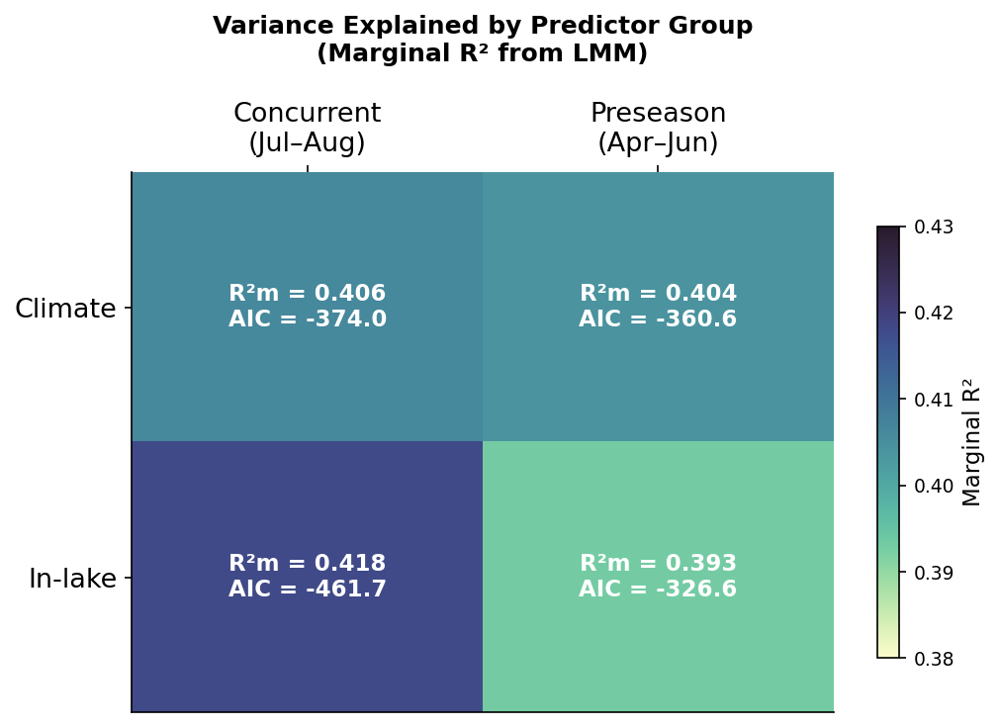

In [55]:
#MARGINAL R2

# ── Data for heatmap ──────────────────────────────────────────────────────────
r2_matrix = np.array([
    [0.406, 0.404],   # Climate:  Concurrent, Preseason
    [0.418, 0.393],   # In-lake:  Concurrent, Preseason
])

aic_matrix = np.array([
    [-374.0, -360.6],
    [-461.7, -326.6],
])

fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(r2_matrix, cmap='cmo.deep', aspect='auto',
               vmin=0.38, vmax=0.43)

# Axis labels
ax.set_xticks([0, 1])
ax.set_xticklabels(['Concurrent\n(Jul–Aug)', 'Preseason\n(Apr–Jun)'], fontsize=13)
ax.set_yticks([0, 1])
ax.set_yticklabels(['Climate', 'In-lake'], fontsize=13)
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()

# Annotate each cell with R² and AIC
for i in range(2):
    for j in range(2):
        ax.text(j, i,
                f'R²m = {r2_matrix[i,j]:.3f}\nAIC = {aic_matrix[i,j]:.1f}',
                ha='center', va='center', fontsize=11, fontweight='bold',
                color='white')

# Colorbar
cb = plt.colorbar(im, ax=ax, shrink=0.8)
cb.set_label('Marginal R²', fontsize=11)

ax.set_title('Variance Explained by Predictor Group\n(Marginal R² from LMM)',
             fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('2x2_heatmap.png', bbox_inches='tight', dpi=180)
plt.show()

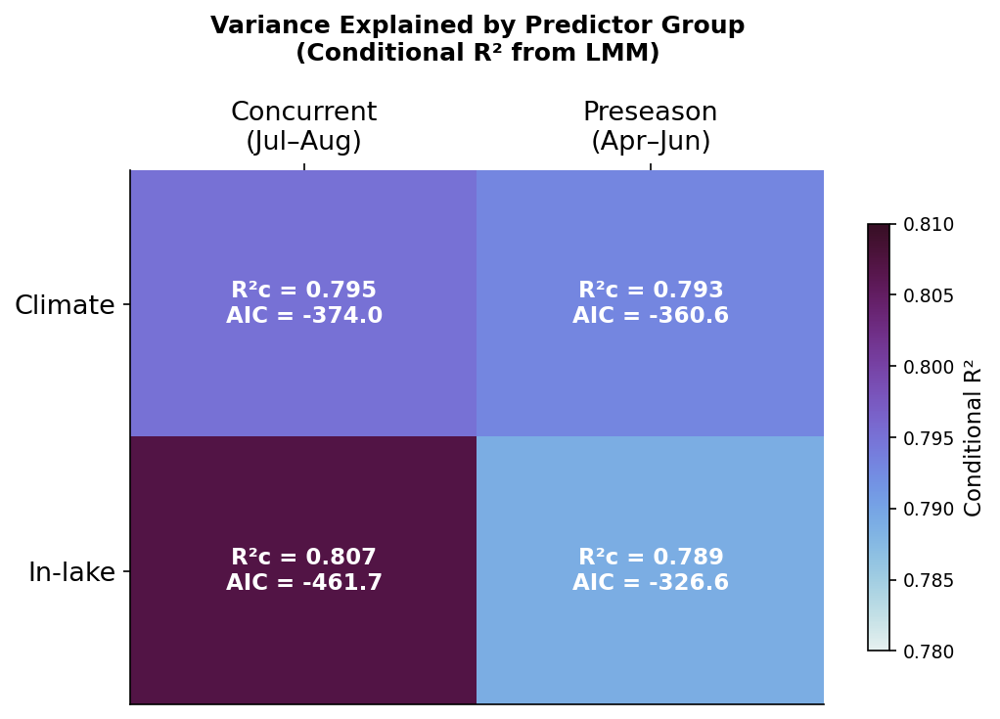

In [56]:
#CONDITIONAL R2


# ── Data for heatmap ──────────────────────────────────────────────────────────

r2_matrix = np.array([ 
    [0.795, 0.793],
    [0.807, 0.789],
])

aic_matrix = np.array([
    [-374.0, -360.6],
    [-461.7, -326.6],
])

fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(r2_matrix, cmap='cmo.dense', aspect='auto',
               vmin=0.78, vmax=0.81)

# Axis labels
ax.set_xticks([0, 1])
ax.set_xticklabels(['Concurrent\n(Jul–Aug)', 'Preseason\n(Apr–Jun)'], fontsize=13)
ax.set_yticks([0, 1])
ax.set_yticklabels(['Climate', 'In-lake'], fontsize=13)
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()

# Annotate each cell with R² and AIC
for i in range(2):
    for j in range(2):
        ax.text(j, i,
                f'R²c = {r2_matrix[i,j]:.3f}\nAIC = {aic_matrix[i,j]:.1f}',
                ha='center', va='center', fontsize=11, fontweight='bold',
                color='white' if r2_matrix[i,j] > 0.41 else '#333333')

# Colorbar
cb = plt.colorbar(im, ax=ax, shrink=0.8)
cb.set_label('Conditional R²', fontsize=11)

ax.set_title('Variance Explained by Predictor Group\n(Conditional R² from LMM)',
             fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('Marginal-2x2_heatmap.png', bbox_inches='tight', dpi=180)
plt.show()

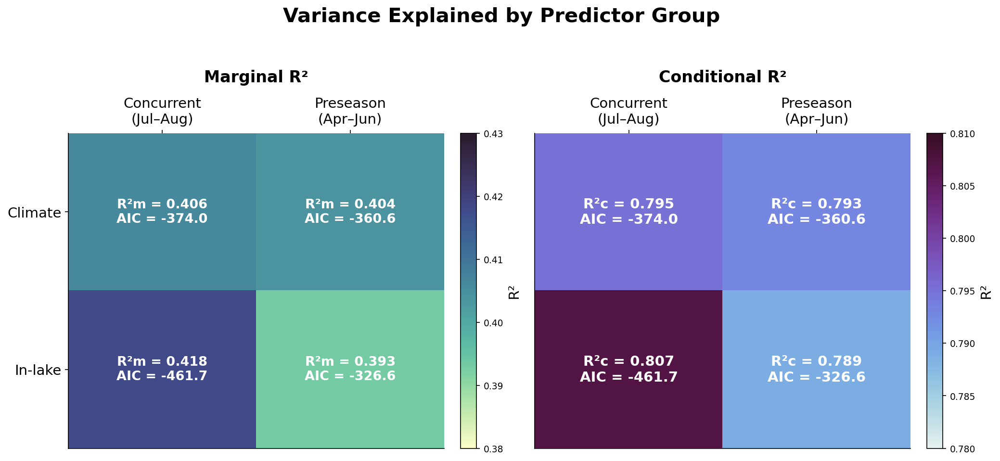

In [57]:
# Data ──────────────────────────────────────────────────────────
r2_marginal = np.array([
    [0.406, 0.404],
    [0.418, 0.393],
])

r2_conditional = np.array([
    [0.795, 0.793],
    [0.807, 0.789],
])

aic_matrix = np.array([
    [-374.0, -360.6],
    [-461.7, -326.6],
])

# Figure layout ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# LEFT: Marginal R² ─────────────────────────────────────────────
ax = axes[0]
im1 = ax.imshow(r2_marginal, cmap='cmo.deep', aspect='auto',
                vmin=0.38, vmax=0.43)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Concurrent\n(Jul–Aug)', 'Preseason\n(Apr–Jun)'], fontsize=14)

ax.set_yticks([0, 1])
ax.set_yticklabels(['Climate', 'In-lake'], fontsize=14)

ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()

ax.set_title('Marginal R²', fontsize=16, fontweight='bold', pad=15)

# annotations
for i in range(2):
    for j in range(2):
        ax.text(j, i,
                f'R²m = {r2_marginal[i,j]:.3f}\nAIC = {aic_matrix[i,j]:.1f}',
                ha='center', va='center',
                fontsize=13, fontweight='bold', color='white')

cb1 = plt.colorbar(im1, ax=ax, fraction=0.046, pad=0.04)
cb1.set_label('R²', fontsize=14)

# RIGHT: Conditional R² ─────────────────────────────────────────
ax = axes[1]
im2 = ax.imshow(r2_conditional, cmap='cmo.dense', aspect='auto',
                vmin=0.78, vmax=0.81)

ax.set_xticks([0, 1])
ax.set_xticklabels(['Concurrent\n(Jul–Aug)', 'Preseason\n(Apr–Jun)'], fontsize=14)

# REMOVE y-axis labels on right plot
ax.set_yticks([])
ax.set_yticklabels([])

ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()

ax.set_title('Conditional R²', fontsize=16, fontweight='bold', pad=15)

# annotations
for i in range(2):
    for j in range(2):
        ax.text(j, i,
                f'R²c = {r2_conditional[i,j]:.3f}\nAIC = {aic_matrix[i,j]:.1f}',
                ha='center', va='center',
                fontsize=14, fontweight='bold',
                color='white')

cb2 = plt.colorbar(im2, ax=ax, fraction=0.046, pad=0.04)
cb2.set_label('R²', fontsize=14)

# Main title ────────────────────────────────────────────────────
fig.suptitle('Variance Explained by Predictor Group',
             fontsize=20, fontweight='bold', y=1.05)

plt.tight_layout()
plt.savefig('combined_heatmap.png', bbox_inches='tight', dpi=200)
plt.show()

## Additional investigation plots

In [74]:
re_df['blup'] = [v[0] for v in result_final.random_effects.values()]
blup_col = 'blup'


Lake characteristic                            r         p  interpretation
--------------------------------------------------------------------------------
latitude                                   0.211    0.0002  * larger → more habitat
longitude                                  0.039    0.4949   larger → more habitat
lake_maxdepth_m                           -0.358    0.0000  * larger → less habitat
lake_area_ha                               0.112    0.0493  * larger → more habitat
TSI                                       -0.047    0.4158   larger → less habitat


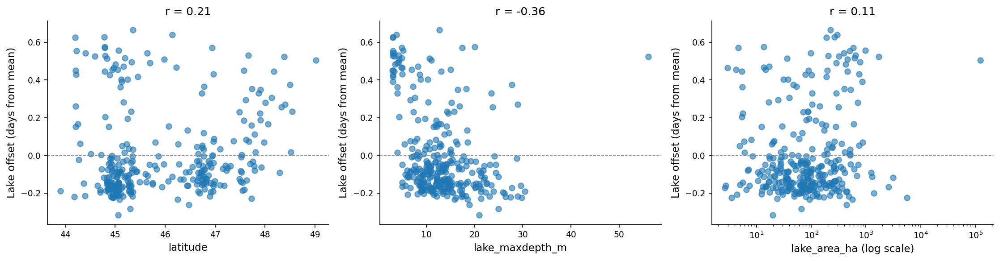

In [75]:
# Analysis 1 — Correlate BLUPs with lake characteristics

from scipy import stats as scipy_stats
import matplotlib.pyplot as plt
import seaborn as sns

print(f'\n{"Lake characteristic":<40s}  {"r":>6s}  {"p":>8s}  {"interpretation"}')
print('-' * 80)

results_a1 = []
for col in num_cols:
    valid = re_df[[col, blup_col]].dropna()
    if len(valid) < 10:
        continue

    # Spearman correlation on raw data
    r, p = scipy_stats.spearmanr(valid[col], valid[blup_col])
    sig = '*' if p < 0.05 else ''
    direction = 'larger → more habitat' if r > 0 else 'larger → less habitat'
    results_a1.append({'var': col, 'r': r, 'p': p})

    print(f'{col:<40s}  {r:>6.3f}  {p:>8.4f}  {sig} {direction}')

# Scatter plots for significant ones
sig_num = [d['var'] for d in results_a1 if d['p'] < 0.05]

if sig_num:
    fig, axes = plt.subplots(1, len(sig_num), figsize=(5*len(sig_num), 4))
    if len(sig_num) == 1:
        axes = [axes]

    for ax, col in zip(axes, sig_num):
        x = re_df[col]

        # Plot all data
        ax.scatter(x, re_df[blup_col], alpha=0.6)

        # Horizontal reference line
        ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)

        # Apply log scale ONLY for lake area
        if col == 'lake_area_ha':
            ax.set_xscale('log')
            ax.set_xlabel('lake_area_ha (log scale)')
        else:
            ax.set_xlabel(col)

        ax.set_ylabel('Lake offset (days from mean)')
        ax.set_title(f'r = {next(d["r"] for d in results_a1 if d["var"]==col):.2f}')

    plt.tight_layout()
    plt.show()